# Twelve models, seven languages: how fast is the code an AI model writes?

Ten AI coding models each wrote the same eight new programs in seven languages, working as agents that could
build and test their code: Rust, C++, Go, C#, Java, JavaScript and Python, with Python written twice (with and
without NumPy). Three models also wrote all of them again in a single reply each, with no chance to run anything.
All 832 programs gave the right answer. This notebook measures how fast, how large in memory and how long each
version was, how much of the speed depends on the language and how much on the model that wrote the program, and
what letting the model test its work adds.

## A summary that runs every morning

A web server writes one line to its access log for every request it answers: when the request arrived, which
page was asked for, whether it worked and how long the server took. A busy site writes a couple of million such
lines a day. Every morning someone wants a short summary: how many requests failed, which pages were the
busiest, and how slow the slowest answers were for each of those pages.

A short program can produce that summary. It reads the file one line at a time, checks that each line has the
expected shape, pulls out the page and the time taken, and keeps running counts. For the 2-million-line log used
in this study, a straightforward Python version takes about 7 seconds on a recent laptop.

Seven seconds is nothing for a job that runs once a day. It matters when the same work runs thousands of times: on
every file in a data pipeline, behind a dashboard, or on a cloud machine billed by the second. Memory matters in the same way, because whether a job fits in the memory of
a small machine decides whether it runs at all. The language the program is written in changes both.

## Why the same steps can take very different times

Programming languages run code in three broad ways.

Python is interpreted. A program called the interpreter reads your code and carries out each operation as it comes
to it. Before it adds two numbers it checks what kind of values they are, finds the right way to add that kind,
and creates a new object to hold the result. That flexibility makes Python quick to write, and it also means a
loop over two million log lines repeats the bookkeeping two million times.

Rust, C++ and Go are compiled ahead of time. Before the program runs, a compiler translates it into the processor's
own instructions, knowing in advance that a count is a 64-bit integer. The loop that adds up response times
becomes a few machine instructions per line. Rust and C++ leave freeing memory to the program itself; Go adds a
garbage collector, a helper that finds and frees memory the program no longer uses, which costs a little time.

Java, C# and JavaScript take a middle route. The program is first turned into a compact intermediate form. When
it starts, a virtual machine runs that form, notices which parts run most often, and compiles those parts into
machine instructions while the program runs. This is called just-in-time compilation. Long loops can then run
close to compiled speed, but the program pays to start the virtual machine and to warm it up, and all three use a
garbage collector.

Take an illustrative case, adding up a million whole numbers. Python looks up the meaning of `+` for every pair
of values and allocates a new number each time. Rust, C++ and Go keep the running total in a processor register.
Java, C# and JavaScript compile the loop after a few thousand rounds and finish at a similar pace. Nobody needs an
experiment to rank these on that loop; the useful question is how they compare on realistic work, where reading
files, splitting text and looking things up in tables also take time.

## Python's usual shortcut

Experienced Python programmers rarely write that loop. They use NumPy, a library written in C that stores a million
numbers in one compact block of memory and adds them up in one call, `values.sum()`. The loop still runs, but in
compiled code. A program written this way is still Python, yet for arithmetic on arrays it can run close to
compiled speed.

NumPy only helps when the work can be written as the same operation applied to a whole array at once. Spreading
heat across a floor plan, where every cell of a grid is updated by the same formula at each step, fits well.
Reading a line of JSON or deciding whether a log line is well formed does not: each item needs its own decisions,
and whole-array operations express decisions badly. So Python appears twice in this study, written with and
without NumPy.

## What changes when a model writes the code

The usual argument for Python and for languages with a garbage collector is that they are cheaper to write. C++
and Rust code is longer, their compilers reject more first drafts, and a developer has to know the language well
to make it fast. Teams often accept slower code because the faster version would cost too much developer time.

AI coding models change part of that calculation. Asking a model for a Rust or C++ version costs about the same as
asking for a Python version. If the model's fast-language code is correct and fast, a team gets the speed without
paying much for it. If the model writes code that is wrong, or no faster than its Python, the gain is not there.

Choosing a model is then a second decision. A team can use a large model that costs more per request, a small and
cheap one from the same company, or an open-weight model, one whose weights are published so that anyone can run
it or rent it cheaply from several hosts. All of them may write correct programs of very different speed, because
a fast program depends on choices the specification leaves open: how to read the file, what kind of table to count
words in, whether to use a general-purpose library or a few lines written for this one input format.

An illustrative case: two models are asked for the morning log summary in Go. One checks the shape of each line
with Go's regular-expression package, a general pattern matcher that is easy to get right. The other checks it by
hand, character by character, because the format is fixed. Both print the same summary. If the first takes several
times as long, the choice of model has mattered as much as the choice of language, and a comparison of languages
that used only one model would have measured that model's habits.

Published language benchmarks, built from programs that experts tuned by hand, cannot answer this. The code that
matters here is the code a model writes when it is asked.

## Two ways to ask for a program

There are two common ways to get that Go program from a model. In the first, the model works as an agent: it gets
a folder with the task description and a few sample files, and it can write code, build it, run it on the samples,
read the errors and timings, and try again until it judges the work finished. In the second, the model gets one
message with everything it needs and answers once with the program. It cannot compile or run anything, so the reply
has to be right the first time.

The agent loop has clear advantages. A model that can run its program finds its own typos and wrong answers, and it
can make a large test file and time two versions against each other. It also costs more. Models read and write text
in tokens, pieces of about three quarters of a word, and are billed per token. At every step of a session the model
reads the whole conversation so far again: the instructions, every file it opened and every command's output. In
this study GPT-6.1 Sol's sessions read about 590,000 input tokens per program; Sol answering in one reply read about
15,000.

In the log example, a model in a session can write the regular-expression version, generate a two-million-line test
log, time it, write the hand-written check, time that, and keep the faster one. In one reply it has to choose from
what it already knows. If one-reply programs are as correct and as fast as session programs, a team can get them
for a fraction of the cost; if they are not, the testing is part of what makes model-written code fast.

## The question

When ten AI coding models each write the same eight programs in Rust, C++, Go, C#, Java, JavaScript and Python
(with and without NumPy) in agent sessions, does every version give the right answer, how do the versions compare in
run time, memory, length and build time, and how much of the difference in run time comes from the language and how
much from the model? And how do programs written in a single reply, with no chance to build or test, compare?

The comparison uses eight tasks written for this study, so no model could have seen them or their answers before.
The ten session models wrote every version of every task, 640 programs: three from Anthropic (Claude Opus 5.5,
Sonnet 5.5 and Haiku 5.5, from largest to smallest), two from OpenAI (GPT-6.1 Sol and the smaller GPT-6.1 Terra),
two from Meta (Muse Wonder Full and the smaller Muse Wonder) and three open-weight models (DeepSeek V4.1 Flash, GLM
5.3 Flash and Nemotron 3.5 Super). Three models wrote all 64 programs again in one reply each, 192 programs: GPT-6.1
Sol, so that one model is measured both ways, and the most capable models of OpenAI and Anthropic, GPT-6 Astra and
Claude Fable 5.2, whose sessions would have cost the most. A straightforward Python solution of each task, written
for clarity rather than speed, is timed as "simple Python": what an ordinary Python program would take.

The answer bears on three decisions: which language to ask a model for, whether a larger model buys faster code,
and whether letting the model test its work is worth the cost.

## Study summary

Each session model worked on each task in two agent sessions (Rust and both Pythons; the other five languages), with
a precise specification and small samples, 160 sessions in all. The one-reply programs came from 192 single calls,
one per program, with no tools. Every program was run on hidden inputs, including one benchmark-sized input per task
(2 million log lines, a million JSON transactions, and so on), and timed five times, taking turns, on one laptop.

All 832 programs and the 8 simple-Python solutions gave the exact expected output on every hidden input.
Correctness sits at its ceiling, so it separates neither the languages, the models nor the two ways of writing.

A version's relative time is its run time divided by the time of the same model's fastest version on the same
task, so 1.0 is the fastest and 2.0 twice as slow. Averaged over the eight tasks (geometric mean), every model put
the language families in the same order: Rust and C++ (1.06 to 1.98 across the ten session models), Go (1.17 to
1.74), C# (1.69 to 2.27), Java (2.34 to 2.86), JavaScript (3.04 to 3.89), NumPy Python (6.8 to 13) and plain Python
(27 to 40). Rust, C++ or Go was the fastest version in all 80 task-and-model pairs, and in all 24 of the one-reply
pairs.

A model speed index compares each program with the other models' programs in the same language for the same task;
1.0 is the geometric mean of the ten session models, and lower is faster. Claude Opus 5.5's session programs were
the fastest of the ten, at **0.64** (95% interval 0.56 to 0.74), and the fastest of the ten in 36 of 64
task-and-language cells. GPT-6.1 Terra's were slowest (1.84), then Nemotron's (1.53). The other seven sat between
0.83 and 1.06, with GPT-6.1 Sol at 0.83 and open-weight DeepSeek at 0.87.

Among the six non-Python languages, the language explained **47%** of the run-time variation within a task and the
model **39%**. On the four tasks of text and table work (word pairs, JSON transactions, log lines, road network)
the model explained more than the language. With both Pythons included, the language explains 86%, because
Python's gap to the rest is larger than any difference between models.

Writing in one reply cost no correctness and, on average, little speed. Claude Fable 5.2's one-reply programs had
the lowest index of all, **0.60** (0.51 to 0.71), level with Opus's session programs (0.93 times their time, program
by program; 95% interval 0.83 to 1.04). With the model fixed, Sol's one-reply programs took **1.13** times as long as
its session programs (1.00 to 1.29) and cost USD 4.55 at list prices against about USD 11, but 9 of the 64 were more
than twice as slow. GPT-6 Astra's one-reply programs were average (0.98).

In the original situation, the morning log summary took 3.4 to 5.7 s in the session models' plain Python. Nine
session models' fastest versions took 0.37 to 0.55 s, Terra's 1.6 s and Fable's one-reply C++ 0.23 s.

The main caveats: each model wrote each program once, so one choice of parser or table can move a ratio several
times over, and only Sol wrote both ways, so Fable's and Astra's results mix the model with the method. The programs
were timed on two days; the second day's times are corrected for the laptop running 6% faster that day. A difference
under about 1.5 times between two single programs is not reliable; the family order and the model index rest on
dozens of programs each.

## Contents

1. [Setup and saved data](#1-setup-and-saved-data)
2. [The machine](#2-the-machine)
3. [The models](#3-the-models)
4. [The eight tasks](#4-the-eight-tasks)
5. [How the models wrote the programs](#5-how-the-models-wrote-the-programs)
6. [How the programs were checked and timed](#6-how-the-programs-were-checked-and-timed)
7. [Worked example: the heat task in nine versions](#7-worked-example-the-heat-task-in-nine-versions)
8. [Correctness](#8-correctness)
9. [Run time on the full inputs](#9-run-time-on-the-full-inputs)
10. [Which language was fastest](#10-which-language-was-fastest)
11. [Where NumPy helps](#11-where-numpy-helps)
12. [Language or model: which matters more](#12-language-or-model-which-matters-more)
13. [Which model wrote the fastest code](#13-which-model-wrote-the-fastest-code)
14. [Agent sessions against a single reply](#14-agent-sessions-against-a-single-reply)
15. [Start-up cost](#15-start-up-cost)
16. [Memory](#16-memory)
17. [Small inputs and start-up time](#17-small-inputs-and-start-up-time)
18. [More cores](#18-more-cores)
19. [Code size and build time](#19-code-size-and-build-time)
20. [Error analysis: slow choices, not wrong answers](#20-error-analysis-slow-choices-not-wrong-answers)
21. [Measurement quality](#21-measurement-quality)
22. [Limitations](#22-limitations)
23. [What the evidence supports](#23-what-the-evidence-supports)
24. [How the study got here](#24-how-the-study-got-here)
25. [How to reproduce](#25-how-to-reproduce)
26. [Spend](#26-spend)
27. [Future work and further reading](#27-future-work-and-further-reading)

### How the experiment runs

```mermaid
flowchart LR
    spec["8 task specs<br/>+ 3-5 small samples each"] --> s1["80 sessions: Rust, plain Python,<br/>NumPy Python (10 models x 8 tasks)"]
    spec --> s2["80 sessions: C++, Go, C#,<br/>Java, JavaScript"]
    spec --> one["192 one-reply calls<br/>(3 models x 64 programs)"]
    s1 --> progs["832 programs"]
    s2 --> progs
    one --> progs
    gen["Input generators<br/>fixed seeds"] --> hidden["Hidden inputs per task<br/>t1 (small) + full (benchmark)"]
    ref["Simple-Python reference<br/>+ independent 2nd implementation"] --> exp["Expected outputs<br/>55 inputs, all agreeing"]
    progs --> build["626 builds<br/>3 clean + 1 incremental each"]
    build --> check["Correctness: 4,755 runs<br/>samples, t1, full"]
    progs --> check
    hidden --> check
    exp --> check
    check --> time["Timing: 1 warm-up + 5 runs<br/>846 programs on full inputs"]
    time --> out["Run time, memory, start-up,<br/>size sweep, 1-16 workers"]
```

One task travels through this as follows. The heat task's spec and samples go into two fresh folders for each
session model: in the first it writes Rust and both Pythons, in the second the other five languages, testing on the
samples. For the one-reply models the same spec, the samples and an exact description of the input and output go
into eight separate prompts, one per version, and each reply's code block becomes the program. The harness builds
every compiled version with fixed settings and runs each program on a hidden small input and the hidden 400 x
400-cell benchmark grid. Outputs are compared with the expected output from the simple-Python reference, confirmed
by a second implementation. Programs that pass are timed five times on the benchmark input, taking turns with the
other programs for the task; the median time is the score.

## 1. Setup and saved data

The setup cell loads every saved result table and keeps only rows that describe the current programs and inputs:
each row carries the SHA-256 hash of the program and of the input it ran on, and a row whose hashes no longer match
is set aside, as is a correctness row replaced by a later run of the same program and an older version of a source
file (section 21 counts them). It also fixes the names, colours and marker shapes used in every figure: oranges and
browns for Rust, C++ and Go, greens for C#, Java and JavaScript, blues for NumPy and plain Python and grey for simple
Python. Models are named in full in every figure.

Two flags at the top, `RUN_SESSIONS` and `RUN_MEASUREMENTS`, are off. Turning them on would rerun the model sessions
(cached by request hash, so nothing is spent while the saved programs match) and the measurements, which take about
seven hours and replace the saved timings.

The second code cell is the drift check described in section 6: the programs were timed on two days, and that cell
measures how much faster the laptop ran on the second day and divides that day's times by the factor before any
other cell uses them.

In [1]:
# Compute and present this analysis step for the reader.
from pathlib import Path
import hashlib, json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

RUN_SESSIONS = False
RUN_MEASUREMENTS = False
if RUN_SESSIONS:
    subprocess.run([sys.executable, "-m", "bench.sessions", "run-all"], check=True)
if RUN_MEASUREMENTS:
    subprocess.run([sys.executable, "-m", "bench.measure", "all"], check=True)
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 12,
        "figure.dpi": 150,
        "savefig.dpi": 150,
        "axes.grid": True,
        "grid.alpha": 0.22,
    }
)
DATA = Path("data")
RESULTS = DATA / "results"
FIGURES = Path("figures")
DERIVED = RESULTS / "derived"
FIGURES.mkdir(exist_ok=True)
DERIVED.mkdir(exist_ok=True)
TASKS = ["springs", "wordpairs", "ledger", "logscan", "routes", "align", "heat", "walkers"]
AUTHORS = ["opus55", "sonnet", "haiku", "sol61", "terra", "wonder-full", "wonder", "deepseek", "glm", "nemotron"]
ONE_REPLY = ["sol61-oneshot", "astra-oneshot", "fable-oneshot"]  # one program per model call, no tools, no testing
ALL_AUTHORS = AUTHORS + ONE_REPLY
ONESHOT_MODEL = {"sol61-oneshot": "sol", "astra-oneshot": "astra", "fable-oneshot": "fable"}  # folder names under data/oneshot/calls
N_WORDS = {9: "nine", 10: "ten", 13: "thirteen"}
MODEL_LABELS = {
    "opus55": "Claude Opus 5.5",
    "sonnet": "Claude Sonnet 5.5",
    "haiku": "Claude Haiku 5.5",
    "sol61": "GPT-6.1 Sol",
    "terra": "GPT-6.1 Terra",
    "wonder-full": "Muse Wonder Full",
    "wonder": "Muse Wonder",
    "deepseek": "DeepSeek V4.1 Flash",
    "glm": "GLM 5.3 Flash",
    "nemotron": "Nemotron 3.5 Super VL",
    "sol61-oneshot": "GPT-6.1 Sol (one reply)",
    "astra-oneshot": "GPT-6 Astra (one reply)",
    "fable-oneshot": "Claude Fable 5.2 (one reply)",
    "opus": "Claude Opus 5.5 (heat pilot)",
    "sol": "GPT-6.1 Sol (heat pilot)",
    "reference": "Simple-Python reference",
}
SHORT = {
    "opus55": "Opus",
    "sonnet": "Sonnet",
    "haiku": "Haiku",
    "sol61": "Sol",
    "terra": "Terra",
    "wonder-full": "Wonder Full",
    "wonder": "Wonder",
    "deepseek": "DeepSeek",
    "glm": "GLM",
    "nemotron": "Nemotron",
    "sol61-oneshot": "Sol 1R",
    "astra-oneshot": "Astra 1R",
    "fable-oneshot": "Fable 1R",
}
OPEN_WEIGHT = ["deepseek", "glm", "nemotron"]
# Fixed order, labels, colours and marker shapes for the nine versions. Compiled languages are orange/brown,
# runtimes with a
# just-in-time compiler or virtual machine are green/teal, Python versions are blue/grey. Marker shape is a second cue.
VERSIONS = ["rust", "cpp", "go", "csharp", "java", "js", "fast", "plain", "simple"]
MODEL_VERSIONS = VERSIONS[:-1]  # 'simple' is the straightforward reference solution, not model-written
LANGS = ["rust", "cpp", "go", "csharp", "java", "js"]
LABELS = dict(
    rust="Rust",
    cpp="C++",
    go="Go",
    csharp="C#",
    java="Java",
    js="JavaScript",
    fast="NumPy Python",
    plain="Plain Python",
    simple="Simple Python",
)
COLORS = dict(
    rust="#D55E00",
    cpp="#E69F00",
    go="#8C510A",
    csharp="#1B7837",
    java="#5AB4AC",
    js="#66A61E",
    fast="#0072B2",
    plain="#56B4E9",
    simple="#777777",
)
MARKERS = dict(rust="D", cpp="s", go="P", csharp="o", java="v", js="^", fast="X", plain="h", simple="*")
MAIN_FILES = dict(
    rust="src/main.rs", cpp="main.cpp", java="src/Main.java", csharp="Program.cs", go="main.go", js="main.js"
)
manifest = json.loads((DATA / "inputs_manifest.json").read_text(encoding="utf-8"))["inputs"]
entries = {(x["task"], x["name"]): x for x in manifest}
machine = json.loads((DATA / "machine.json").read_text(encoding="utf-8"))
SOURCE_SUFFIXES = (
    ".py",
    ".rs",
    ".toml",
    ".cpp",
    ".cc",
    ".h",
    ".hpp",
    ".java",
    ".cs",
    ".csproj",
    ".go",
    ".mod",
    ".js",
    ".mjs",
    ".cjs",
)


def fingerprint(folder):
    """Hash of the source files of a multi-file program (same recipe as bench/measure.py)."""
    h = hashlib.sha256()
    for p in sorted(folder.rglob("*")):
        if p.is_file() and p.suffix in SOURCE_SUFFIXES and "target" not in p.parts:
            h.update(p.relative_to(folder).as_posix().encode())
            h.update(hashlib.sha256(p.read_bytes()).digest())
    return h.hexdigest()


def source_hash(author, task, variant):
    folder = DATA / "programs" / author / task
    if variant in MAIN_FILES:
        folder = folder / variant
        if not (folder / MAIN_FILES[variant]).is_file():
            return None
        if variant == "rust" and not (folder / "Cargo.toml").is_file():
            return None
        return fingerprint(folder)
    p = folder / (variant + ".py")
    return hashlib.sha256(p.read_bytes()).hexdigest() if p.is_file() else None


exclusions = []


def current_rows(df, name):
    keep = []
    for _, r in df.iterrows():
        author, task = r["author"], r["task"]
        variant = r.get("variant", "rust")
        expected_source = source_hash(author, task, variant)
        reasons = []
        if name == "loc":
            path = DATA / "programs" / author / task / r["file"]
            if not path.is_file():
                reasons.append("program missing")
            else:
                file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
                key = hashlib.sha256(json.dumps(("loc", author, task, r["file"], file_hash), sort_keys=True).encode()).hexdigest()
                if r["key"] != key:
                    reasons.append("older version of the file")
        elif expected_source is None:
            reasons.append("program missing")
        elif "source_sha256" in df and r["source_sha256"] != expected_source:
            reasons.append("source hash mismatch")
        if "input_sha256" in df:
            entry = entries.get((task, r["input"]))
            if entry is None or r["input_sha256"] != entry["sha256"]:
                reasons.append("input hash mismatch")
        keep.append(not reasons)
        if reasons:
            exclusions.append(
                dict(
                    table=name,
                    author=author,
                    task=task,
                    variant=variant,
                    input=r.get("input", ""),
                    reason=", ".join(reasons),
                )
            )
    out = df.loc[keep].copy()
    if "variant" in out:
        out.loc[out.author.eq("reference") & out.variant.eq("plain"), "variant"] = "simple"
    return out



def latest_rows(df, name, keys):
    # Timed tables retain one observation per repeat; correctness retains one per program/input/worker.
    ordered = df.sort_values("started_utc", kind="stable", na_position="first")
    superseded = ordered.duplicated(keys, keep="last")
    for _, r in ordered.loc[superseded].iterrows():
        exclusions.append(dict(table=name, author=r.get("author", ""), task=r.get("task", ""),
                               variant=r.get("variant", ""), input=r.get("input", ""),
                               reason="superseded by a later run"))
    print(f"{name}: {int(superseded.sum())} superseded rows dropped")
    return ordered.loc[~superseded].copy()

RUN_COLS = [
    "author",
    "task",
    "variant",
    "input",
    "workers",
    "status",
    "detail",
    "source_sha256",
    "input_sha256",
    "stdout",
    "stderr",
    "started_utc",
    "wall_seconds",
    "peak_working_set",
    "cpu_wall_ratio",
    "other_busy_cores",
]


def read_table(name, columns):
    path = RESULTS / (name + ".csv")
    d = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=columns)
    for col in columns:
        if col not in d:
            d[col] = pd.Series(dtype="object")
    return d


raw_correctness = read_table("correctness", RUN_COLS)
verified_sources = set()
correctness = latest_rows(current_rows(raw_correctness, "correctness"), "correctness", ["author", "task", "variant", "input", "workers"])
verified_sources = {
    (r.author, r.task, "plain" if r.variant == "simple" else r.variant, r.source_sha256)
    for r in correctness.itertuples()
}
tables = {
    name: current_rows(
        read_table(
            name,
            (
                ["author", "task", "variant", "status", "source_sha256", "clean_seconds", "incremental_seconds"]
                if name == "builds"
                else ["author", "task", "variant", "bytes", "code_lines"]
                if name == "loc"
                else RUN_COLS
            ),
        ),
        name,
    )
    for name in ["builds", "loc", "runs", "sweep", "scaling"]
}
for name in ["runs", "sweep", "scaling"]:
    tables[name] = latest_rows(tables[name], name, ["author", "task", "variant", "input", "workers", "repeat"])
baseline = latest_rows(read_table("baseline", RUN_COLS), "baseline", ["variant", "repeat"])
runs, sweep, scaling, builds, loc = (tables[x] for x in ["runs", "sweep", "scaling", "builds", "loc"])
reference_times = pd.read_csv(DATA / "reference_times.csv").drop_duplicates(["task", "name"], keep="last")
loc_summary = loc[loc.author.isin(AUTHORS)].groupby("author").agg(files=("file", "size"), bytes=("bytes", "sum")).reindex(AUTHORS)
print("Current source files and size by model (decimal kB):")
for author, row in loc_summary.iterrows():
    print(f"{MODEL_LABELS[author]}: {int(row['files'])} files, {row['bytes'] / 1000:.1f} kB")


def geom(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    return np.exp(np.log(x).mean()) if len(x) else np.nan


def savefig(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", dpi=150)
    plt.show()


def version_handles(versions=VERSIONS, ls="-"):
    return [
        Line2D(
            [0],
            [0],
            marker=MARKERS[v],
            color=COLORS[v],
            markeredgecolor="black",
            markeredgewidth=0.4,
            ms=7,
            linestyle=ls,
            label=LABELS[v],
        )
        for v in versions
    ]


def format_number(value):
    """Format finite values without scientific notation at a readable precision."""
    if not np.isfinite(value):
        return "?"
    if float(value).is_integer():
        return str(int(value))
    magnitude = abs(value)
    if magnitude >= 10:
        return f"{value:.0f}"
    if magnitude >= 1:
        return f"{value:.1f}"
    decimals = max(0, 1 - int(np.floor(np.log10(magnitude)))) if magnitude else 0
    return f"{value:.{decimals}f}".rstrip("0").rstrip(".") if decimals else f"{value:.0f}"


pd.options.display.float_format = format_number


def plain_log_axis(ax, axis="x"):
    """Label at least four visible logarithmic positions using plain numbers."""
    from matplotlib.ticker import Locator, FuncFormatter, NullLocator

    class PlainLocator(Locator):
        def tick_values(self, vmin, vmax):
            lo, hi = sorted((max(vmin, 1e-300), max(vmax, 1e-300)))
            decades = np.arange(np.floor(np.log10(lo))-1, np.ceil(np.log10(hi))+2)
            def candidates(subs):
                return np.array([m * 10.0**e for e in decades for m in subs
                                 if lo * (1-1e-10) <= m * 10.0**e <= hi * (1+1e-10)])
            ticks = candidates([1, 1.2, 1.5, 2, 3, 4, 5, 6, 7, 8] if hi/lo < 10 else [1, 2, 5])
            if len(ticks) < 4:
                ticks = candidates([1, 1.2, 1.5, 2, 3, 4, 5, 6, 7, 8])
            if len(ticks) < 4:
                ticks = np.geomspace(lo, hi, 4)
            return ticks
        def __call__(self):
            return self.tick_values(*self.axis.get_view_interval())
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_locator(PlainLocator())
    target.set_major_formatter(FuncFormatter(lambda value, position: format_number(value)))
    target.set_minor_locator(NullLocator())


def heatmap(ax, frame, fmt=None, log=False, cmap="cividis_r", label="Value (lower is better)", discrete=False):
    from matplotlib.colors import BoundaryNorm, LogNorm

    values = frame.to_numpy(dtype=float)
    masked = np.ma.masked_invalid(values)
    color_map = plt.get_cmap(cmap).copy()
    color_map.set_bad("#eeeeee")
    valid = values[np.isfinite(values) & ((values > 0) if log else True)]
    if discrete:
        norm = BoundaryNorm(np.arange(-0.5, 9.5), color_map.N)
    elif log and len(valid):
        norm = LogNorm(vmin=valid.min(), vmax=max(valid.max(), valid.min() * 1.01))
    else:
        norm = None
    image = ax.imshow(masked, aspect="auto", cmap=color_map, norm=norm)
    ax.set_xticks(
        range(len(frame.columns)), [LABELS.get(value, value) for value in frame.columns], rotation=35, ha="right"
    )
    ax.set_yticks(range(len(frame.index)), [MODEL_LABELS.get(value, value) for value in frame.index])
    ax.grid(False)
    for row in range(len(frame.index)):
        for column in range(len(frame.columns)):
            value = values[row, column]
            rgba = image.cmap(image.norm(value)) if np.isfinite(value) else (0.93, 0.93, 0.93, 1)
            rgb = np.asarray(rgba[:3])
            linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
            luminance = np.dot(linear, [0.2126, 0.7152, 0.0722])
            color = "black" if luminance > 0.179 else "white"
            ax.text(column, row, format_number(value), ha="center", va="center", fontsize=8, color=color)
    colorbar = ax.figure.colorbar(image, ax=ax, label=label, fraction=0.046, pad=0.04)
    if discrete:
        colorbar.set_ticks([0, 2, 4, 6, 8])
    elif log:
        plain_log_axis(colorbar.ax, "y")
    return image


def with_separator(frame, n_top, label="one reply, no tools"):
    """Return a display copy of frame with an empty labelled row between the first n_top rows and the rest."""
    def fmt(v):
        return format_number(v) if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) else v
    top, bottom = frame.iloc[:n_top].astype(object).map(fmt), frame.iloc[n_top:].astype(object).map(fmt)
    blank = pd.DataFrame([[""] * frame.shape[1]], index=["--- " + label + " ---"], columns=frame.columns)
    return pd.concat([top, blank, bottom])


def separator_line(ax, position=None):
    """Horizontal line between the agent-session rows and the one-reply rows of a figure."""
    ax.axhline(len(AUTHORS) - 0.5 if position is None else position, color="black", lw=2.5)


correctness: 824 superseded rows dropped


runs: 0 superseded rows dropped
sweep: 0 superseded rows dropped
scaling: 0 superseded rows dropped
baseline: 0 superseded rows dropped
Current source files and size by model (decimal kB):
Claude Opus 5.5: 64 files, 448.2 kB
Claude Sonnet 5.5: 64 files, 304.0 kB
Claude Haiku 5.5: 64 files, 372.5 kB
GPT-6.1 Sol: 64 files, 336.6 kB
GPT-6.1 Terra: 64 files, 127.5 kB
Muse Wonder Full: 64 files, 404.0 kB
Muse Wonder: 64 files, 361.9 kB
DeepSeek V4.1 Flash: 64 files, 384.1 kB
GLM 5.3 Flash: 64 files, 342.4 kB
Nemotron 3.5 Super VL: 69 files, 308.7 kB


In [2]:
# Drift check: the same Opus 5.5 programs were timed again on 2026-11-12, when four more authors were timed.
# Compared per program with the 2026-11-08 medians, the ratio shows whether the laptop was faster or slower that day.
NEW_DAY = "2026-11-12"
OLD_DAY = "2026-11-08"


def day_of(df):
    return df.started_utc.astype(str).str[:10]


anchor = latest_rows(current_rows(read_table("anchor_20261112", RUN_COLS), "anchor"), "anchor",
                     ["author", "task", "variant", "input", "workers", "repeat"])


def opus_full(df):
    return df[df.author.eq("opus55") & df.input.eq("full") & df.workers.eq(1) & df.status.eq("correct")]


first_day = opus_full(runs)
print("Opus 5.5 first-day rows by date:", day_of(first_day).value_counts().to_dict(),
      "| anchor rows by date:", day_of(opus_full(anchor)).value_counts().to_dict())
drift = pd.concat(
    [first_day.groupby(["task", "variant"]).wall_seconds.median().rename("first_day_median"),
     opus_full(anchor).groupby(["task", "variant"]).wall_seconds.median().rename("anchor_median"),
     first_day.groupby(["task", "variant"]).size().rename("first_day_runs"),
     opus_full(anchor).groupby(["task", "variant"]).size().rename("anchor_runs")], axis=1).reset_index()
drift["ratio"] = drift.anchor_median / drift.first_day_median
assert len(drift) == 64 and drift.ratio.notna().all(), len(drift)
DRIFT = geom(drift.ratio)
_drift_rng = np.random.default_rng(39)
_logs = {t: np.log(drift.loc[drift.task.eq(t), "ratio"].to_numpy()) for t in TASKS}
_boot = [np.exp(np.concatenate([_logs[t] for t in sample]).mean()) for sample in _drift_rng.choice(TASKS, size=(10000, len(TASKS)))]
DRIFT_CI = tuple(np.quantile(_boot, [0.025, 0.975]))
print(f"DRIFT (geometric mean of the 64 ratios, time on {NEW_DAY} / time on {OLD_DAY}): {DRIFT:.3f}, "
      f"95% interval {DRIFT_CI[0]:.3f} to {DRIFT_CI[1]:.3f} (8 tasks resampled 10,000 times)")
print(f"Smallest ratio {drift.ratio.min():.3f}, largest {drift.ratio.max():.3f}; "
      f"more than 10% from 1: {int(((drift.ratio - 1).abs() > 0.10).sum())} of 64; "
      f"more than 25% from 1: {int(((drift.ratio - 1).abs() > 0.25).sum())} of 64")
print("Geometric mean ratio by version:", {v: round(float(geom(drift.ratio[drift.variant.eq(v)])), 3) for v in MODEL_VERSIONS})
print("Geometric mean ratio by task:", {t: round(float(geom(drift.ratio[drift.task.eq(t)])), 3) for t in TASKS})
print("Median other_busy_cores per day, runs:", runs.groupby(day_of(runs)).other_busy_cores.median().round(2).to_dict(),
      "| anchor:", anchor.groupby(day_of(anchor)).other_busy_cores.median().round(2).to_dict())
DRIFT_BY_PROGRAM = drift.set_index(["task", "variant"]).ratio

# Put the programs timed on 2026-11-12 on the 2026-11-08 scale: measured time divided by the drift factor.
for name, table in [("runs", runs), ("sweep", sweep), ("scaling", scaling)]:
    table["wall_seconds_measured"] = table["wall_seconds"]
    new_day = day_of(table).eq(NEW_DAY)
    assert set(table.loc[new_day, "author"]) <= {"sol61", *ONE_REPLY}, set(table.loc[new_day, "author"])
    off_day = table.author.isin(["sol61", *ONE_REPLY]) & ~new_day
    table.loc[new_day, "wall_seconds"] = table.loc[new_day, "wall_seconds_measured"] / DRIFT
    print(f"{name}: {int(new_day.sum())} of {len(table)} rows adjusted ({', '.join(f'{a} {n}' for a, n in table[new_day].author.value_counts().items())}); "
          f"rows of those authors dated another day: {int(off_day.sum())}")
drift.to_csv(DERIVED / "drift_check.csv", index=False)


anchor: 0 superseded rows dropped
Opus 5.5 first-day rows by date: {'2026-11-08': 320} | anchor rows by date: {'2026-11-12': 320}


DRIFT (geometric mean of the 64 ratios, time on 2026-11-12 / time on 2026-11-08): 0.938, 95% interval 0.908 to 0.966 (8 tasks resampled 10,000 times)
Smallest ratio 0.780, largest 1.095; more than 10% from 1: 19 of 64; more than 25% from 1: 0 of 64
Geometric mean ratio by version: {'rust': 0.969, 'cpp': 0.911, 'go': 0.93, 'csharp': 0.944, 'java': 0.996, 'js': 0.915, 'fast': 0.952, 'plain': 0.895}
Geometric mean ratio by task: {'springs': 0.961, 'wordpairs': 0.942, 'ledger': 0.888, 'logscan': 0.862, 'routes': 0.975, 'align': 0.979, 'heat': 0.977, 'walkers': 0.929}
Median other_busy_cores per day, runs: {'2026-11-08': 9.65, '2026-11-12': 6.42} | anchor: {'2026-11-12': 6.37}
runs: 1280 of 4230 rows adjusted (sol61-oneshot 320, fable-oneshot 320, astra-oneshot 320, sol61 320); rows of those authors dated another day: 0
sweep: 1152 of 3852 rows adjusted (sol61-oneshot 288, astra-oneshot 288, sol61 288, fable-oneshot 288); rows of those authors dated another day: 0
scaling: 480 of 1575 rows 

The nine first models were timed on 2026-11-08; GPT-6.1 Sol's session programs and the three one-reply authors'
programs were timed on 2026-11-12. A program's time depends on the state of the machine as well as on the program,
so before comparing the two days, Claude Opus 5.5's 64 programs were timed again on the second day with the same
settings and repeats. The cell prints the comparison.

Opus's programs took 0.938 times as long on the second day as on the first (geometric mean of the 64 per-program
ratios; 95% interval 0.908 to 0.966 from resampling the tasks). The ratios ranged from 0.78 to 1.10: 19 of 64 moved
more than 10% and none more than 25%. Every version got faster on average, Java least (0.996), and logscan (0.86) and
ledger (0.89), the two tasks that read the largest files, changed most. Other programs on the machine kept a median
of 6.4 logical processors busy during the second day's runs against 9.7 during the first, which is the likely reason;
it was not tested.

The cell then divides every time measured on 2026-11-12 by 0.938 (1,280 timed runs, 1,152 size-sweep runs and 480
scaling runs, all from the four new authors) and keeps the measured value in `wall_seconds_measured`. Ratios within
one day, such as a one-reply program against the same model's session program or a speed-up over one worker, do not
change. Section 13 shows that dividing each program by the factor for its own task and language instead gives the
same speed indices, and section 21 draws the 64 ratios.

## 2. The machine

All programs ran on one laptop, so its details are part of the result. The processor mixes six performance cores,
each running two threads, with slower efficiency cores. Single-threaded programs were held to the performance cores
so that the operating system could not move them to a slower core between runs. The table lists the processor,
core counts, memory, Windows build, power plan and every toolchain's version.

In [3]:
cores = machine['cpu_sets']; top = max(x['efficiency'] for x in cores)
pcores = len({(x['group'], x['core']) for x in cores if x['efficiency'] == top})
ecores = len({(x['group'], x['core']) for x in cores if x['efficiency'] != top})
def tool_version(key, fallback):
    text = str(machine.get('toolchain_versions', {}).get(key, '')).strip()
    first = text.splitlines()[0] if text else ''
    return first if first and 'flag provided' not in text and 'not recognized' not in text else fallback
display(pd.DataFrame({'value': {'CPU': machine['cpu_name'], 'P-cores': pcores, 'E-cores': ecores,
    'RAM (GB)': round(machine['ram_bytes']/1e9, 2), 'Windows': machine['windows'], 'Windows build': machine['windows_build'],
    'Power plan': machine['active_power_plan'], 'AC power': machine['on_ac_power'], 'Python': machine['python_version'],
    'NumPy': machine['numpy_version'], 'rustc': machine['rustc_version'], 'cargo': machine['cargo_version'],
    'C++ (MSVC)': 'Visual Studio 2022 Community, vcvars64 (compiler version not recorded in machine.json)',
    'Java': tool_version('JAVA', 'not recorded') + ' | ' + tool_version('JAVAC', 'javac not recorded'),
    '.NET SDK (C#)': tool_version('DOTNET', 'not recorded'),
    'Go': tool_version('GO', 'go1.27.3 (from the toolchain folder name; the version flag failed in machine.json)'),
    'Node.js (JavaScript)': tool_version('NODE', 'not recorded'),
    'measured on (UTC)': machine['date_utc']}}))

,value
CPU,Intel(R) Core(TM) Ultra 9 185H
P-cores,6
E-cores,10
RAM (GB),34
Windows,Windows-11-10.0.26300-SP0
Windows build,26300
Power plan,Power Scheme GUID: 64a64f24-65b9-4b56-befd-5ec...
AC power,True
Python,"3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:..."
NumPy,2.2.6


## 3. The models

Ten models wrote programs in agent sessions, 640 programs in all: three from Anthropic (Claude Opus 5.5, Sonnet 5.5
and Haiku 5.5, largest to smallest), two from OpenAI (GPT-6.1 Sol and the smaller GPT-6.1 Terra), two from Meta (Muse
Wonder Full and the smaller Muse Wonder) and three open-weight models (DeepSeek V4.1 Flash, GLM 5.3 Flash and
Nemotron 3.5 Super VL). Each ran in an agent program: Claude Code (`claude -p`) for the Claude models, Codex (`codex
exec`) for Sol and Terra, Muse Code (`muse exec`) for the Muse models. The open-weight models have no agent program
of their own from their makers on this setup, so they ran inside Claude Code with its requests sent to OpenRouter
through a local proxy that pins each model to its maker's own servers and asks for high reasoning effort.

Three models wrote all 64 programs again in single replies with no tools (section 5): GPT-6.1 Sol, so that one model
is measured both ways, and GPT-6 Astra and Claude Fable 5.2, the most capable models of OpenAI and Anthropic, whose
agent sessions would have cost the most. Tables and figures mark these authors "(one reply)". Claude Opus 5.5 and
GPT-6.1 Sol also wrote the heat task in Rust and Python in the first test of the pipeline; they appear as a side
comparison in section 13.

| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| Claude Opus 5.5 | `claude-opus-5-5` | Anthropic, `claude -p` (Claude Code 2.1.296), sessions | Not published | effort high | Anthropic's largest model |
| Claude Sonnet 5.5 | `claude-sonnet-5-5` | Anthropic, `claude -p`, sessions | Not published | effort high | Anthropic's mid-size model; an original author |
| Claude Haiku 5.5 | `claude-haiku-5-5` | Anthropic, `claude -p`, sessions | Not published | effort high | Anthropic's smallest, cheapest model |
| GPT-6.1 Sol | `gpt-6.1-sol` | OpenAI, `codex exec` (codex-cli 0.160.1), sessions and one reply | Not published | reasoning effort high | OpenAI's larger model, measured both ways |
| GPT-6.1 Terra | `gpt-6.1-terra` | OpenAI, `codex exec`, sessions | Not published | reasoning effort high | OpenAI's smaller model; an original author |
| Muse Wonder Full | `muse-wonder-full-1.0` | Meta, `muse exec` (Muse Code 1.4.14), sessions | Not published | reasoning effort high | Meta's larger Muse model |
| Muse Wonder | `muse-wonder-1.0` | Meta, `muse exec`, sessions | Not published | reasoning effort high | Meta's smaller Muse model |
| DeepSeek V4.1 Flash | `deepseek/deepseek-v4.1-flash-20261017` | DeepSeek via OpenRouter, inside `claude -p`, sessions | Mixture of experts, 552B backbone (8B to 16B active) plus 196B lookup memory; mostly FP8 and 4-bit | reasoning effort high; provider pinned | Low-cost open-weight model |
| GLM 5.3 Flash | `z-ai/glm-5.3-flash-20260826` | Z.AI via OpenRouter, inside `claude -p`, sessions | Mixture of experts, 320B total, 18B active; FP8 | reasoning effort high; provider pinned | Low-cost open-weight model |
| Nemotron 3.5 Super VL | `nvidia/nemotron-3.5-super-vl-20261015` (free) | Nvidia via OpenRouter, inside `claude -p`, sessions | Mixture of experts, 120B total, 12B active; precision not stated | reasoning effort high; provider pinned | Open-weight model with a free tier |
| GPT-6 Astra | `gpt-6-astra` | OpenAI, `codex exec`, one reply | Not published | reasoning effort high; no tools | OpenAI's most capable model; one reply to limit cost |
| Claude Fable 5.2 | `claude-fable-5-2` | Anthropic, `claude -p`, one reply | Not published | effort high; no tools | Anthropic's most capable model; one reply to limit cost |
| Claude Opus 5.5 (pilot) | `claude-opus-5-5` | Anthropic, `claude -p`, sessions | Not published | effort high | Heat in Rust and Python only, pipeline test |
| GPT-6.1 Sol (pilot) | `gpt-6.1-sol` | OpenAI, `codex exec`, sessions | Not published | reasoning effort high | Heat in Rust and Python only, pipeline test |

The closed models have no dated version names, so their pinned version is the name the command-line tool accepted;
the open-weight models are pinned by OpenRouter's dated name. The cell below rebuilds the table from the saved
session and call records: the model name each tool reported (Codex reports none), the tool versions and the
settings.

In [4]:
def load_meta(author, task, kind):
    p = DATA / 'programs' / author / task / ('meta.json' if kind == 'main' else 'meta_langs.json')
    if not p.is_file(): return None
    m = json.loads(p.read_text(encoding='utf-8')); m['kind'] = kind
    return m
metas = [m for a in AUTHORS + ['opus','sol'] for t in TASKS for k in ['main','langs'] if (m := load_meta(a,t,k))]
# One-reply authors: task-level meta.json (model, cli, effort) and the cached calls (CLI version, reported model).
oneshot_metas = {a: [json.loads(p.read_text(encoding='utf-8')) for p in sorted((DATA / 'programs' / a).glob('*/meta.json'))] for a in ONE_REPLY}
oneshot_calls = {a: [json.loads(p.read_text(encoding='utf-8')) for p in sorted((DATA / 'oneshot' / 'calls' / ONESHOT_MODEL[a]).glob('*.json'))] for a in ONE_REPLY}
providers = {**dict.fromkeys(['opus55','sonnet','haiku','opus'], 'Anthropic, claude -p'), **dict.fromkeys(['terra','sol','sol61'], 'OpenAI, codex exec'), **dict.fromkeys(['wonder','wonder-full'], 'Meta, muse exec'), 'deepseek':'DeepSeek via OpenRouter, inside Claude Code (claude -p) through a local proxy', 'glm':'Z.AI via OpenRouter, inside Claude Code (claude -p) through a local proxy', 'nemotron':'Nvidia via OpenRouter (free tier), inside Claude Code (claude -p) through a local proxy'}
sizes = {'deepseek':'mixture of experts: 552B backbone parameters (8B active per token reading input, 16B writing) plus a 196B lookup memory; weights mostly FP8 and 4-bit', 'glm':'mixture of experts: 320B total, 18B active; FP8 weights', 'nemotron':'mixture of experts: 120B total, 12B active; precision of the free endpoint not stated'}
why = {'opus55':"Anthropic's largest model", 'sonnet':"Anthropic's mid-size model; an original author", 'haiku':"Anthropic's smallest and cheapest model", 'sol61':"OpenAI's larger model; first planned author", 'terra':"OpenAI's model; an original author", 'wonder-full':"Meta's larger Muse model", 'wonder':"Meta's smaller Muse model", 'deepseek':'low-cost open-weight model', 'glm':'low-cost open-weight model', 'nemotron':'open-weight model with a free tier', 'opus':'heat pilot, first planned author', 'sol':'heat pilot, first planned author',
       'sol61-oneshot':"the same model as GPT-6.1 Sol's sessions, to measure what the agent loop adds", 'astra-oneshot':"OpenAI's most capable model; one reply to limit cost", 'fable-oneshot':"Anthropic's most capable model; one reply to limit cost"}
rows=[]
def agent_row(a):
    ms=[m for m in metas if m.get('author')==a]
    def vals(k): return ', '.join(sorted({str(m[k]) for m in ms if m.get(k)})) or 'not reported'
    setting = ('reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep' if a in OPEN_WEIGHT else 'effort high; tools Bash, Read, Write, Edit, Glob, Grep' if a in ['opus55','sonnet','haiku','opus'] else 'effort high; workspace-write sandbox' if a in ['terra','sol','sol61'] else 'reasoning effort high; approvals and sandbox off (--yolo); web tools off')
    slug = sorted({m.get('request',{}).get('author',{}).get('permaslug') for m in ms if m.get('request',{}).get('author',{}).get('permaslug')})
    return {'model':MODEL_LABELS[a], 'pinned version':', '.join(slug) if slug else vals('requested_model'), 'model reported by the CLI': ', '.join(sorted({str(m['reported_model']) for m in ms if m.get('reported_model') and not str(m['reported_model']).startswith('<')})) or 'not reported', 'provider and call':providers[a], 'CLI version':vals('cli_version'), 'size and precision':sizes.get(a,'not published'), 'settings':setting+('; main prompt, heat only' if a in ['opus','sol'] else '; main and languages prompts'), 'why included':why[a]}
def one_reply_row(a):
    ms, cs = oneshot_metas[a], oneshot_calls[a]
    def uniq(items, k): return ', '.join(sorted({str(i[k]) for i in items if i.get(k)})) or 'not reported'
    cli = uniq(ms, 'cli')
    return {'model':MODEL_LABELS[a], 'pinned version':uniq(ms, 'model'), 'model reported by the CLI':uniq(cs, 'reported_model'), 'provider and call':('OpenAI, codex exec, one reply, no tools' if cli == 'codex' else 'Anthropic, claude -p, one reply, no tools'), 'CLI version':uniq(cs, 'cli_version'), 'size and precision':'not published', 'settings':'effort ' + uniq(ms, 'effort') + "; no tools; the agent's own instructions replaced by a one-line system prompt", 'why included':why[a]}
rows = [agent_row(a) for a in AUTHORS] + [one_reply_row(a) for a in ONE_REPLY] + [agent_row(a) for a in ['opus','sol']]
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(rows))


,model,pinned version,model reported by the CLI,provider and call,CLI version,size and precision,settings,why included
0,Claude Opus 5.5,claude-opus-5-5,claude-opus-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",Anthropic's largest model
1,Claude Sonnet 5.5,claude-sonnet-5-5,claude-sonnet-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",Anthropic's mid-size model; an original author
2,Claude Haiku 5.5,claude-haiku-5-5,claude-haiku-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",Anthropic's smallest and cheapest model
3,GPT-6.1 Sol,gpt-6.1-sol,not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace-write sandbox; main and languages prompts,OpenAI's larger model; first planned author
4,GPT-6.1 Terra,gpt-6.1-terra,not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace-write sandbox; main and languages prompts,OpenAI's model; an original author
5,Muse Wonder Full,muse-wonder-full-1.0,muse-wonder-full-1.0,"Meta, muse exec",Muse Code 1.4.14 (1.4.14-R7309.1),not published,reasoning effort high; approvals and sandbox off (--yolo); web tools off; main and languages prompts,Meta's larger Muse model
6,Muse Wonder,muse-wonder-1.0,muse-wonder-1.0,"Meta, muse exec",Muse Code 1.4.14 (1.4.14-R7309.1),not published,reasoning effort high; approvals and sandbox off (--yolo); web tools off; main and languages prompts,Meta's smaller Muse model
7,DeepSeek V4.1 Flash,deepseek/deepseek-v4.1-flash-20261017,deepseek/deepseek-v4.1-flash-1017,"DeepSeek via OpenRouter, inside Claude Code (claude -p) through a local proxy",2.1.296 (Claude Code),"mixture of experts: 552B backbone parameters (8B active per token reading input, 16B writing) plus a 196B lookup memory; weights mostly FP8 and 4-bit","reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",low-cost open-weight model
8,GLM 5.3 Flash,z-ai/glm-5.3-flash-20260826,z-ai/glm-5.3-flash,"Z.AI via OpenRouter, inside Claude Code (claude -p) through a local proxy",2.1.296 (Claude Code),"mixture of experts: 320B total, 18B active; FP8 weights","reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",low-cost open-weight model
9,Nemotron 3.5 Super VL,nvidia/nemotron-3.5-super-vl-20261015,nvidia/nemotron-3.5-super-vl:free,"Nvidia via OpenRouter (free tier), inside Claude Code (claude -p) through a local proxy",2.1.296 (Claude Code),"mixture of experts: 120B total, 12B active; precision of the free endpoint not stated","reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",open-weight model with a free tier


Other models helped build the study but are not measured: the task specs and this text were written by Claude Opus
5.5; the input generators, the simple-Python reference and the measurement scripts by GPT-6.1 Sol and GPT-6.1
Terra; the session runner for the seven added models and the proxy by Claude Sonnet 5.5; the one-reply runner by
GPT-6.1 Terra; this notebook's code by GPT-6.1 Terra, with the parts for Sol's sessions, the one-reply authors and
the drift correction by Claude Sonnet 5.5.

## 4. The eight tasks

The tasks cover the kinds of work people write scripts for, from pure arithmetic to text and record handling:

- **springs**: 4,000 masses joined by springs in a ring, moved for 15,000 time steps; report the energy. A
  floating-point loop.
- **wordpairs**: count how often each pair of adjacent words occurs in 10 million words of text; report the 20
  most common pairs. Text and hash tables.
- **ledger**: total a million JSON bank transactions per channel and account, with exact currency conversion.
  Parsing records.
- **logscan**: the morning log summary from the introduction, over 2 million lines. Parsing text with a pattern.
- **routes**: shortest road distances from 6 starting points in a 300,000-node network. Graph search.
- **align**: the cheapest weighted edit from one string to another, for 300 pairs. A dynamic-programming table.
- **heat**: heat spreading across a 400 x 400 floor plan for 250 steps, in exact integer arithmetic. Grid
  arithmetic.
- **walkers**: 64 random walks of 500,000 steps each, with a fixed random-number generator, spread over a given
  number of workers. Parallel simulation.

Each task has a written spec with exact input and output formats, in `bench/tasks/<task>/SPEC.md`. The inputs are
generated by code from fixed seeds, so they are new and the expected answers are exact. The first table gives the
benchmark input's size and generator settings, and the median time of the simple-Python solution on it; the second
is how long the reference took when it first generated the expected outputs.

In [5]:
work = {'springs': 'particle simulation', 'wordpairs': 'text pair counting', 'ledger': 'transaction aggregation', 'logscan': 'log parsing and aggregation', 'routes': 'shortest paths', 'align': 'sequence alignment', 'heat': 'grid simulation', 'walkers': 'parallel random walks'}
ref = runs[(runs.author == 'reference') & (runs.input == 'full')].groupby('task').wall_seconds.median()
display(pd.DataFrame([{'task': t, 'work': work[t], 'full input bytes': entries[t, 'full']['bytes'], 'parameters': json.dumps(entries[t, 'full']['parameters']), 'simple Python median (s)': ref.get(t)} for t in TASKS]))
display(reference_times.rename(columns={'wall_seconds': 'reference generation time (s)'}))

,task,work,full input bytes,parameters,simple Python median (s)
0,springs,particle simulation,380975,"{""N"": 4000, ""P"": 4000, ""S"": 15000, ""dt"": 0.0005}",16
1,wordpairs,text pair counting,65546152,"{""vocabulary"": 40000, ""words"": 10000000}",45
2,ledger,transaction aggregation,381005817,"{""accounts"": 10000, ""channels"": 8, ""currencies...",10
3,logscan,log parsing and aggregation,227676727,"{""lines"": 2000000, ""malformed_period"": 100, ""t...",6.7
4,routes,shortest paths,14809532,"{""M"": 900000, ""N"": 300000, ""Q"": 6}",11
5,align,sequence alignment,270579,"{""P"": 300, ""alphabet"": 10, ""max_length"": 1000,...",13
6,heat,grid simulation,160412,"{""H"": 400, ""S"": 250, ""W"": 400}",16
7,walkers,parallel random walks,35,"{""B"": 300, ""J"": 64, ""L"": 500000, ""SEED"": 18446...",23


,task,name,reference generation time (s)
64,springs,s1a,0.32
66,wordpairs,full,54
67,ledger,full,11
68,logscan,full,6.8
69,routes,full,11
70,align,full,20
71,heat,full,21
72,walkers,full,32
73,logscan,s2,0.17
74,springs,s1b,0.15


### A look at the data

The input generators add the awkward cases a real file would contain. The log has truncated lines, lower-case
methods and latencies missing their decimal, about 1% of lines in all, which must be counted as malformed. The JSON
transactions contain decoy fields with the same names nested inside other objects, escaped quotes and emoji written
as escape codes, so a program that searches the text for `"account"` instead of parsing the JSON gets the wrong
total. The heat floor plans mark walls with `#`, heat sources with a digit and open floor with `.`. The cell below
prints the first lines of a small sample input and its expected output for these three tasks.

In [6]:
for task in ['logscan', 'ledger', 'heat']:
    print('\n', task)
    for suffix in ['in', 'out']:
        lines = (DATA / 'samples' / task / ('s2.' + suffix)).read_text(encoding='utf-8').splitlines()
        print('s2.' + suffix)
        for line in (lines[:6] if suffix == 'in' else lines): print(line[:140] + ('…' if len(line) > 140 else ''))


 logscan
s2.in
2026-10-30T14:22:05.123Z web-17 GET
2026-10-30T14:22:05.123Z web-17 GET /service/36a/v2/?ref=abc&item=12 200 1834B 9.5ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /service/53a/v2/71170 200 1834B 9.8ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/6929 200 1834B 10.9ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /x//69521/12a 200 1834B 9.6ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/80123?ref=abc&item=12 200 1834B 39.7ms "Mozilla/5.0 (X11; Linux x86_64)"
s2.out
lines 2000
malformed 40
status 1xx 16
status 2xx 1558
status 3xx 153
status 4xx 147
status 5xx 86
path /api/v2/items/{id} 227 13.4 170.0 697.9
path /users/{id}/orders/ 149 12.8 94.2 334.4
path /x//{id}/12a 91 13.9 162.8 250.9
path /{id}/{id}/{id} 62 15.3 73.5 306.1
path /health 61 8.2 82.8 203.7
path /service/0a/v2// 54 22.9 303.9 422.4
path /service/1a/v2/{id} 42 14.5 123.2 1014.3


The first logscan output line counts all 2,000 lines of the sample, the second the malformed ones (the first sample
line is a truncated request). A `path` line such as `path /api/v2/items/{id} 227 13.4 170.0 697.9` says the page
template `/api/v2/items/{id}` (any numeric item id) was requested 227 times, with a median latency of 13.4 ms, a
95th percentile of 170.0 ms and a maximum of 697.9 ms. The ledger line shows a decoy `extra` object holding its own
`account`, `tags` and `type` fields, which a correct program ignores.

## 5. How the models wrote the programs

Each session model ran as an agent: a loop in which it reads files, writes code, runs commands such as a build or a test on
a sample, reads the results and decides what to do next, until it judges the work finished. Each model had two
sessions per task, in fresh folders outside the repository and without access to each other: one for Rust and the
two Pythons (`bench/AUTHOR_PROMPT.md`), and one for C++, Go, C#, Java and JavaScript
(`bench/AUTHOR_PROMPT_LANGS.md`). All ten session models got the same prompts and starting files.

```mermaid
flowchart TD
    p["Prompt + SPEC.md + samples/<br/>+ starting project per language"] --> m["Model, effort high<br/>Claude models via claude -p; Sol and Terra via codex exec;<br/>Muse models via muse exec; open-weight models<br/>inside claude -p, routed to OpenRouter by a local proxy"]
    m -->|"writes code, runs a command"| t["Shell in the task folder<br/>build scripts, test runs on samples"]
    t -->|"output, errors, timings"| m
    m -->|"judges the work done"| out["source files<br/>+ a short summary"]
```

The two prompts share their key instructions:

> Every version must print the correct output for any valid input as SPEC.md defines it, not only for the
> samples. Make each version as fast as you can. Write each one the way a skilled developer in that language
> would write fast code, using that language's own strengths. Use a single thread and a single process unless
> SPEC.md says otherwise.

Every version was limited to its language's standard library, plus the library a developer would usually reach for
where the standard library lacks JSON or regular expressions: serde, serde_json, regex and rayon for Rust,
nlohmann/json 3.12 for C++, Jackson 2.22 for Java, NumPy 2.2 for the NumPy version. They were downloaded in advance
so builds work offline. Compilers and build settings were fixed by the harness: Rust 1.99 in release mode (the
model could change the release profile), Microsoft Visual C++ 19.40 with `/O2 /GL /EHsc /std:c++20`, Go 1.27.3,
.NET 8 in Release mode (the model could change project properties), Java 23 with default JVM settings, Node.js
22.17 and Python 3.13.5.

Asking for the fastest version matters for reading the results. A model's "plain Python" is Python written for
speed, which can be far from Python written in a hurry; the simple-Python reference shows the other end.

The cell below summarises each model's 16 sessions: their length, tool calls (each command, file read or edit is one
call), output tokens (code, messages and reasoning), cost, sessions that hit the 75-minute limit, and sessions that
ended in a harness failure and were run again. The figure shows every session's duration and output tokens.

,sessions,total_minutes,median_minutes,median_tool_calls,total_output_tokens,total_cost,total_list_cost,cost_basis,timed_out,harness_failures
author,,,,,,,,,,
opus55,16,306,19,59,1011499,40,NaN,Claude Code list-price estimate,0,5
sonnet,16,115,5.1,19,448357,7.9,NaN,Claude Code list-price estimate,0,0
haiku,16,270,15,47,1300810,2.7,NaN,Claude Code list-price estimate,0,5
sol61,16,325,16,44,560284,NaN,11,Codex subscription (tokens only),0,0
terra,16,52,3.3,11,101632,NaN,1.2,Codex subscription (tokens only),0,0
wonder-full,16,311,13,40,621778,NaN,NaN,Muse subscription (tokens only),0,6
wonder,16,143,8.6,36,499788,NaN,NaN,Muse subscription (tokens only),0,6
deepseek,16,271,17,62,1212917,8.0,NaN,OpenRouter charge,0,9
glm,16,483,28,66,877314,2.2,NaN,OpenRouter charge,1,11


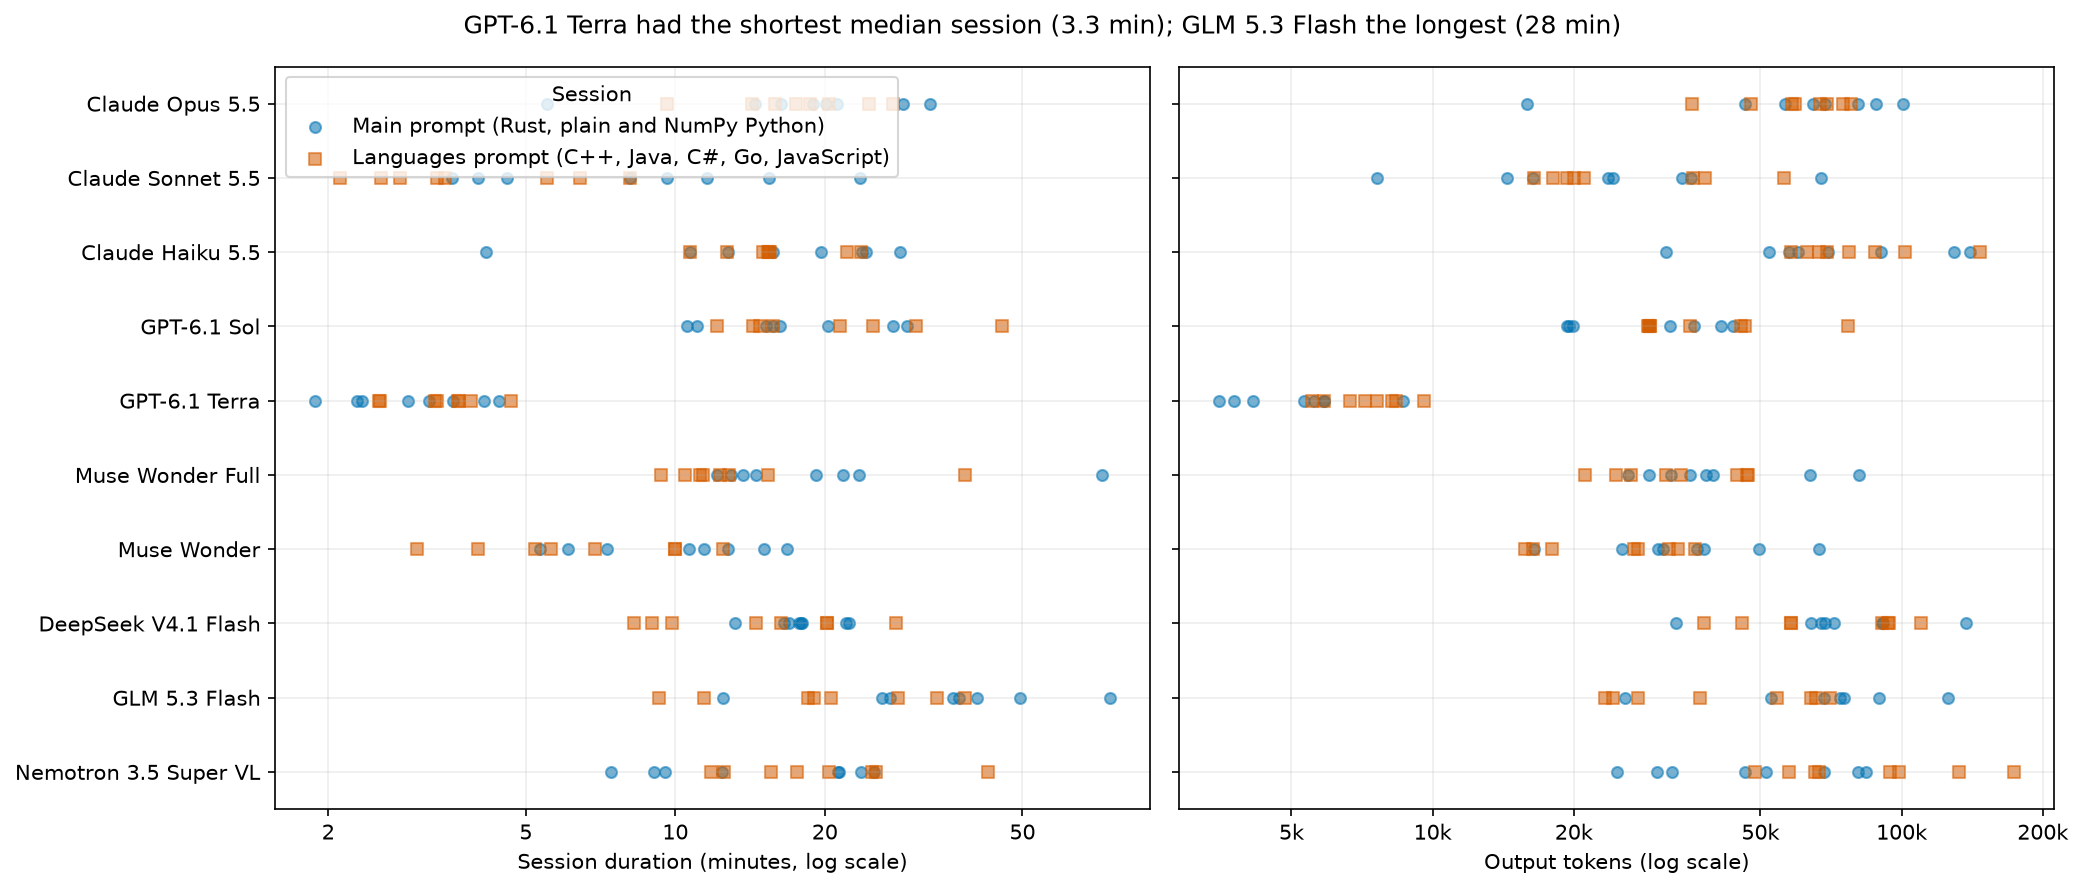

In [7]:
# Compute and present this analysis step for the reader.
CODEX_LIST_PRICES = {  # USD per million tokens: (input not cached, cached input, output); Codex output includes reasoning
    "gpt-6.1-sol": (2.00, 0.10, 10.00),
    "gpt-6.1-terra": (1.00, 0.05, 5.00),
}
CODEX_MODEL = {"sol61": "gpt-6.1-sol", "sol": "gpt-6.1-sol", "terra": "gpt-6.1-terra"}


def session_row(m):
    # Claude Code counts uncached, cache-read and cache-creation input separately; Codex and Muse report
    # total input directly.
    a = m.get("author")
    u = m.get("usage") or {}
    router = m.get("openrouter") or {}
    list_cost = np.nan
    if a in ["terra", "sol", "sol61"]:
        inp = u.get("input_tokens")
        cached = u.get("cached_input_tokens")
        reasoning = u.get("reasoning_output_tokens")
        basis = "Codex subscription (tokens only)"
        cost = np.nan
        if inp is not None and u.get("output_tokens") is not None:
            p_in, p_cached, p_out = CODEX_LIST_PRICES[CODEX_MODEL[a]]
            list_cost = ((inp - (cached or 0)) * p_in + (cached or 0) * p_cached + u["output_tokens"] * p_out) / 1e6
    elif a in ["wonder", "wonder-full"]:
        inp = u.get("input_tokens")
        cached = u.get("cached_tokens")
        reasoning = u.get("reasoning_tokens")
        basis = "Muse subscription (tokens only)"
        cost = np.nan
    else:
        inp = sum(u.get(k, 0) or 0 for k in ["input_tokens", "cache_read_input_tokens", "cache_creation_input_tokens"])
        cached = u.get("cache_read_input_tokens")
        reasoning = (u.get("output_tokens_details") or {}).get("thinking_tokens")
        reasoning = reasoning if reasoning is not None else (router.get("usage") or {}).get("thinking_tokens")
        basis = "OpenRouter charge" if a in OPEN_WEIGHT else "Claude Code list-price estimate"
        cost = router.get("cost_usd") if a in OPEN_WEIGHT else m.get("cost_usd")
    return dict(
        author=a,
        model=MODEL_LABELS.get(a, a),
        task=m.get("task"),
        kind=m.get("kind", "failed"),
        minutes=(m.get("wall_seconds") or 0) / 60,
        turns=m.get("turns"),
        tool_calls=m.get("tool_calls"),
        all_input_tokens=inp,
        cached_input_tokens=cached,
        output_tokens=u.get("output_tokens"),
        reasoning_tokens=reasoning,
        cost_usd=cost,
        list_cost_usd=list_cost,
        cost_basis=basis,
        exit_code=m.get("exit_code"),
        timed_out=m.get("timed_out", False),
        missing=len(m.get("missing") or []),
    )


cols = [
    "author",
    "model",
    "task",
    "kind",
    "minutes",
    "turns",
    "tool_calls",
    "all_input_tokens",
    "cached_input_tokens",
    "output_tokens",
    "reasoning_tokens",
    "cost_usd",
    "list_cost_usd",
    "cost_basis",
    "exit_code",
    "timed_out",
    "missing",
]
sessions = pd.DataFrame([session_row(m) for m in metas], columns=cols)
failed_meta = []
for a in AUTHORS + ["opus", "sol"]:
    for p in (DATA / "failed_sessions" / a).glob("*.meta.json"):
        m = json.loads(p.read_text(encoding="utf-8"))
        m.setdefault("author", a)
        m["kind"] = "failed"
        failed_meta.append(m)
failed_sessions = pd.DataFrame([session_row(m) for m in failed_meta], columns=cols)
sessions.to_csv(DERIVED / "sessions.csv", index=False)
summary = sessions.groupby("author").agg(
    sessions=("task", "size"),
    total_minutes=("minutes", "sum"),
    median_minutes=("minutes", "median"),
    median_tool_calls=("tool_calls", "median"),
    total_output_tokens=("output_tokens", lambda x: x.sum(min_count=1)),
    total_cost=("cost_usd", lambda x: x.sum(min_count=1)),
    total_list_cost=("list_cost_usd", lambda x: x.sum(min_count=1)),
    cost_basis=("cost_basis", "first"),
    timed_out=("timed_out", "sum"),
)
summary["harness_failures"] = failed_sessions.groupby("author").size()
summary["harness_failures"] = summary.harness_failures.fillna(0).astype(int)
display(summary.reindex(AUTHORS + ["opus", "sol"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for i, a in enumerate(AUTHORS):
    for kind, marker in [("main", "o"), ("langs", "s")]:
        d = sessions[(sessions.author == a) & (sessions.kind == kind)]
        for ax, col in zip(axes, ["minutes", "output_tokens"]):
            x = pd.to_numeric(d[col], errors="coerce")
            x = x[x > 0]
            ax.scatter(
                x,
                [i] * len(x),
                marker=marker,
                color={"main": "#0072B2", "langs": "#D55E00"}[kind],
                alpha=0.55,
                s=28,
                label={"main": "Main prompt (Rust, plain and NumPy Python)", "langs": "Languages prompt (C++, Java, C#, Go, JavaScript)"}[kind] if i == 0 else None,
            )
for ax, label in zip(axes, ["Session duration (minutes, log scale)", "Output tokens (log scale)"]):
    ax.set(
        xscale="log",
        xlabel=label,
        yticks=range(len(AUTHORS)),
        yticklabels=[MODEL_LABELS[a] for a in AUTHORS],
        ylim=(len(AUTHORS) - 0.5, -0.5),
    )
    plain_log_axis(ax)
from matplotlib.ticker import FuncFormatter
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1000:g}k" if x >= 1000 else format_number(x)))
meds = summary.reindex(AUTHORS).median_minutes.dropna()
fig.suptitle(
    f"{MODEL_LABELS[meds.idxmin()]} had the shortest median session ({format_number(meds.min())} "
    f"min); {MODEL_LABELS[meds.idxmax()]} the longest ({format_number(meds.max())} min)"
    if len(meds)
    else "Session effort: no sessions available"
)
axes[0].legend(title="Session")
fig.tight_layout()
savefig("session_effort.png")


The models worked very differently. GPT-6.1 Terra's sessions were the shortest (median 3.3 minutes, 11 tool calls,
0.10 million output tokens over 16 sessions) and Claude Sonnet 5.5's next (5.1 minutes, 19 calls). GLM 5.3 Flash's
were the longest (median 28 minutes), and Nemotron made the most tool calls (median 101). GPT-6.1 Sol's sessions
took a median of 16 minutes and 44.5 tool calls. Claude Code's list-price estimates put the 16 sessions at USD 40 for
Opus, 7.9 for Sonnet and 2.7 for Haiku; OpenRouter charged USD 8.0 for DeepSeek and 2.2 for GLM; Nemotron ran on a
free tier; Sol, Terra and the Muse models ran on subscriptions that report tokens only. At OpenAI's list prices Sol's
16 sessions would have cost about USD 11 and Terra's about USD 1.2. One GLM session reached the 75-minute limit with all its files written and was measured as written.

The harness-failure column counts sessions that ended for reasons outside the model and were run again from scratch,
55 in all: C++ builds broken by an overlong PATH after the desktop app restarted, Nemotron's free tier running out of
daily requests, OpenRouter credits running out, the laptop going to sleep, and two crashes of the agent programs.
The failed runs are kept in `data/failed_sessions/`; `data/PROTOCOL.md` lists each. Section 13 asks whether longer
sessions bought faster code.

### Writing a program in one reply

The one-reply authors got a single request per program and gave a single answer. Claude Code ran with its tools
switched off (`--tools ""`) and Codex in a read-only sandbox, both with their own agent instructions replaced by one
line: "You are a programmer. Answer each request in a single reply. You cannot run code or use tools." All 192 calls
recorded no tool use.

```mermaid
flowchart LR
    p["One prompt per program (about 6,000 characters):<br/>toolchain and build command, run command,<br/>output rules, task spec, exact input and output,<br/>samples up to 2 kB with expected output"] --> m["One model call, no tools<br/>Sol and Astra: codex exec; Fable: claude -p<br/>effort high"]
    m --> r["Reply: one fenced code block<br/>with the whole source file"]
    r --> x["Harness extracts the file,<br/>adds the project files a session would have"]
    x --> c["Build, samples, hidden inputs"]
    c --> t["Timing with the session programs"]
```

Because the model cannot test anything, the prompt (`bench/ONESHOT_PROMPT_V2.md`) is more explicit than the session
prompt. It names the compiler version and the rules that most often break a first build ("a reference to a `static
mut` is a compile error" in Rust 2024), the exact command line and argument list, that integers are printed in plain
decimal, and a short contract for each task, written for this design, that repeats the points a first draft most
often gets wrong; for heat, "a neighbour that is a wall, or that lies outside the grid, contributes the updating
cell's own old value". Samples of up to 2,000 bytes go into the prompt with their expected outputs. The harness cuts
the program out of the reply's one code block and adds the project files an agent session would have left
(`Cargo.toml`, `go.mod`, `solution.csproj`), so the program is built and run exactly like a session program.

A first version of this prompt, without the per-task contracts, was tried on heat and ledger by Claude Haiku 5.5,
Claude Sonnet 5.5, GPT-6.1 Sol and GPT-6.1 Terra: 8 of the 64 programs failed (four of Haiku's, three of Sonnet's and
one of Terra's; all of Sol's passed). The contracts were written in response; those test programs are not used.

The next cell prints one cached call in full: Claude Fable 5.2 writing heat in Rust. It shows the system prompt and
the command-line flags, the whole prompt, the start of the reply, a check that the program cut from the reply is the
file that was built and timed, and the call's token use and cost.

In [8]:
# One cached one-reply call in full: Claude Fable 5.2 writing the heat task in Rust.
call = json.loads((DATA / "oneshot" / "calls" / "fable" / "heat.rust.json").read_text(encoding="utf-8"))
request = call["request"]
print("System prompt:", request["system"])
print("CLI flags:", " ".join(request["flags"]))
print(f"Prompt length: {len(request['prompt'])} characters")
print("Prompt text:\n" + request["prompt"])
print("\nFirst 25 lines of the raw reply:")
print("\n".join(call["reply"].splitlines()[:25]))


def extract_code(reply):
    """The longest fenced code block of a reply, with one trailing newline (the same rule the harness used)."""
    import re
    blocks = re.findall(r"(?ms)^[ \t]*(`{3,}|~{3,})[^\n]*\n(.*?)^[ \t]*\1[ \t]*(?:\n|$)", reply.replace("\r\n", "\n"))
    return max((b[1] for b in blocks), key=len).rstrip("\n") + "\n" if blocks else None


saved = (DATA / "programs" / "fable-oneshot" / "heat" / "rust" / "src" / "main.rs").read_bytes()
extracted = extract_code(call["reply"]).encode("utf-8")
print(f"\nExtracted program: {len(extracted)} bytes, sha256 {hashlib.sha256(extracted).hexdigest()}")
print(f"Saved main.rs: {len(saved)} bytes, sha256 {hashlib.sha256(saved).hexdigest()}")
print("identical:", extracted == saved)
usage = call["usage"]
print(f"\nUsage: input {usage['input_tokens'] + usage['cache_read_input_tokens'] + usage['cache_creation_input_tokens']} tokens "
      f"(cached {usage['cache_read_input_tokens']}, written to cache {usage['cache_creation_input_tokens']}), "
      f"output {usage['output_tokens']}, thinking {usage['output_tokens_details']['thinking_tokens']}")
print(f"Wall time {call['wall_seconds']:.1f} s; list-price cost USD {call['list_cost_usd']:.3f}; Claude Code reported USD {call['cli_cost_usd']:.3f}")


System prompt: You are a programmer. Answer each request in a single reply. You cannot run code or use tools.
CLI flags: -p --safe-mode --model claude-fable-5-2 --effort high --tools  --system-prompt You are a programmer. Answer each request in a single reply. You cannot run code or use tools. --no-session-persistence --output-format stream-json --verbose
Prompt length: 5745 characters
Prompt text:
Write one complete Rust program for the task below. It will be compiled and run automatically with no
human in the loop, and judged first on whether its output is exactly right and then on how fast it runs.

## The program

- File: `src/main.rs`, the only source file of a Cargo binary package named `solution`.
- Toolchain: Rust 1.99 stable, edition 2024, built with `cargo build --release --offline`. `Cargo.toml` is fixed and has no `[profile.release]` section.
- Libraries: the standard library, plus only these crates, which are already declared: `serde` 1 (with the `derive` feature), `serde_

The prompt is 5,745 characters: the toolchain block, the run command, the output rules, the heat spec, the contract
and two samples with their expected outputs. Fable spent 233 seconds and wrote 22,171 output tokens, 18,976 of them
reasoning that is not part of the answer, then replied with one code block, a 7,721-byte program identical to the
saved `main.rs`. It holds each cell in a 16-bit number and uses the processor's AVX2 instructions to update 16 cells
at once, after rewriting the update formula so that no intermediate sum exceeds 16 bits. The program passed the five heat inputs and ran the benchmark grid in 0.044 s, against 0.037 s for
Opus's session program and 0.054 s for Sonnet's. The call cost USD 0.93 at list prices; Claude Code reported USD
0.58, because it prices Fable 5.2 at older rates.

## 6. How the programs were checked and timed

For each task a straightforward reference solution produced the expected output for every input, and a second
solution written a different way had to agree before the input was used; all 55 inputs agreed. A program's output is
compared field by field with the expected output. A failure would be sorted into one of several kinds: the program
did not build, crashed, ran out of time, wrote output that cannot be read in the required format, or wrote readable
output with a wrong value. Only the last kind is a wrong answer. For the spring simulation, which uses floating-point
numbers, values within one part in a billion count as equal.

Every correct program ran once to warm up the disk cache and then five more times on the benchmark input, taking
turns in a shuffled order with the other programs for the same task timed that day. The score is the median of the
five wall-clock times, from starting the program to its exit, as a user would wait for it, including starting the
runtime, reading the input and printing the answer. Single-threaded programs were held to the six performance cores;
their garbage collectors and just-in-time compilers could still use helper threads there. The timing ran on mains
power, with a guard that waits for mains power and discards any run during which the computer slept or was
suspended; none was discarded. Peak memory is the largest amount of physical memory the program held at once
(Windows calls it the peak working set), in megabytes of a million bytes.

The timing took two days: the first nine models' programs on 2026-11-08, Sol's session programs and the one-reply
programs on 2026-11-12. On the second day Opus 5.5's programs were timed again; they took 0.94 times as long as on the
first day, so every second-day time is divided by 0.94 before it is compared with the first day (section 1).

Three ratios summarise the times. Relative time compares the versions one model wrote for one task: with a fastest
version at 0.46 s, a version taking 0.92 s has relative time 2.0. A speed-up compares two versions directly: a
Python time of 3.1 s and a Rust time of 0.46 s give 3.1 / 0.46 = 6.8x. The model speed index compares programs for
one task in one language: each program's time is divided by the geometric mean of the ten session models' times, so
0.5 means twice as fast as a typical session model's program and 2.0 twice as slow. The one-reply programs are
divided by the same mean, so they sit on the same scale.

Averages over tasks use the geometric mean (multiply the ratios and take the root), because an ordinary average lets
one large ratio dominate: for ratios of 2 and 50, the ordinary average is 26, the geometric mean 10. The 95%
intervals come from resampling the eight tasks with replacement 10,000 times, so they show how much an average
depends on which tasks were chosen.

## 7. Worked example: the heat task in nine versions

The heat task describes a floor plan of 400 x 400 cells. Open cells start at 0, heat sources hold a fixed value, and
at each of 250 steps every open cell becomes `(4 * old + up + down + left + right) // 8`, where a neighbour that is
a wall, or lies outside the grid, contributes the cell's own old value. The answer is the sum of the open cells, the
hottest cell and a checksum, in exact integer arithmetic.

This example follows Claude Sonnet 5.5's nine versions. Sonnet spent 3.5 minutes on Rust and the Pythons and 3.4
minutes on the other five languages. In every compiled and virtual-machine language it used one plan: add a border
of walls so every cell has its neighbours at fixed distances in memory, and update the grid as one flat array with
no branches. The next cell defines two helpers (`show_code` prints numbered lines of a saved program; `show_run`
prints its correctness checks and timing summary), and the cell after it prints the C++ version's update loop:

In [9]:
SHOW_PATHS = {'rust': 'rust/src/main.rs', 'cpp': 'cpp/main.cpp', 'java': 'java/src/Main.java', 'csharp': 'csharp/Program.cs',
              'go': 'go/main.go', 'js': 'js/main.js', 'plain': 'plain.py', 'fast': 'fast.py', 'simple': 'plain.py'}
def show_code(author, task, variant, start, end):
    author = 'reference' if variant == 'simple' else author
    path = DATA / 'programs' / author / task / SHOW_PATHS[variant]
    for i, line in enumerate(path.read_text(encoding='utf-8').splitlines(), 1):
        if start <= i <= end: print(f'{i:4}  {line}')
def show_run(author, task, variant, input):
    c = correctness[(correctness.author==author)&(correctness.task==task)&(correctness.variant==variant)&(correctness.input==input)]
    c = c[['workers','status','detail','stdout']].copy(); c['stdout'] = c.stdout.fillna('').astype(str).str[:200]; display(c)
    t = pd.concat([runs,sweep,scaling],ignore_index=True)
    t = t[(t.author==author)&(t.task==task)&(t.variant==variant)&(t.input==input)]
    display(t.groupby('workers').wall_seconds.agg(['count','median','min','max']))

In [10]:
show_code('sonnet', 'heat', 'cpp', 9, 14)

   9  static void step(const int* __restrict a, int* __restrict b, const int* __restrict c, const int* __restrict m,
  10                   long long lo, long long hi, long long w2) {
  11      for (long long i = lo; i < hi; i++) {
  12          b[i] = (c[i] * a[i] + ((a[i - 1] + a[i + 1] + a[i - w2] + a[i + w2]) & m[i])) >> 3;
  13      }
  14  }


Here `a` is the grid at the start of the step and `b` the new one, `w2` the padded row width (so `a[i - w2]` is the
cell above), `c[i]` is 4 plus the number of wall or outside neighbours (walls hold 0, so the cell's own value is
counted once for each), and `m[i]` keeps the neighbour sum for open cells and zeroes it for walls and sources.
Because the loop reads memory in order with fixed offsets, the compiler can process several cells per instruction.

The NumPy version does the same arithmetic on whole shifted copies of the grid, one array operation per term:

In [11]:
show_code('sonnet', 'heat', 'fast', 30, 39)

  30      for _ in range(steps):
  31          mul(cur[1:-1, 1:-1], coef, out=tmp)
  32          add(tmp, cur[:-2, 1:-1], out=tmp)
  33          add(tmp, cur[2:, 1:-1], out=tmp)
  34          add(tmp, cur[1:-1, :-2], out=tmp)
  35          add(tmp, cur[1:-1, 2:], out=tmp)
  36          rsh(tmp, 3, out=tmp)
  37          band(tmp, mask, out=tmp)
  38          bor(tmp, fixed, out=nxt[1:-1, 1:-1])
  39          cur, nxt = nxt, cur


The plain-Python version could not use NumPy, and a loop over 160,000 cells for 250 steps takes many seconds (the
simple reference loop takes 16 s). Instead it packs the whole grid into one Python integer, 24 bits per cell, and
moves every cell's neighbours into place with shifts of that one huge number. Python's integers can be any size,
and the interpreter does arithmetic on them in compiled code, so each step is a handful of operations on a number
with about 3.8 million bits:

In [12]:
show_code('sonnet', 'heat', 'plain', 55, 67)

  55  
  56      X = pack(vals)
  57      # keep result: divide by 8 leaves 3 stray bits in the top of each lane
  58      keep = pack(openm) & int.from_bytes(bytes((255, 255, 31)) * n, "little")
  59      F = pack(fixed)
  60      W0, W1, W2, W3 = (pack(a) for a in wall)
  61      # a source cell contributes its own value to wall-adjacent neighbours too,
  62      # which the wall masks handle because X holds the source value.
  63      up_sh = wp * L
  64      for _ in range(steps):
  65          s = (X << 2) + (X << up_sh) + (X >> up_sh) + (X << L) + (X >> L)
  66          s += (X & W0) + (X & W1) + (X & W2) + (X & W3)
  67          X = ((s >> 3) & keep) | F


The next cell shows, for the simple reference and all eight of Sonnet's versions, the correctness check on the
benchmark grid (status and the start of the output) and the five timed runs (count, median, fastest and slowest).

In [13]:
for author, variant in [('reference', 'simple')] + [('sonnet', v) for v in ['cpp', 'rust', 'csharp', 'go', 'java', 'js', 'fast', 'plain']]:
    print(author, variant)
    show_run(author, 'heat', variant, 'full')

reference simple


,workers,status,detail,stdout
1476,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,16,14,17


sonnet cpp


,workers,status,detail,stdout
4673,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.051,0.048,0.061


... (17 outputs left out)

,count,median,min,max
workers,,,,
1,5,0.39,0.35,0.54


sonnet plain


,workers,status,detail,stdout
1453,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.87,0.85,1.2


All nine printed the same `sum`, `max` and `checksum` lines. The medians are 0.051 s for C++, 0.054 s for Rust,
0.104 s for C#, 0.109 s for Go, 0.207 s for Java, 0.221 s for JavaScript, 0.392 s for NumPy, 0.867 s for the
packed-integer plain Python and 15.8 s for the simple loop. Relative to C++, the fastest, that is 1.1 for Rust, 2.0
for C#, 2.1 for Go, 4.1 for Java, 4.3 for JavaScript, 7.7 for NumPy, 17 for plain Python and 310 for simple Python.
On this short task much of each time is start-up: an empty C++ program takes 0.03 s to start and exit on this
machine, an empty Java program 0.11 s (section 15). The packing trick made the standard-library Python 18 times
faster than the simple loop, which shows how far Python written for speed can be from Python written in a hurry.

The other nine session models wrote the same task with other plans. Their C++ took from 0.038 s (Opus) to 0.184 s
(Nemotron), and their plain Python from 0.47 s (Opus, also packed) to 9.8 s (GLM, a loop over cells). Section 20
shows the GLM loop next to the packed versions.

## 8. Correctness

The first table shows, for each author (the ten session models, then the three one-reply authors below a line) and
version, how many of the eight tasks the program passed: `8/8` means it
printed the expected output on the hidden small input and on the benchmark input for every task (for walkers, also
with every worker count tested), and a letter would mark a failure kind. The next tables list every failed run (none)
and count statuses per model, with readable failures and unreadable or format failures apart. The figure draws the
same grid.

variant,Rust,C++,Go,C#,Java,JavaScript,NumPy Python,Plain Python,Total
Claude Opus 5.5,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Claude Sonnet 5.5,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Claude Haiku 5.5,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
GPT-6.1 Sol,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
GPT-6.1 Terra,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Muse Wonder Full,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Muse Wonder,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
DeepSeek V4.1 Flash,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
GLM 5.3 Flash,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Nemotron 3.5 Super VL,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64


,author,task,variant,input,workers,status,detail,stderr


status,correct,wrong,unreadable,crashed,timeout,build_failed,disallowed_dependency,missing,out_of,readable_accuracy,unreadable_type_failures
Claude Opus 5.5,64,0,0,0,0,0,0,0,64,1,0
Claude Sonnet 5.5,64,0,0,0,0,0,0,0,64,1,0
Claude Haiku 5.5,64,0,0,0,0,0,0,0,64,1,0
GPT-6.1 Sol,64,0,0,0,0,0,0,0,64,1,0
GPT-6.1 Terra,64,0,0,0,0,0,0,0,64,1,0
Muse Wonder Full,64,0,0,0,0,0,0,0,64,1,0
Muse Wonder,64,0,0,0,0,0,0,0,64,1,0
DeepSeek V4.1 Flash,64,0,0,0,0,0,0,0,64,1,0
GLM 5.3 Flash,64,0,0,0,0,0,0,0,64,1,0
Nemotron 3.5 Super VL,64,0,0,0,0,0,0,0,64,1,0


agent-session programs: 640 of 640 correct
one-reply programs: 192 of 192 correct
references: 8 of 8 correct
heat-pilot programs: 6 of 6 correct


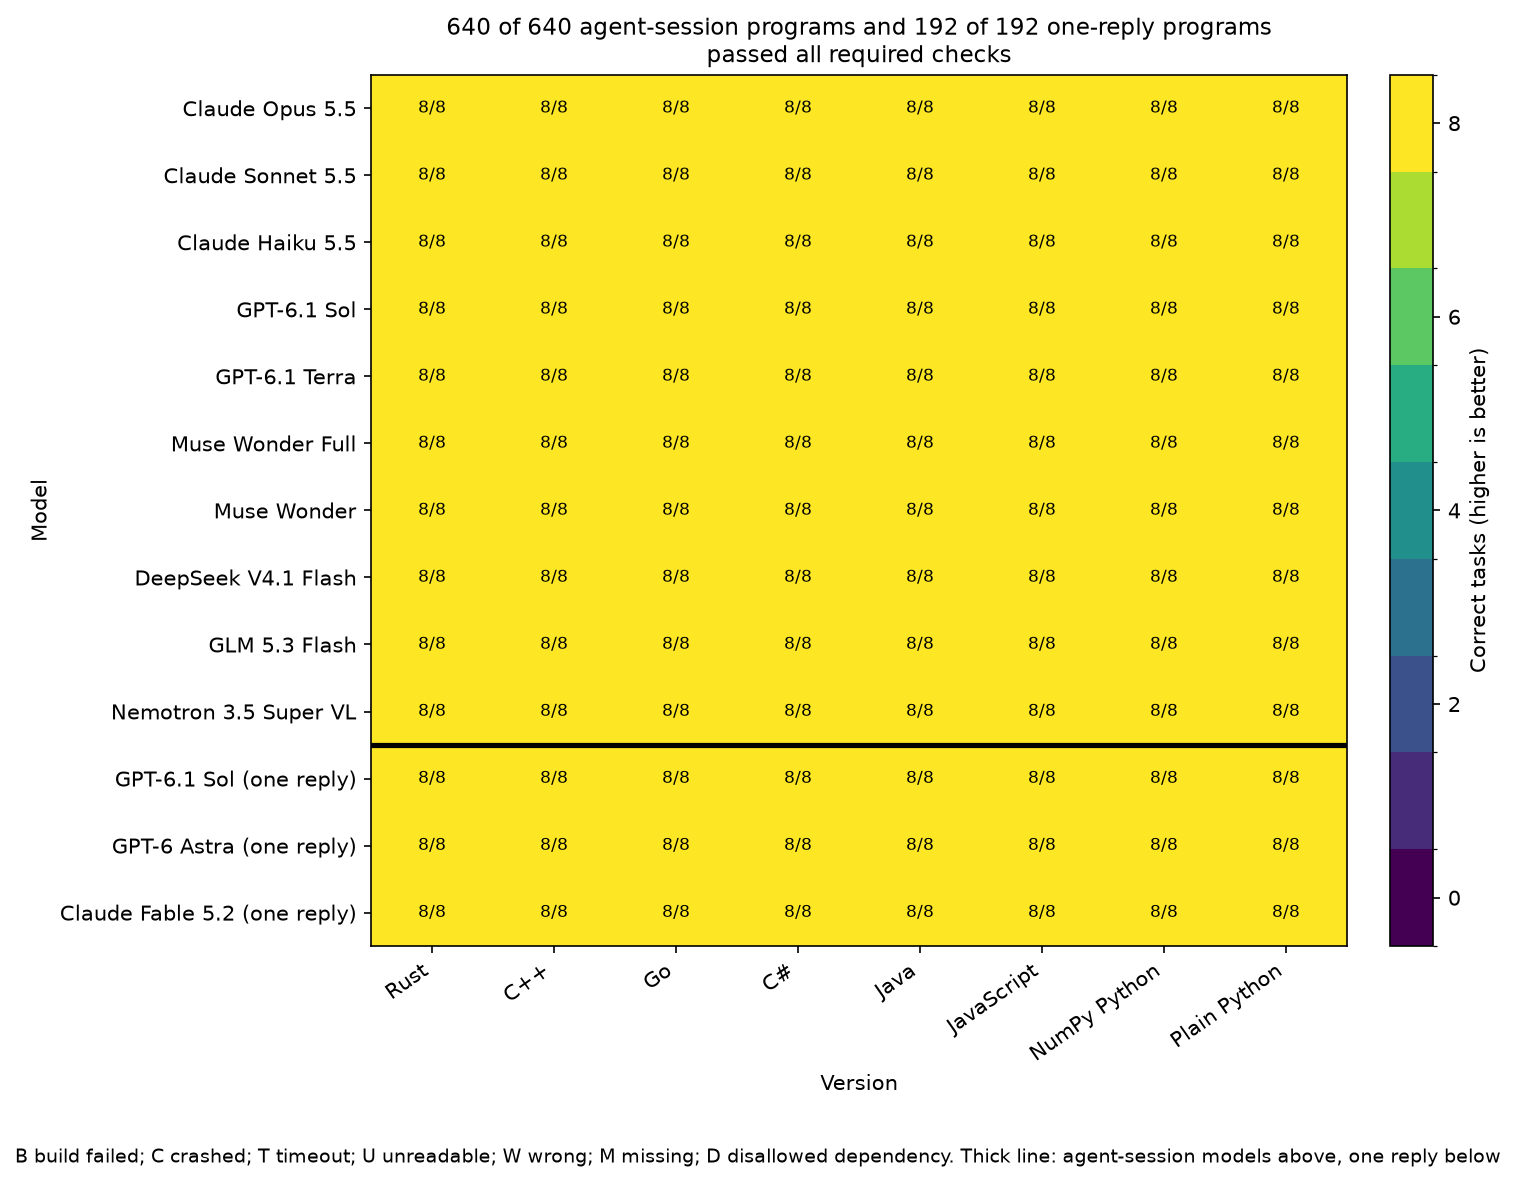

In [14]:
# Compute and present this analysis step for the reader.
required = correctness[correctness.input.isin(["t1", "full"])].copy()


def program_status(group):
    if set(group.input) != {"t1", "full"}:
        return "missing"
    failed = group[group.status != "correct"]
    if not failed.empty:
        return failed.status.iloc[0]
    if group.task.iloc[0] == "walkers":
        if not {1, 4, 16}.issubset(set(group.loc[group.input.eq("t1"), "workers"])):
            return "missing"
        extra = scaling[(scaling.author == group.author.iloc[0]) & (scaling.variant == group.variant.iloc[0])]
        if not {1, 2, 4, 8, 16}.issubset(set(extra.workers)):
            return "missing"
        if (extra.status != "correct").any():
            return extra.loc[extra.status != "correct", "status"].iloc[0]
    return "correct"


status = pd.DataFrame(
    [
        dict(author=a, task=t, variant=v, status=program_status(g))
        for (a, t, v), g in required.groupby(["author", "task", "variant"])
    ]
)
expected = pd.DataFrame(
    [(a, t, v) for a in ALL_AUTHORS for t in TASKS for v in MODEL_VERSIONS]
    + [("reference", t, "simple") for t in TASKS]
    + [(a, "heat", v) for a in ["opus", "sol"] for v in ["plain", "fast", "rust"]],
    columns=["author", "task", "variant"],
)
status = expected.merge(status, how="left", on=["author", "task", "variant"]).fillna({"status": "missing"})
codes = {"build_failed": "B", "crashed": "C", "timeout": "T", "unreadable": "U", "wrong": "W", "missing": "M", "disallowed_dependency": "D"}
def compact_status(g):
    count = int(g.status.eq("correct").sum())
    suffix = "".join(sorted({codes.get(x, "?") for x in g.status if x != "correct"}))
    return f"{count}/{len(g)}" + (f" {suffix}" if suffix else "")
compact = status[status.author.isin(ALL_AUTHORS)].groupby(["author", "variant"]).apply(compact_status, include_groups=False).unstack().reindex(index=ALL_AUTHORS, columns=MODEL_VERSIONS)
compact["Total"] = status[status.author.isin(ALL_AUTHORS)].groupby("author").apply(compact_status, include_groups=False).reindex(ALL_AUTHORS)
display(with_separator(compact.rename(index=MODEL_LABELS, columns=LABELS), len(AUTHORS)))
failures = required[required.status.ne("correct")][
    ["author", "task", "variant", "input", "workers", "status", "detail", "stderr"]
].copy()
failures["stderr"] = failures.stderr.fillna("").astype(str).str[:200]
display(failures)
all_types = [
    "correct",
    "wrong",
    "unreadable",
    "crashed",
    "timeout",
    "build_failed",
    "disallowed_dependency",
    "missing",
]
counts_author = (
    status[status.author.isin(ALL_AUTHORS)]
    .groupby(["author", "status"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=ALL_AUTHORS, columns=all_types, fill_value=0)
)
counts_author["out_of"] = 64
denom = counts_author.correct + counts_author.wrong
counts_author["readable_accuracy"] = counts_author.correct / denom.replace(0, np.nan)
counts_author["unreadable_type_failures"] = counts_author[
    ["unreadable", "crashed", "timeout", "build_failed", "disallowed_dependency", "missing"]
].sum(axis=1)
display(with_separator(counts_author.rename(index=MODEL_LABELS), len(AUTHORS)))
for group, subset in [("agent-session programs", status[status.author.isin(AUTHORS)]), ("one-reply programs", status[status.author.isin(ONE_REPLY)]), ("references", status[status.author.eq("reference")]), ("heat-pilot programs", status[status.author.isin(["opus", "sol"])])]:
    print(f"{group}: {subset.status.eq('correct').sum()} of {len(subset)} correct")
grid = (
    status[status.author.isin(ALL_AUTHORS)]
    .assign(correct=lambda d: d.status.eq("correct"))
    .pivot_table(index="author", columns="variant", values="correct", aggfunc="sum")
    .reindex(index=ALL_AUTHORS, columns=MODEL_VERSIONS)
)
fig, ax = plt.subplots(figsize=(10, 7.5))
heatmap(ax, grid, fmt=".0f", cmap="viridis", label="Correct tasks (higher is better)", discrete=True)
codes = {
    "build_failed": "B",
    "crashed": "C",
    "timeout": "T",
    "unreadable": "U",
    "wrong": "W",
    "missing": "M",
    "disallowed_dependency": "D",
}
for i, a in enumerate(ALL_AUTHORS):
    for j, v in enumerate(MODEL_VERSIONS):
        subset = status[(status.author == a) & (status.variant == v)]
        n = int(subset.status.eq("correct").sum())
        types = "".join(sorted({codes.get(x, "?") for x in subset.status if x != "correct"}))
        ax.texts[i * len(MODEL_VERSIONS) + j].set_text(f"{n}/8" + (" " + types if types else ""))
separator_line(ax)
agent_ok = int(grid.loc[AUTHORS].sum().sum())
one_ok = int(grid.loc[ONE_REPLY].sum().sum())
ax.set_title(
    f"{agent_ok} of {len(AUTHORS) * len(TASKS) * len(MODEL_VERSIONS)} agent-session programs and "
    f"{one_ok} of {len(ONE_REPLY) * len(TASKS) * len(MODEL_VERSIONS)} one-reply programs\npassed all required checks",
    fontsize=11,
)
ax.set_xlabel("Version")
ax.set_ylabel("Model")
fig.text(
    0.5,
    -0.04,
    "B build failed; C crashed; T timeout; U unreadable; W wrong; M missing; D disallowed dependency. "
    "Thick line: agent-session models above, one reply below",
    ha="center",
    fontsize=9,
)
fig.tight_layout()
savefig("correctness_grid.png")


Every program is correct and the failure list is empty: 640 programs from agent sessions, 192 one-reply programs, 8
simple-Python references and 6 heat programs from the pilot. No program failed to build, crashed, timed out, printed
unreadable output or gave a wrong value, and every one-reply answer held exactly one code block, so there are no
format failures to separate from wrong answers. The one-reply programs were also checked by the one-reply runner on
the samples and on the hidden inputs before they joined the timing (432 hidden-input runs, all correct).

This is a ceiling. With every program correct, the test cannot rank the models, the languages or the two ways of
writing on correctness: 832 correct out of 832 still allows a true failure rate of up to about 0.4% for programs
like these (95% upper bound), and 192 out of 192 one-reply programs up to about 1.6%. The specs were exact and every
model had samples with expected outputs; the session models could also run them. The rest of the comparison is about
speed, memory, code size and build time.

## 9. Run time on the full inputs

The first table gives, for each task and version, the geometric mean over the ten session models of their median times on
the benchmark input (the full table per model is saved as `data/results/derived/median_full.csv`). In the figure each
row is a task and each marker one version, placed at that geometric mean, with a thin line from the fastest model's
program to the slowest's, so a long line marks a version where the models disagreed. Marker shapes and colours
follow the legend. The x-axis is logarithmic: one grid step is a factor of ten.

In [15]:
ok = status[status.status.eq('correct')][['author', 'task', 'variant']]
full = runs[(runs.input == 'full') & runs.status.eq('correct')].merge(ok, on=['author', 'task', 'variant'])
median = full.groupby(['task', 'author', 'variant']).wall_seconds.agg(['median', 'min', 'max', 'count']).reset_index()
median.to_csv(DERIVED / 'median_times.csv', index=False)
median_measured = full.groupby(['task', 'author', 'variant']).wall_seconds_measured.median().rename('measured_median').reset_index()
shown = median[median.author.isin(AUTHORS + ['reference'])]
full_table = shown.pivot_table(index=['task', 'author'], columns='variant', values='median').reindex(columns=VERSIONS).reindex(TASKS, level='task')
full_table.to_csv(DERIVED / 'median_full.csv')
summary_times = shown.groupby(['task', 'variant'])['median'].agg(geom).unstack().reindex(index=TASKS, columns=VERSIONS)
display(summary_times.rename(columns=LABELS).round(4))


variant,Rust,C++,Go,C#,Java,JavaScript,NumPy Python,Plain Python,Simple Python
task,,,,,,,,,
springs,0.11,0.11,0.14,0.21,0.31,0.32,0.5,13,16
wordpairs,0.97,1.0,1.1,1.2,1.4,1.8,4.7,12,45
ledger,1.2,1.2,1.4,1.5,1.6,2.7,9.3,8.1,10
logscan,0.64,0.58,0.58,0.8,1.1,1.3,4.7,4.2,6.7
routes,0.24,0.26,0.31,0.41,0.5,0.54,2.4,5.8,11
align,0.097,0.11,0.12,0.24,0.33,0.35,0.89,8.1,13
heat,0.067,0.068,0.09,0.13,0.22,0.22,0.46,2.0,16
walkers,0.18,0.12,0.14,0.22,0.28,0.75,1.7,11,23


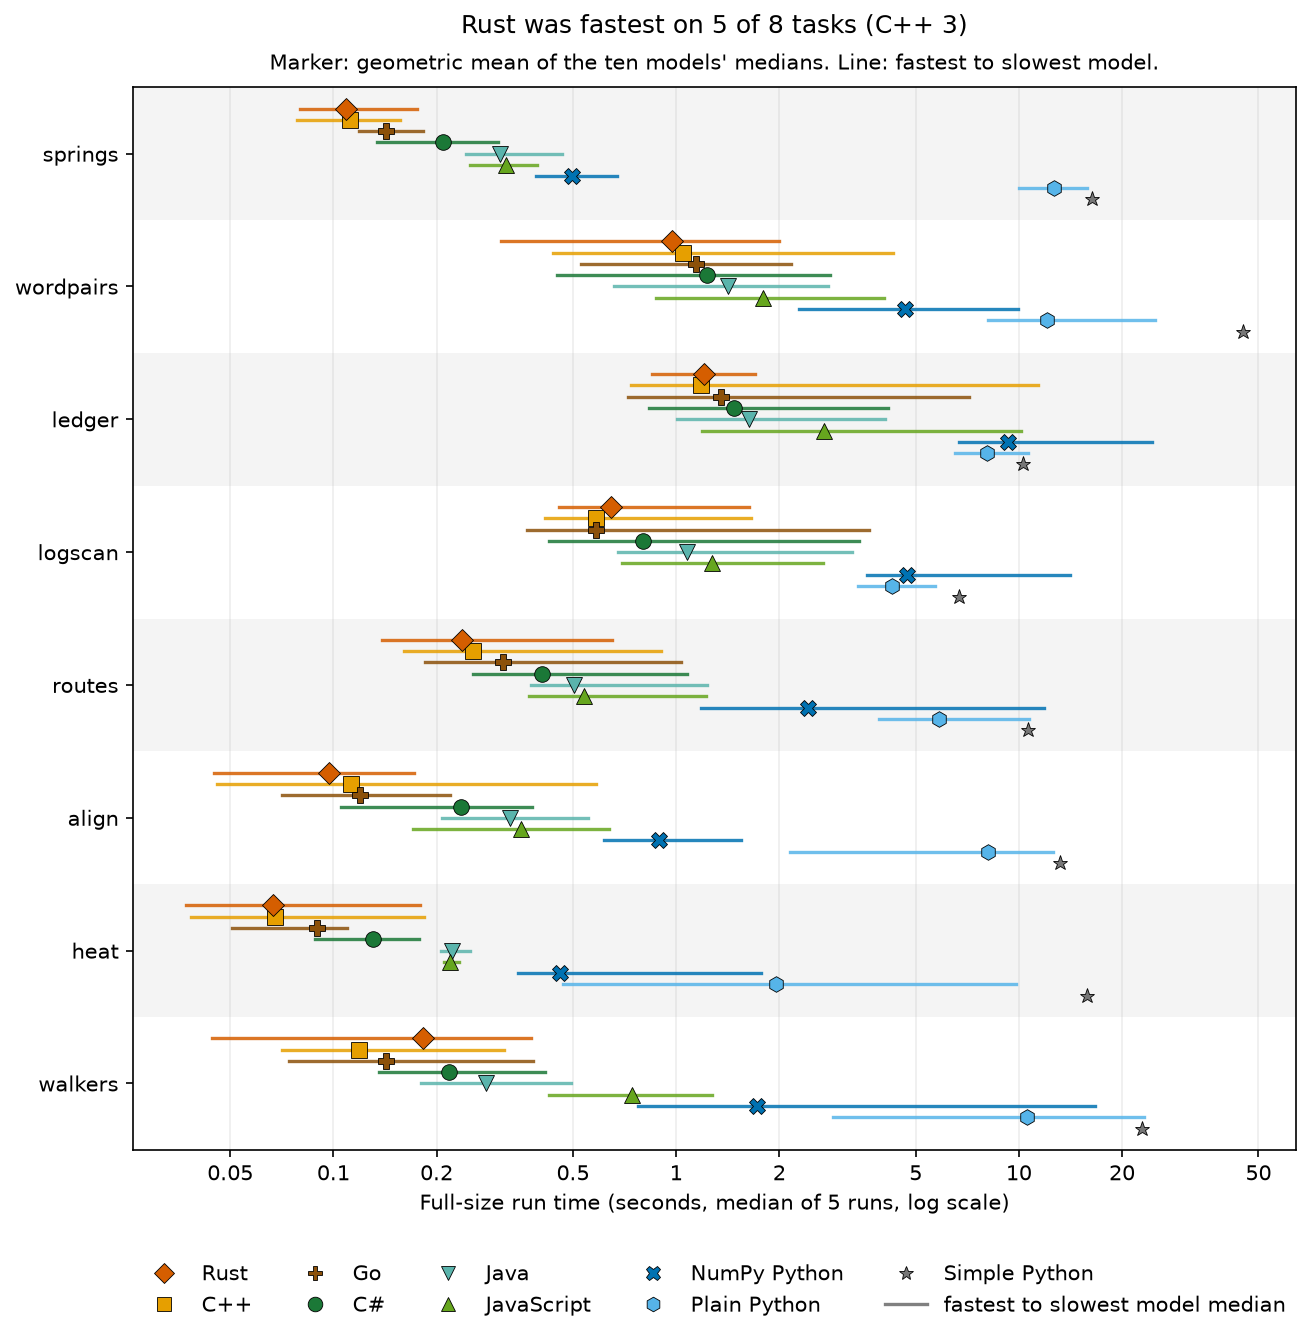

Rust was fastest on 5 of 8 tasks (C++ 3)


In [16]:
# Compute and present this analysis step for the reader.
OFFS = {v: (i - (len(VERSIONS) - 1) / 2) * 0.085 for i, v in enumerate(VERSIONS)}


def combine_authors(df, col):
    """Summarize each task and version across model authors and the reference."""
    rows = []
    for (t, v), g in df.groupby(["task", "variant"]):
        vals = g[col].to_numpy(dtype=float)
        rows.append(dict(task=t, variant=v, gm=geom(vals), lo=vals.min(), hi=vals.max(), n=len(vals)))
    return pd.DataFrame(rows, columns=["task", "variant", "gm", "lo", "hi", "n"])


def strip_by_task(ax, comb, xlabel):
    for ti in range(0, len(TASKS), 2):
        ax.axhspan(ti - 0.5, ti + 0.5, color="black", alpha=0.045, lw=0)
    for r in comb.itertuples():
        y = TASKS.index(r.task) + OFFS[r.variant]
        if r.hi > r.lo:
            ax.plot([r.lo, r.hi], [y, y], color=COLORS[r.variant], lw=1.6, alpha=0.85)
        ax.plot(
            r.gm,
            y,
            marker=MARKERS[r.variant],
            ms=7.5,
            color=COLORS[r.variant],
            markeredgecolor="black",
            markeredgewidth=0.4,
            ls="none",
        )
    ax.set(xscale="log", yticks=range(len(TASKS)), yticklabels=TASKS, xlabel=xlabel, ylim=(len(TASKS) - 0.5, -0.5))
    ax.grid(axis="y", visible=False)
    plain_log_axis(ax)


def winners_title(comb, verb):
    best = comb.loc[comb.groupby("task").gm.idxmin()].variant.value_counts()
    if best.empty:
        return "No measured programs", best
    top = best.index[0]
    rest = ", ".join(f"{LABELS[v]} {n}" for v, n in best.iloc[1:].items())
    return f"{LABELS[top]} {verb} on {best.iloc[0]} of {len(TASKS)} tasks" + (f" ({rest})" if rest else ""), best


time_comb = combine_authors(median[median.author.isin(AUTHORS + ["reference"])], "median")
title, best_counts = winners_title(time_comb, "was fastest")
fig, ax = plt.subplots(figsize=(10, 9.2))
strip_by_task(ax, time_comb, "Full-size run time (seconds, median of 5 runs, log scale)")
ax.set_title(title, fontsize=12, pad=26)
ax.text(
    0.5,
    1.012,
    f"Marker: geometric mean of the {N_WORDS[len(AUTHORS)]} models' medians. Line: fastest to slowest model.",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
)
ax.legend(
    handles=version_handles(ls="none")
    + [Line2D([0], [0], color="gray", lw=1.6, label="fastest to slowest model median")],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=5,
    frameon=False,
)
savefig("runtime_by_task.png")
print(title)


The rows show three groups. Rust, C++ and Go sit at the left, between 0.07 and 1.4 s. C#, Java and JavaScript sit
just to their right, typically 1.5 to 3 times slower. The Python versions sit far to the right: NumPy at 0.5 to 9 s,
plain Python at 2.0 to 13 s and simple Python at 6.7 to 45 s.

The lines are long. On wordpairs the ten models' C++ ranged from 0.44 to 4.3 s and on ledger from 0.74 to 11.4 s,
so the slowest model's C++ could be slower than the fastest model's JavaScript. On heat the plain-Python line runs
from 0.47 s (packed integers) to 9.8 s (a loop over cells). Sections 12 and 20 explain these gaps.

## 10. Which language was fastest

For each task and model, a version's relative time is its median divided by the fastest median among that model's
versions on the task. The first table gives the geometric mean over the eight tasks per model and version. The first
figure draws these means with their 95% bootstrap intervals, the heatmap shows the same numbers as a grid (darker is
slower, log colour scale). The count after them is how often each version was a model's fastest on a task, and the
last table gives the speed-up of each compiled or virtual-machine language over the faster of the same model's two
Python versions. The tables and the heatmap also show the three one-reply authors below a line; ranges in the text
are over the ten session models unless they say otherwise.

author,opus55,sonnet,haiku,sol61,terra,wonder-full,wonder,deepseek,glm,nemotron,sol61-oneshot,astra-oneshot,fable-oneshot
version,,,,,,,,,,,,,
rust,1.2,1.1,1.1,1.1,1.1,1.3,1.3,1.2,1.3,1.5,1.3,1.2,1.1
cpp,1.1,1.1,1.2,1.2,2.0,1.1,1.2,1.1,1.1,1.1,1.0,1.1,1.0
go,1.4,1.5,1.4,1.4,1.7,1.3,1.2,1.3,1.5,1.4,1.4,1.5,1.4
csharp,1.7,2.1,2.0,1.7,2.3,1.8,1.8,1.8,2.1,1.9,2.0,1.9,1.7
java,2.9,2.7,2.6,2.6,2.3,2.7,2.4,2.4,2.4,2.6,2.6,2.8,3.4
js,3.7,3.3,3.5,3.1,3.2,3.1,3.0,3.1,3.1,3.9,3.0,3.7,3.9
fast,10.0,8.2,13,7.5,6.8,8.9,7.4,8.5,7.6,13,8.5,8.0,10
plain,33,38,39,29,27,29,27,29,35,40,22,28,34
simple,111,84,78,78,39,80,62,75,65,52,70,71,122


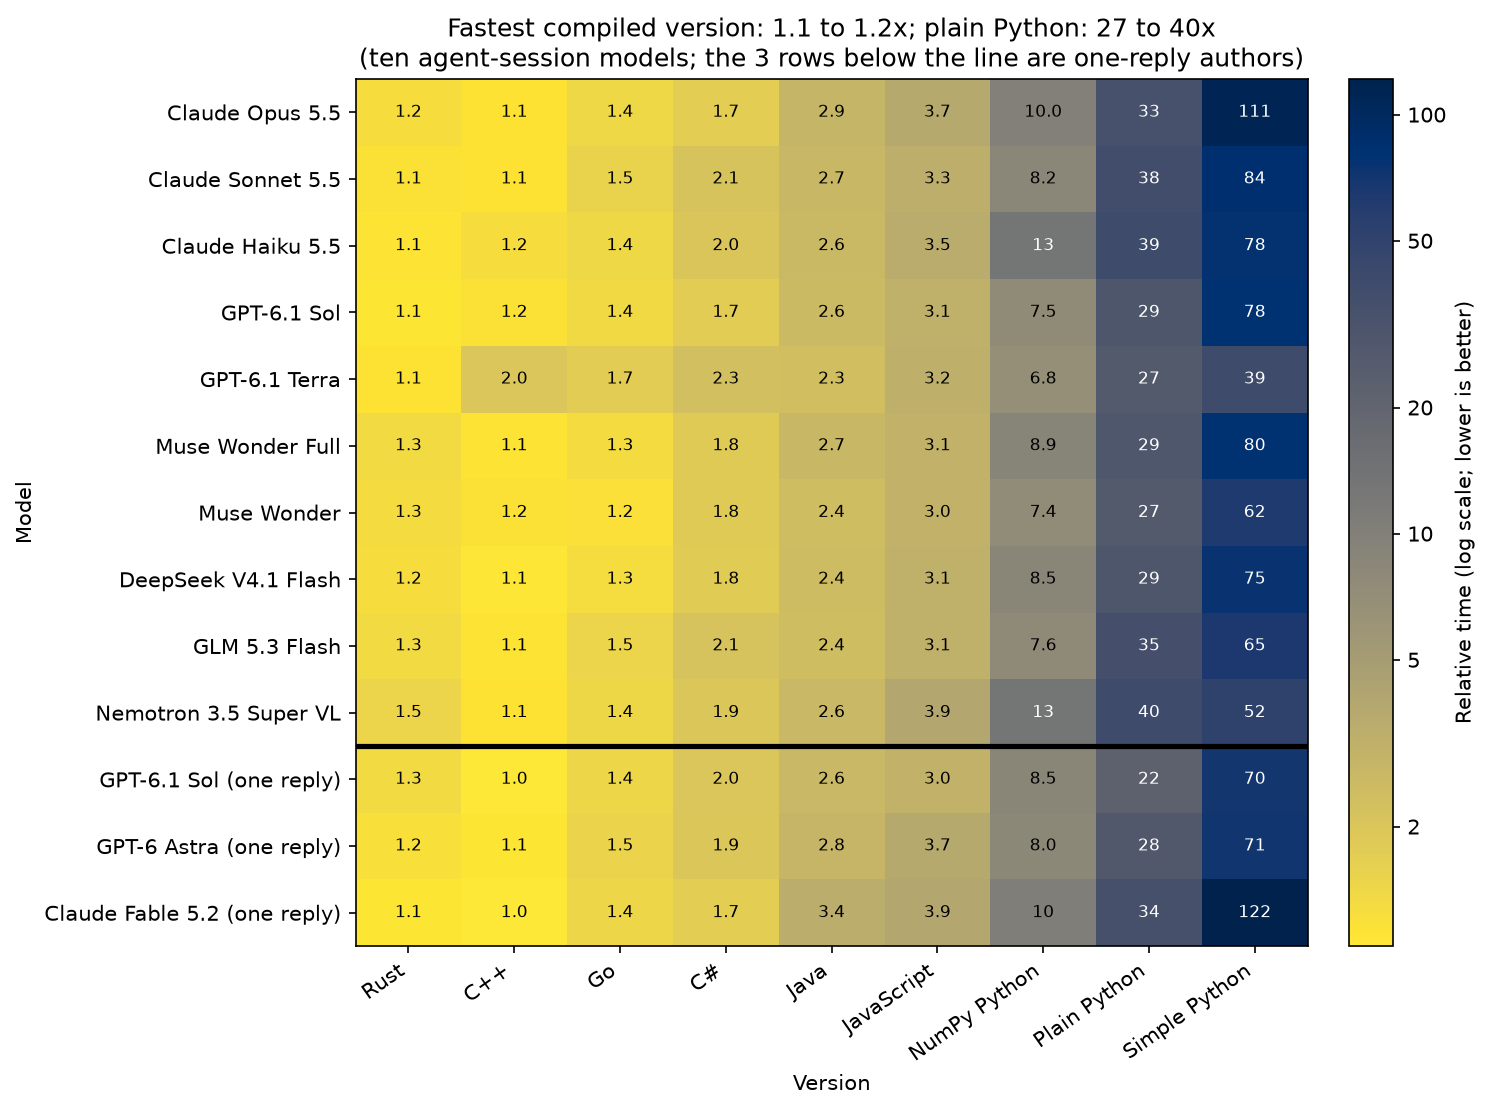

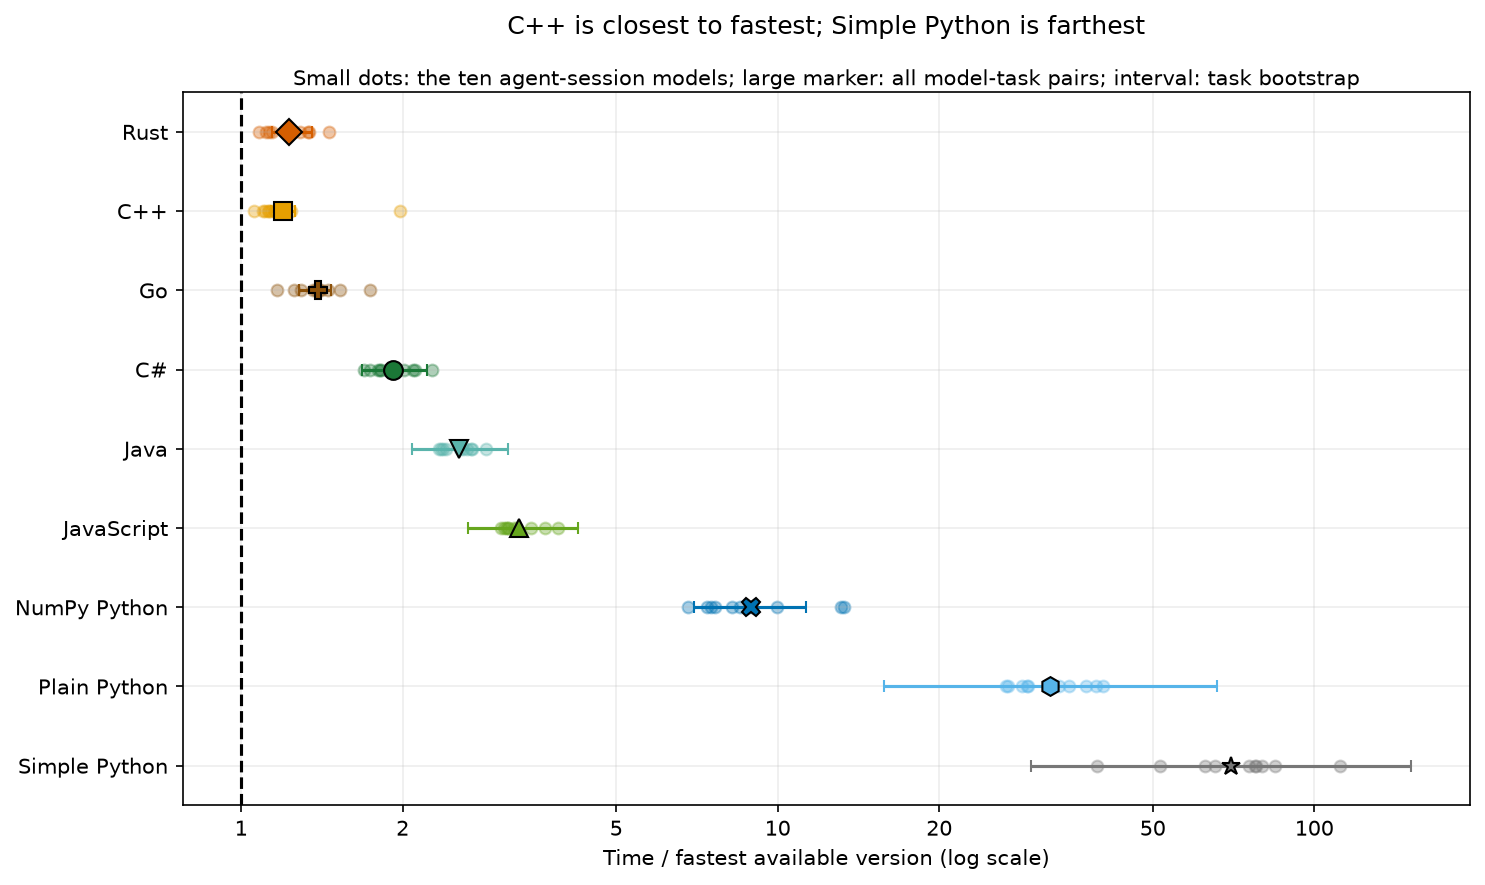

Lowest and highest relative time of each version (geometric mean over tasks, one value per author):


,ten agent-session models: lowest,ten agent-session models: highest,three one-reply authors: lowest,three one-reply authors: highest
version,,,,
Rust,1.08,1.46,1.09,1.33
C++,1.06,1.98,1.04,1.09
Go,1.17,1.74,1.43,1.48
C#,1.69,2.27,1.7,1.97
Java,2.34,2.86,2.64,3.38
JavaScript,3.04,3.89,3.04,3.92
NumPy Python,6.82,13.3,8.04,10.3
Plain Python,26.6,40.4,21.9,34.3
Simple Python,39.3,111,70.2,122


ten agent-session models: the fastest version was Rust, C++ or Go in 80 of 80 task-and-author pairs


version
rust      34
cpp       32
go        14
csharp     0
java       0
js         0
fast       0
plain      0
simple     0
Name: fastest task-author pairs, dtype: int64

three one-reply authors: the fastest version was Rust, C++ or Go in 24 of 24 task-and-author pairs


version
rust       7
cpp       13
go         4
csharp     0
java       0
js         0
fast       0
plain      0
simple     0
Name: fastest task-author pairs, dtype: int64

author,opus55,sonnet,haiku,sol61,terra,wonder-full,wonder,deepseek,glm,nemotron,sol61-oneshot,astra-oneshot,fable-oneshot
language,,,,,,,,,,,,,
rust,7.7,6.9,8.9,6.8,5.9,6.6,5.7,6.8,5.6,9.1,6.1,6.5,9.4
cpp,8.5,6.9,8.0,6.4,3.4,8.0,6.3,8.0,6.8,12,7.8,7.2,9.8
go,6.9,5.2,7.1,5.4,3.8,6.8,6.3,6.7,5.1,9.4,5.6,5.3,7.1
csharp,5.6,3.8,4.9,4.2,2.9,4.9,4.0,4.7,3.5,6.8,4.1,4.1,6.0
java,3.3,2.9,3.8,2.9,2.9,3.3,3.1,3.5,3.1,5.0,3.1,2.8,3.0
js,2.6,2.4,2.9,2.3,2.1,2.9,2.4,2.7,2.4,3.4,2.7,2.1,2.6


Speed-up over the faster of the author's two Python versions: lowest and highest author value per language


,ten agent-session models: lowest,ten agent-session models: highest,three one-reply authors: lowest,three one-reply authors: highest
language,,,,
Rust,5.58,9.11,6.1,9.39
C++,3.37,11.8,7.15,9.79
Go,3.84,9.41,5.28,7.14
C#,2.94,6.83,4.05,5.99
Java,2.85,5.03,2.77,3.08
JavaScript,2.07,3.41,2.09,2.67


In [17]:
# Compute and present this analysis step for the reader.
mt = median.set_index(["task", "author", "variant"])["median"]


def med(task, author, version):
    x = mt.get((task, "reference" if version == "simple" else author, version), np.nan)
    return float(x) if pd.notna(x) and x > 0 else np.nan


rng = np.random.default_rng(39)


def bootstrap_geom(x, n=10000):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    if not len(x):
        return (np.nan,) * 3
    b = np.exp(np.log(rng.choice(x, size=(n, len(x)))).mean(axis=1))
    return geom(x), *np.quantile(b, [0.025, 0.975])


def task_bootstrap(d, value):
    ts = d.task.unique()
    if not len(ts):
        return (np.nan,) * 3
    logs = {t: np.log(d.loc[d.task.eq(t), value].to_numpy(dtype=float)) for t in ts}
    bs = []
    for sample in rng.choice(ts, size=(10000, len(ts))):
        bs.append(np.exp(np.concatenate([logs[t] for t in sample]).mean()))
    return geom(d[value]), *np.quantile(bs, [0.025, 0.975])


GROUPS = [("ten agent-session models", AUTHORS), ("three one-reply authors", ONE_REPLY)]
rr = []
for a in ALL_AUTHORS:
    for t in TASKS:
        vals = {v: med(t, a, v) for v in VERSIONS}
        vals = {v: x for v, x in vals.items() if np.isfinite(x)}
        if vals:
            best = min(vals.values())
            rr.extend(dict(task=t, author=a, version=v, ratio=x / best) for v, x in vals.items())
rel_pairs = pd.DataFrame(rr, columns=["task", "author", "version", "ratio"])
rel_pairs.to_csv(DERIVED / "relative_speed_pairs.csv", index=False)
rows = []
for (a, v), d in rel_pairs.groupby(["author", "version"]):
    g, lo, hi = bootstrap_geom(d.ratio)
    rows.append(dict(author=a, version=v, geometric_mean=g, ci_low=lo, ci_high=hi, tasks=len(d)))
rel = pd.DataFrame(rows, columns=["author", "version", "geometric_mean", "ci_low", "ci_high", "tasks"])
rel.to_csv(DERIVED / "relative_speed.csv", index=False)
display(rel.pivot(index="version", columns="author", values="geometric_mean").reindex(index=VERSIONS, columns=ALL_AUTHORS))
grid = rel.pivot(index="author", columns="version", values="geometric_mean").reindex(index=ALL_AUTHORS, columns=VERSIONS)
compiled_best = grid.loc[AUTHORS, ["rust", "cpp", "go"]].min(axis=1).dropna()
plain_values = grid.loc[AUTHORS, "plain"].dropna()
relative_title = (
    f"Fastest compiled version: {format_number(compiled_best.min())} to {format_number(compiled_best.max())}x; "
    f"plain Python: {format_number(plain_values.min())} to {format_number(plain_values.max())}x"
    if len(compiled_best) and len(plain_values)
    else "Relative time compared with the fastest available version"
)
fig, ax = plt.subplots(figsize=(10, 7.5))
heatmap(ax, grid, log=True, label="Relative time (log scale; lower is better)")
separator_line(ax)
ax.set(title=relative_title + f"\n(ten agent-session models; the {len(ONE_REPLY)} rows below the line are one-reply authors)", xlabel="Version", ylabel="Model")
fig.tight_layout()
savefig("relative_speed_heatmap.png")
pairs_agent = rel_pairs[rel_pairs.author.isin(AUTHORS)]
overall = {v: task_bootstrap(pairs_agent[pairs_agent.version.eq(v)], "ratio") for v in VERSIONS}
rel_agent = rel[rel.author.isin(AUTHORS)]
fig, ax = plt.subplots(figsize=(10, 6))
for i, v in enumerate(VERSIONS):
    d = rel_agent[rel_agent.version.eq(v)]
    ax.scatter(d.geometric_mean, [i] * len(d), color=COLORS[v], alpha=0.35, s=32)
    g, lo, hi = overall[v]
    if np.isfinite(g):
        ax.errorbar(
            g,
            i,
            xerr=[[g - lo], [hi - g]],
            fmt=MARKERS[v],
            color=COLORS[v],
            markeredgecolor="black",
            markersize=9,
            capsize=3,
        )
ax.axvline(1, color="black", ls="--")
ax.set(
    xscale="log",
    yticks=range(len(VERSIONS)),
    yticklabels=[LABELS[v] for v in VERSIONS],
    ylim=(len(VERSIONS) - 0.5, -0.5),
    xlabel="Time / fastest available version (log scale)",
)
plain_log_axis(ax)
valid = {v: x[0] for v, x in overall.items() if np.isfinite(x[0])}
ax.set_title(
    f"{LABELS[min(valid, key=valid.get)]} is closest to fastest; {LABELS[max(valid, key=valid.get)]} is farthest"
    if valid
    else "No relative timings available",
    pad=28,
)
ax.text(
    0.5,
    1.01,
    f"Small dots: the {N_WORDS[len(AUTHORS)]} agent-session models; large marker: all model-task pairs; interval: task bootstrap",
    transform=ax.transAxes,
    ha="center",
)
fig.tight_layout()
savefig("relative_speed.png")

print("Lowest and highest relative time of each version (geometric mean over tasks, one value per author):")
range_rows = []
for v in VERSIONS:
    r = {"version": LABELS[v]}
    for name, group in GROUPS:
        x = grid.loc[group, v].dropna()
        r[name + ": lowest"], r[name + ": highest"] = (x.min(), x.max()) if len(x) else (np.nan, np.nan)
    range_rows.append(r)
with pd.option_context("display.width", 250, "display.max_columns", 20, "display.float_format", lambda x: f"{x:.3g}"):
    display(pd.DataFrame(range_rows).set_index("version"))
best_version = rel_pairs.loc[rel_pairs.groupby(["author", "task"]).ratio.idxmin()]
for name, group in GROUPS:
    sub = best_version[best_version.author.isin(group)]
    print(f"{name}: the fastest version was Rust, C++ or Go in {int(sub.version.isin(['rust', 'cpp', 'go']).sum())} of {len(sub)} task-and-author pairs")
    display(sub.version.value_counts().reindex(VERSIONS, fill_value=0).rename("fastest task-author pairs"))
sp = []
for a in ALL_AUTHORS:
    for t in TASKS:
        py = [med(t, a, v) for v in ["plain", "fast"]]
        py = [x for x in py if np.isfinite(x)]
        if len(py) < 2:
            continue
        for v in LANGS:
            x = med(t, a, v)
            if np.isfinite(x):
                sp.append(dict(author=a, task=t, language=v, speedup=min(py) / x))
speed = pd.DataFrame(sp, columns=["author", "task", "language", "speedup"])
rows = []
for (a, v), d in speed.groupby(["author", "language"]):
    g, lo, hi = bootstrap_geom(d.speedup)
    rows.append(dict(author=a, language=v, geometric_mean=g, ci_low=lo, ci_high=hi, tasks=len(d)))
speedups = pd.DataFrame(rows, columns=["author", "language", "geometric_mean", "ci_low", "ci_high", "tasks"])
speedups.to_csv(DERIVED / "speedups.csv", index=False)
speed_wide = speedups.pivot(index="language", columns="author", values="geometric_mean").reindex(index=LANGS, columns=ALL_AUTHORS)
display(speed_wide)
print("Speed-up over the faster of the author's two Python versions: lowest and highest author value per language")
speed_range = []
for v in LANGS:
    r = {"language": LABELS[v]}
    for name, group in GROUPS:
        x = speed_wide.loc[v, group].dropna()
        r[name + ": lowest"], r[name + ": highest"] = (x.min(), x.max()) if len(x) else (np.nan, np.nan)
    speed_range.append(r)
with pd.option_context("display.width", 250, "display.max_columns", 20, "display.float_format", lambda x: f"{x:.3g}"):
    display(pd.DataFrame(speed_range).set_index("language"))


| Version | Relative time, range over the ten session models | Speed-up over the model's faster Python version |
|---|---|---|
| Rust | 1.08 to 1.46 | 5.6x to 9.1x |
| C++ | 1.06 to 1.98 | 3.4x to 11.8x |
| Go | 1.17 to 1.74 | 3.8x to 9.4x |
| C# | 1.69 to 2.27 | 2.9x to 6.8x |
| Java | 2.34 to 2.86 | 2.9x to 5.0x |
| JavaScript | 3.04 to 3.89 | 2.1x to 3.4x |
| NumPy Python | 6.8 to 13.3 | |
| Plain Python | 26.6 to 40.4 | |

The families separate cleanly for every model: the ahead-of-time compiled languages between 1.06 and 2.0, the
virtual-machine languages from 1.7 to 3.9, NumPy Python from 6.8 to 13 and plain Python above 26. Rust was the
fastest version in 34 of the 80 task-and-model pairs, C++ in 32 and Go in 14; no other version was ever fastest.
Inside a family the order depends on the model: C++ averaged 1.06 to 1.24 for nine models and 1.98 for Terra, whose
C++ was slow on three tasks (section 20). Among the virtual-machine languages the order was the same for all ten
models: C#, then Java, then JavaScript.

The speed-up column is the comparison a team would make when deciding whether to move a Python job: given the better
of the model's two Python versions, how much does each language add. It depends on the model's Python as well as its
faster language. Nemotron's gains were the largest (9.1x for Rust, 11.8x for C++) partly because its Python was the
slowest of the ten; Terra's were the smallest for C++ (3.4x) because its compiled versions were slow too.

The one-reply programs kept the same order. Over the three one-reply authors, Rust ranged from 1.09 to 1.33, C++ from
1.04 to 1.09, Go from 1.43 to 1.48, C# from 1.70 to 1.97, Java from 2.64 to 3.38, JavaScript from 3.04 to 3.92,
NumPy Python from 8.0 to 10.3 and plain Python from 21.9 to 34.3. C++ was their fastest version in 13 of 24 pairs,
Rust in 7 and Go in 4.

## 11. Where NumPy helps

The table divides each model's plain-Python time by its NumPy time for every task. A value above 1 means the NumPy
version was faster than the same model's plain version; below 1 means it was slower.

In [18]:
p=median[median.author.isin(AUTHORS)].pivot(index=['task','author'],columns='variant',values='median').reindex(columns=['plain','fast'])
display((p['plain']/p['fast']).unstack('author').reindex(index=TASKS,columns=AUTHORS))


author,opus55,sonnet,haiku,sol61,terra,wonder-full,wonder,deepseek,glm,nemotron
task,,,,,,,,,,
springs,27,31,33,22,22,28,26,22,25,22
wordpairs,3.7,6.0,1.6,2.2,1.8,2.7,3.6,3.1,1.3,2.5
ledger,0.68,0.75,0.32,0.97,1.0,1.3,0.96,1.2,0.8,1.3
logscan,0.98,0.94,0.33,0.87,0.94,0.91,1,0.92,1.3,1.3
routes,3.8,2.9,4.3,3.4,0.9,1.4,1.6,2.2,3.9,2.4
align,12,12,13,3.4,7.6,9.2,9.7,9.0,14,7.0
heat,1.4,2.2,2.9,15,17,2.1,2.3,2.2,22,3.5
walkers,3.7,18,7.2,7.3,13,4.5,9.1,5.9,4.8,1.4


NumPy paid off when the work is arithmetic over many numbers at once. On springs every session model's NumPy version
was 22 to 33 times faster than its plain one, and on align 3.4 (Sol) to 14 times. On heat the gain depends on the
plain version: 1.4 to 2.9 times against the six packed-integer plain versions, 15 to 22 times against Sol's,
Terra's and GLM's cell loops, and 3.5 for Nemotron, whose NumPy heat was itself slow (1.8 s). On walkers it ranged
from 1.4 (Nemotron, whose NumPy version moved all walkers one step at a time) to 18 (Sonnet).

It did nothing for the parsing tasks. Each JSON line or log line still has to be read by Python code one item at a
time, and NumPy can only take over after that: on ledger the NumPy versions ran at 0.68 to 1.3 times the speed of
the plain ones, and Haiku's at 0.32, three times slower, because it tried to parse the JSON with whole-array
operations (section 20). Logscan was the same, 0.87 to 1.3 for nine models and 0.33 for Haiku.

## 12. Language or model: which matters more

Sections 9 and 10 showed both decisions at work: the language sorts the versions into families, and within a
language the ten models' programs can differ several times over. To compare the two on one scale, the run times
within each task are split into parts. Take the 60 programs of one task in the six non-Python languages (ten models
times six languages), with their times on a logarithmic scale so that a doubling counts the same anywhere. Part of
their spread lines up with the language (all the Java programs slower than all the Rust ones, say), part with the
model (one model's programs faster in every language), and the rest is the particular combination of model and
language, together with timing noise. The shares add up to 100%. This is a two-way analysis of variance with one
program per cell, so the combination and the noise cannot be told apart. The one-reply programs are left out, so
that the model share is not mixed with the way of writing.

The pooled row adds each part's sum of squares over the eight tasks and divides by the total, which is the same as
letting the language and model effects differ by task. The table also gives the unweighted mean of the per-task
shares as a check, and the right-hand panel repeats the split with NumPy and plain Python included. A second figure
gives the same contrast as ratios: for each task, the slowest-to-fastest ratio across the ten models in one language
(averaged over languages) against the slowest-to-fastest ratio across the six languages for one model (averaged
over models).

,scope,task,language,model,shared,interaction,n,total_ss,language_mean_share,model_mean_share
0,six languages,springs,0.847,0.064,0.000,0.089,60,2.603,NaN,NaN
1,six languages,wordpairs,0.119,0.699,0.000,0.181,60,3.904,NaN,NaN
2,six languages,ledger,0.202,0.563,0.000,0.235,60,4.374,NaN,NaN
3,six languages,logscan,0.297,0.595,0.000,0.108,60,3.497,NaN,NaN
4,six languages,routes,0.328,0.576,0.000,0.095,60,3.461,NaN,NaN
5,six languages,align,0.607,0.220,0.000,0.173,60,5.151,NaN,NaN
6,six languages,heat,0.745,0.112,0.000,0.143,60,3.799,NaN,NaN
7,six languages,walkers,0.607,0.291,0.000,0.102,60,6.646,NaN,NaN
8,six languages,all tasks,0.470,0.387,0.000,0.143,480,33.435,0.469,0.390
9,all model versions,springs,0.985,0.007,0.000,0.009,80,32.182,NaN,NaN


Pooled decomposition sample sizes: {'six languages': 480, 'all model versions': 640}


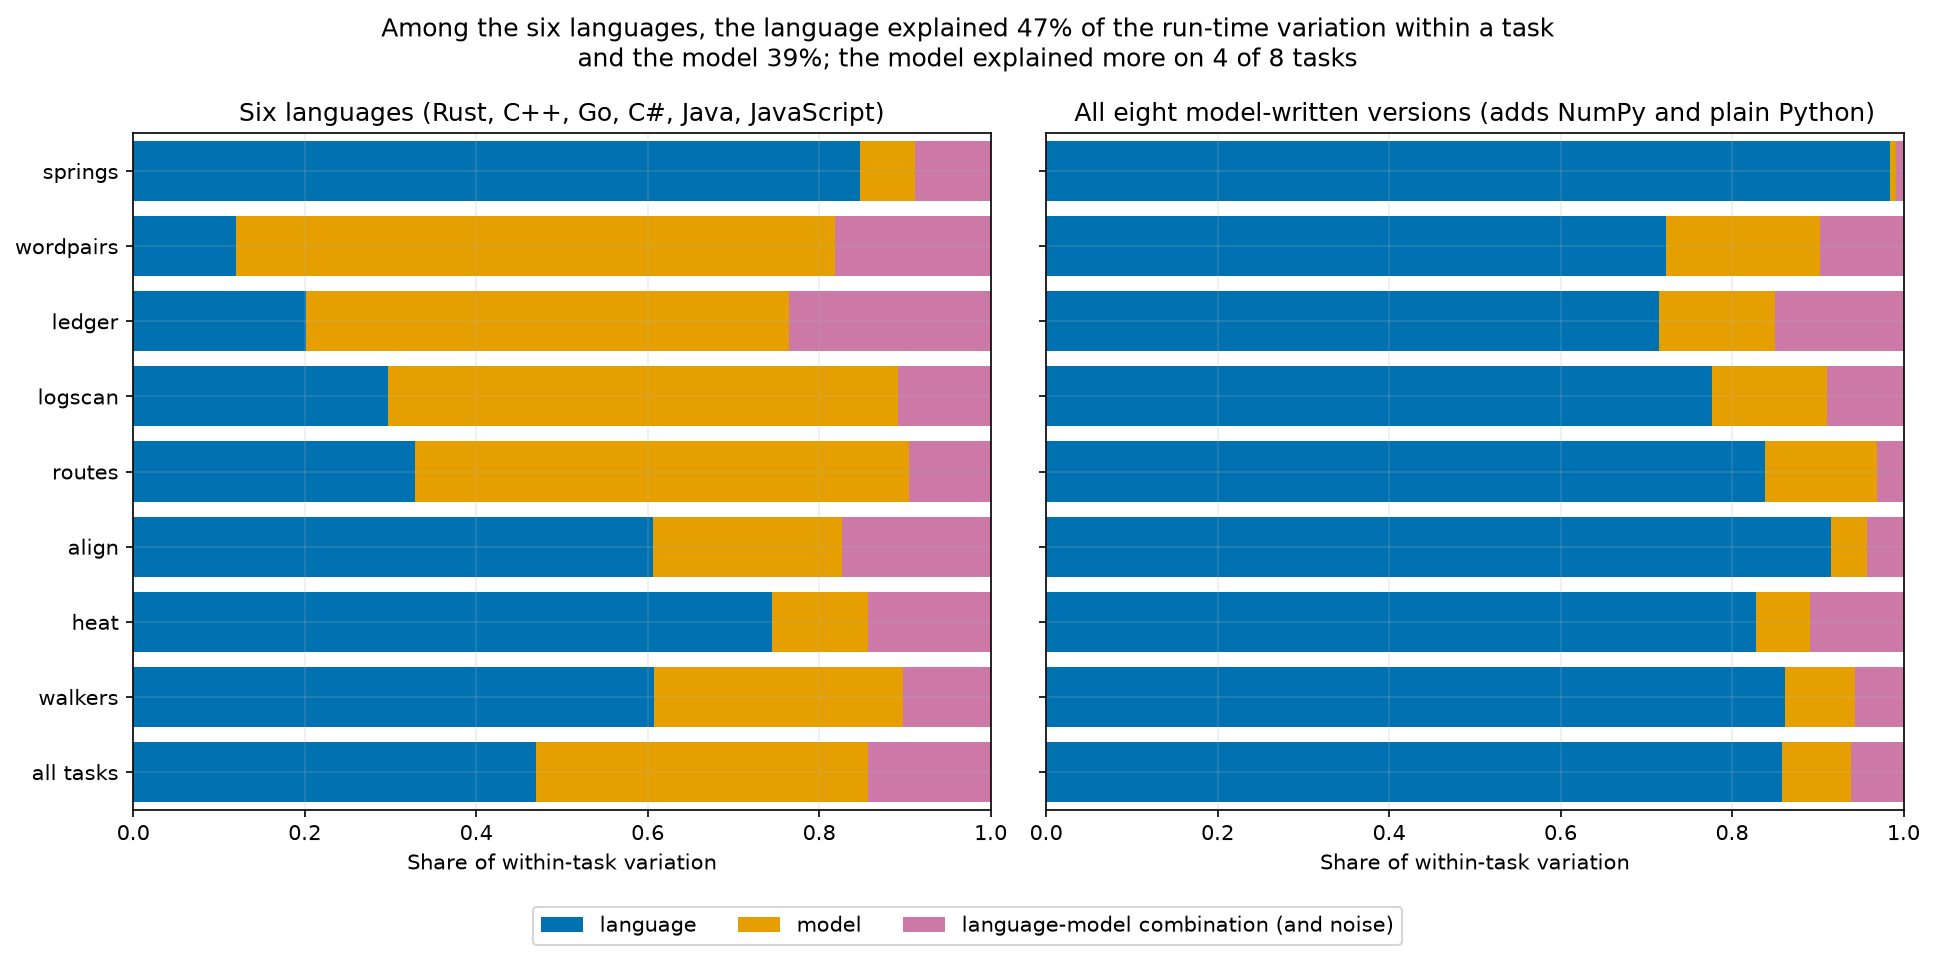

variant
rust     4.1
cpp      6.1
go       4.3
csharp   3.9
java     2.9
js       3.1
Name: spread, dtype: float64

author
opus55        3.8
sonnet        3.3
haiku         3.5
sol61         3.2
terra         3.6
wonder-full   3.7
wonder        3.1
deepseek      3.3
glm           3.2
nemotron      4.1
Name: spread, dtype: float64

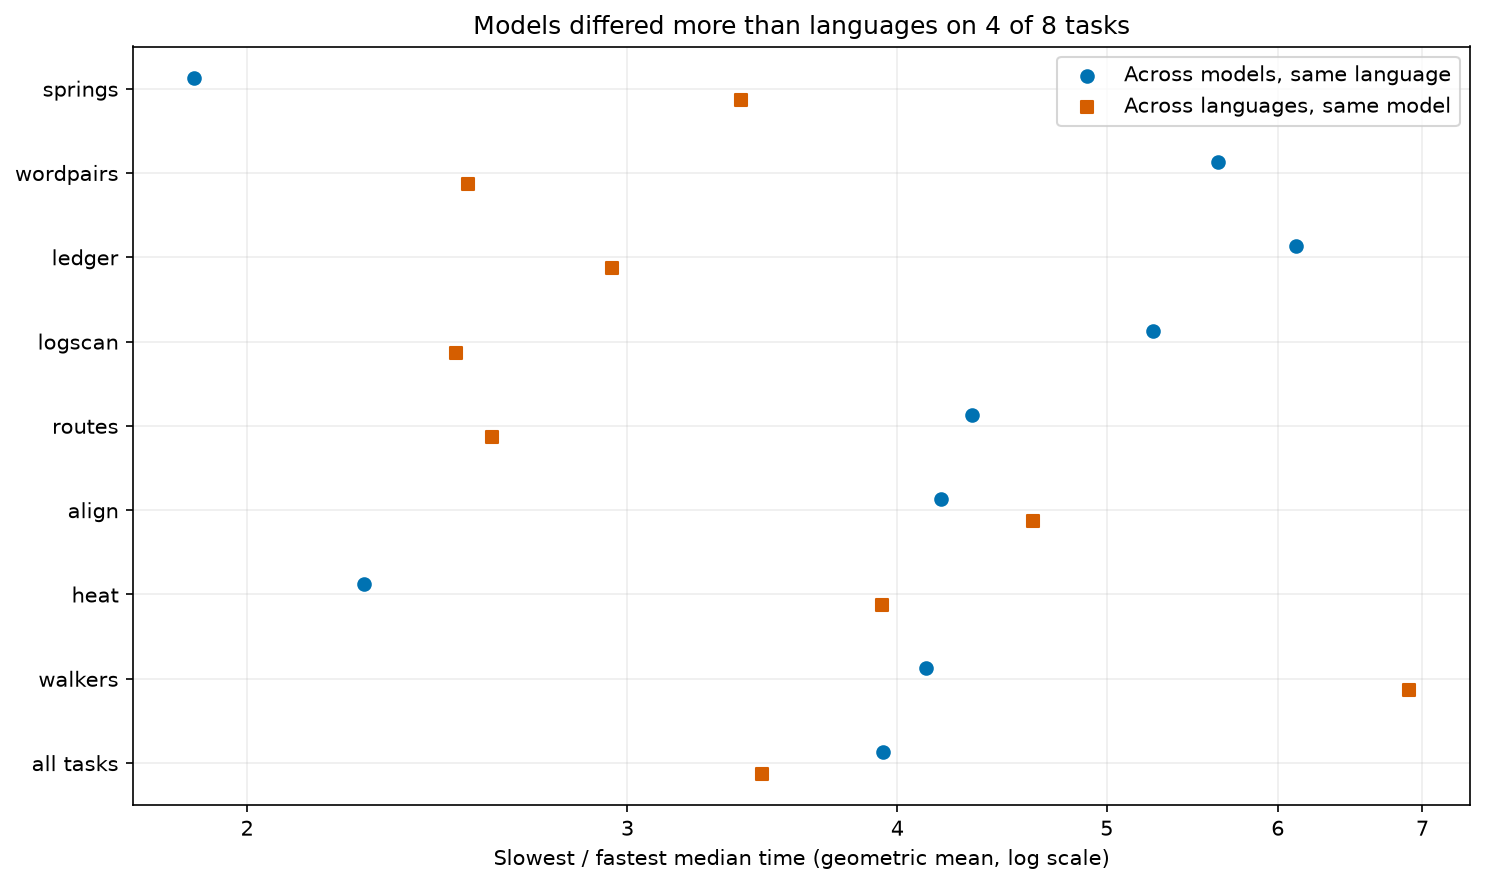

In [19]:
# Compute and present this analysis step for the reader.
# Least-squares decomposition, conditioning pooled comparisons on task.
def decomposition(d, pooled=False):
    d = d[d["median"] > 0].copy()
    if len(d) < 2:
        return None
    y = np.log10(d["median"].to_numpy())
    intercept = np.ones((len(d), 1))

    def dummy(col):
        return pd.get_dummies(d[col], drop_first=True, dtype=float).to_numpy()

    task = dummy("task") if pooled else np.empty((len(d), 0))
    lang = dummy("variant")
    model = dummy("author")
    base = np.column_stack([intercept, task])

    def sse(*xs):
        X = np.column_stack([base, *xs])
        residual = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
        return residual @ residual

    total = sse()
    if total < 1e-15:
        return None
    l = 1 - sse(lang) / total
    m = 1 - sse(model) / total
    a = 1 - sse(lang, model) / total
    return dict(language=a - m, model=a - l, shared=l + m - a, interaction=1 - a, n=len(d), total_ss=total)


rows = []
for scope, vs in [("six languages", LANGS), ("all model versions", MODEL_VERSIONS)]:
    d = median[median.author.isin(AUTHORS) & median.variant.isin(vs)]
    task_rows = []
    for t in TASKS:
        x = decomposition(d[d.task.eq(t)])
        if x:
            task_rows.append(dict(scope=scope, task=t, **x))
    rows.extend(task_rows)
    if task_rows:
        frame = pd.DataFrame(task_rows)
        pooled = {col: np.average(frame[col], weights=frame.total_ss) for col in ["language", "model", "shared", "interaction"]}
        rows.append(dict(scope=scope, task="all tasks", **pooled, n=int(frame.n.sum()), total_ss=frame.total_ss.sum(),
                         language_mean_share=frame.language.mean(), model_mean_share=frame.model.mean()))
lvm = pd.DataFrame(rows)
lvm.to_csv(DERIVED / "language_vs_model.csv", index=False)
shown_lvm = lvm.copy()
for col in ["language", "model", "shared", "interaction", "language_mean_share", "model_mean_share"]:
    shown_lvm.loc[shown_lvm[col].abs() < 0.0005, col] = 0
with pd.option_context("display.max_rows", None, "display.float_format", lambda x: f"{x:.3f}"):
    display(shown_lvm.round(3))
print("Pooled decomposition sample sizes:", lvm[lvm.task.eq("all tasks")].set_index("scope").n.to_dict())
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
segments = ["language", "model"] + (["shared"] if lvm.shared.abs().max() >= 0.005 else []) + ["interaction"]
colors = {"language": "#0072B2", "model": "#E69F00", "shared": "#999999", "interaction": "#CC79A7"}
segment_labels = {"language": "language", "model": "model", "shared": "overlap", "interaction": "language-model combination (and noise)"}
for ax, scope in zip(axes, ["six languages", "all model versions"]):
    d = lvm[lvm.scope.eq(scope)].set_index("task").reindex(TASKS + ["all tasks"])
    left = np.zeros(len(d))
    for col in segments:
        x = d[col].fillna(0).to_numpy()
        ax.barh(range(len(d)), x, left=left, color=colors[col], label=segment_labels[col])
        left += x
    ax.set(
        xlim=(0, 1),
        yticks=range(len(d)),
        yticklabels=TASKS + ["all tasks"],
        ylim=(len(d) - 0.5, -0.5),
        xlabel="Share of within-task variation",
        title={"six languages": "Six languages (Rust, C++, Go, C#, Java, JavaScript)", "all model versions": "All eight model-written versions (adds NumPy and plain Python)"}[scope],
    )
pooled = lvm[(lvm.scope == "six languages") & (lvm.task == "all tasks")]
task_comparison = lvm[(lvm.scope == "six languages") & (lvm.task != "all tasks")]
model_wins = int((task_comparison.model > task_comparison.language).sum())
figure_title = (f"Among the six languages, the language explained {pooled.iloc[0]['language']:.0%} of the run-time variation within a task\n"
                f"and the model {pooled.iloc[0]['model']:.0%}; the model explained more on {model_wins} of {len(task_comparison)} tasks") if len(pooled) else "Language and model effects: insufficient measured data"
fig.suptitle(figure_title)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=4)
fig.tight_layout()
savefig("language_vs_model.png")
d = median[median.author.isin(AUTHORS) & median.variant.isin(LANGS)]
ms = (
    d.groupby(["task", "variant"])["median"]
    .agg(lambda x: x.max() / x.min() if len(x) >= 2 and x.min() > 0 else np.nan)
    .rename("spread")
    .reset_index()
)
ls = (
    d.groupby(["task", "author"])["median"]
    .agg(lambda x: x.max() / x.min() if len(x) >= 2 and x.min() > 0 else np.nan)
    .rename("spread")
    .reset_index()
)
display(ms.groupby("variant").spread.agg(geom).reindex(LANGS))
display(ls.groupby("author").spread.agg(geom).reindex(AUTHORS))
fig, ax = plt.subplots(figsize=(10, 6))
wins = 0
compared = 0
for i, t in enumerate(TASKS + ["all tasks"]):
    m = geom(ms.spread if t == "all tasks" else ms.loc[ms.task.eq(t), "spread"])
    l = geom(ls.spread if t == "all tasks" else ls.loc[ls.task.eq(t), "spread"])
    if t != "all tasks" and np.isfinite(m) and np.isfinite(l):
        compared += 1
        wins += l > m
    if np.isfinite(m):
        ax.scatter(m, i - 0.13, color="#0072B2", marker="o", label="Across models, same language" if i == 0 else None)
    if np.isfinite(l):
        ax.scatter(l, i + 0.13, color="#D55E00", marker="s", label="Across languages, same model" if i == 0 else None)
ax.set(
    xscale="log",
    yticks=range(len(TASKS) + 1),
    yticklabels=TASKS + ["all tasks"],
    ylim=(len(TASKS) + 0.5, -0.5),
    xlabel="Slowest / fastest median time (geometric mean, log scale)",
    title=(f"Languages differed more than models on {wins} of {compared} tasks" if wins > compared - wins else f"Models differed more than languages on {compared - wins} of {compared} tasks"),
)
plain_log_axis(ax)
ax.legend()
fig.tight_layout()
savefig("model_vs_language_spread.png")


Among the six languages, the language explained 47% of the variation within a task and the model 39%, with 14% left
for particular combinations and noise; the unweighted mean of the per-task shares gives 47% and 39% as well.

The tasks split into two kinds. Where the work is arithmetic, the language decided: springs 85% language against 6%
model, heat 75% against 11%, walkers 61% against 29% and align 61% against 22%. Where the work is reading text and
looking things up in tables, the model decided: wordpairs 12% language against 70% model, ledger 20% against 56%,
logscan 30% against 59% and routes 33% against 58%. On those tasks each model's choice of parser and table carried
across its six languages, so a model that wrote a fast byte scanner wrote one in all six, and a model that used a
general JSON library used it in several (section 20).

With NumPy and plain Python included, the language explained 86% and the model 8%. That says only that Python is far
slower than the other six languages; it does not mean the model stops mattering once a fast language is chosen.

In the ratio view, the ten models' programs in one language differed by a factor of 4.1 on average for Rust, 6.1 for
C++, 4.3 for Go, 3.9 for C#, 2.9 for Java and 3.1 for JavaScript, while one model's six languages differed by 3.1 to
4.1. The widest of ten programs is naturally wider than the widest of six, so this view favours the model somewhat;
the split above has no such bias.

## 13. Which model wrote the fastest code

The model speed index of section 6 puts every author on one scale. For each task and version, each program's median
is divided by the geometric mean of the ten session models' medians; an author's index is the geometric mean of
those ratios over its 64 programs (eight tasks times eight versions), with a 95% interval from resampling tasks. The
cell prints the indices, also under the per-program drift correction for the four authors timed on the second day,
draws them (open-weight models and one-reply authors shaded, dashed line at 1.0 for a typical session model), breaks
them down by version in a heatmap, counts how often each model wrote the fastest and the slowest of the ten session
programs in a cell and how often each author wrote the fastest of all 13, and plots the index against the model's
median session length.

,author,index,ci_low,ci_high,cells,tasks
0,opus55,0.643,0.563,0.736,64,8
1,sonnet,0.848,0.768,0.935,64,8
2,haiku,0.977,0.889,1.07,64,8
3,sol61,0.833,0.751,0.935,64,8
4,terra,1.84,1.47,2.25,64,8
5,wonder-full,0.849,0.743,0.937,64,8
6,wonder,1.02,0.895,1.17,64,8
7,deepseek,0.869,0.787,0.963,64,8
8,glm,1.06,0.964,1.19,64,8
9,nemotron,1.53,1.34,1.77,64,8


Speed index cells per model: {'opus55': 64, 'sonnet': 64, 'haiku': 64, 'sol61': 64, 'terra': 64, 'wonder-full': 64, 'wonder': 64, 'deepseek': 64, 'glm': 64, 'nemotron': 64, 'sol61-oneshot': 64, 'astra-oneshot': 64, 'fable-oneshot': 64} | baseline cells: 64


Speed index of the authors timed on 2026-11-12 under the two corrections:


,author,correction,index,ci_low,ci_high,cells
0,sol61,one global factor,0.833,0.751,0.935,64
1,sol61,per-program factor from Opus,0.833,0.739,0.939,64
2,sol61-oneshot,one global factor,0.94,0.859,1.03,64
3,sol61-oneshot,per-program factor from Opus,0.94,0.863,1.03,64
4,astra-oneshot,one global factor,0.976,0.91,1.05,64
5,astra-oneshot,per-program factor from Opus,0.976,0.912,1.05,64
6,fable-oneshot,one global factor,0.598,0.507,0.708,64
7,fable-oneshot,per-program factor from Opus,0.598,0.511,0.698,64


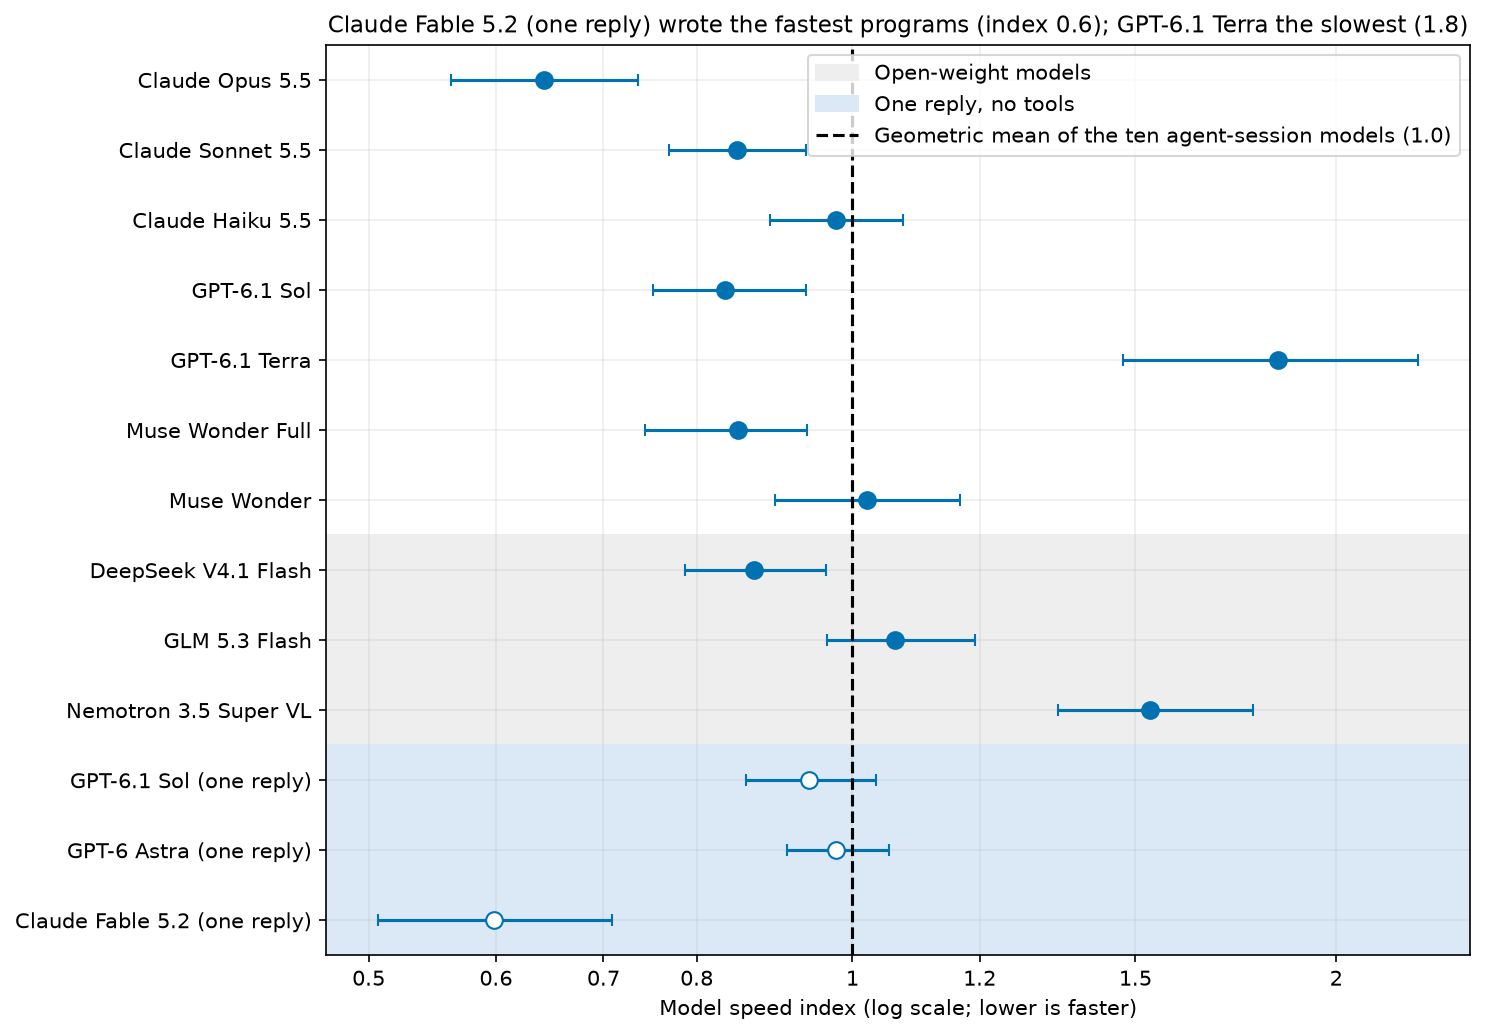

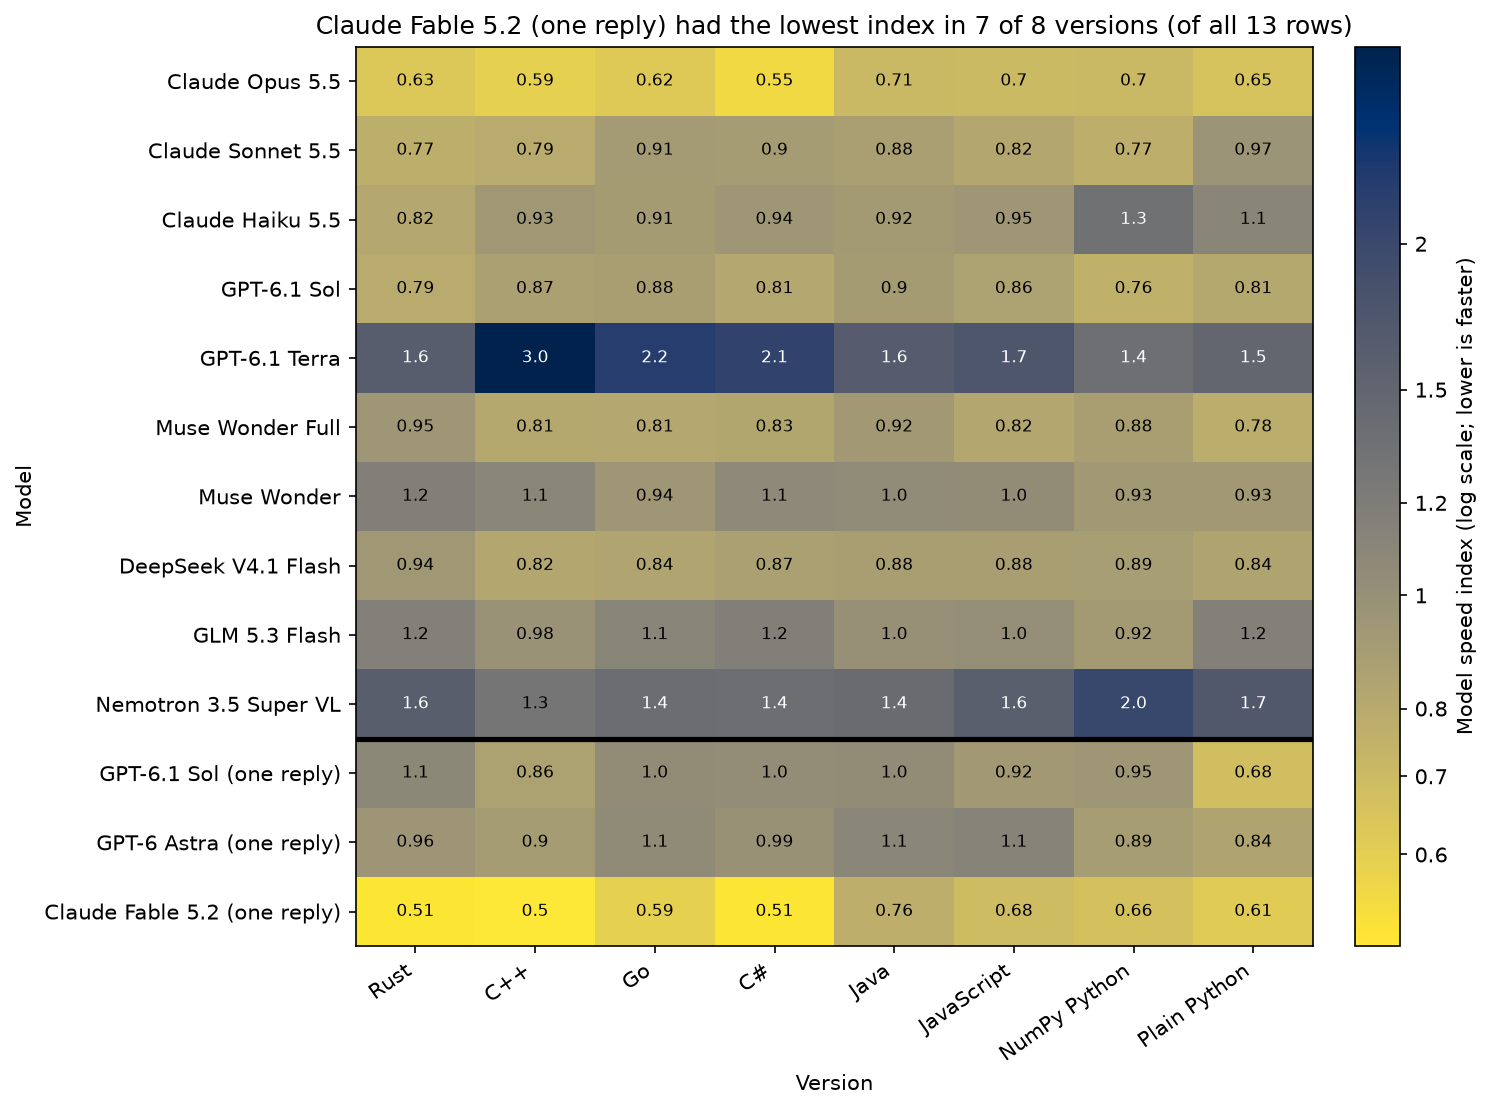

Fastest and slowest of the ten agent-session models, in 64 cells:


,fastest,slowest
author,,
opus55,36,0
sonnet,6,1
haiku,0,7
sol61,5,0
terra,0,28
wonder-full,6,2
wonder,5,3
deepseek,5,0
glm,1,2


Cells where each author was fastest of all 13 (of 64):


author
opus55           18
sonnet            2
haiku             0
sol61             4
terra             0
wonder-full       5
wonder            3
deepseek          2
glm               1
nemotron          0
sol61-oneshot     2
astra-oneshot     1
fable-oneshot    26
Name: fastest of 13, dtype: int64

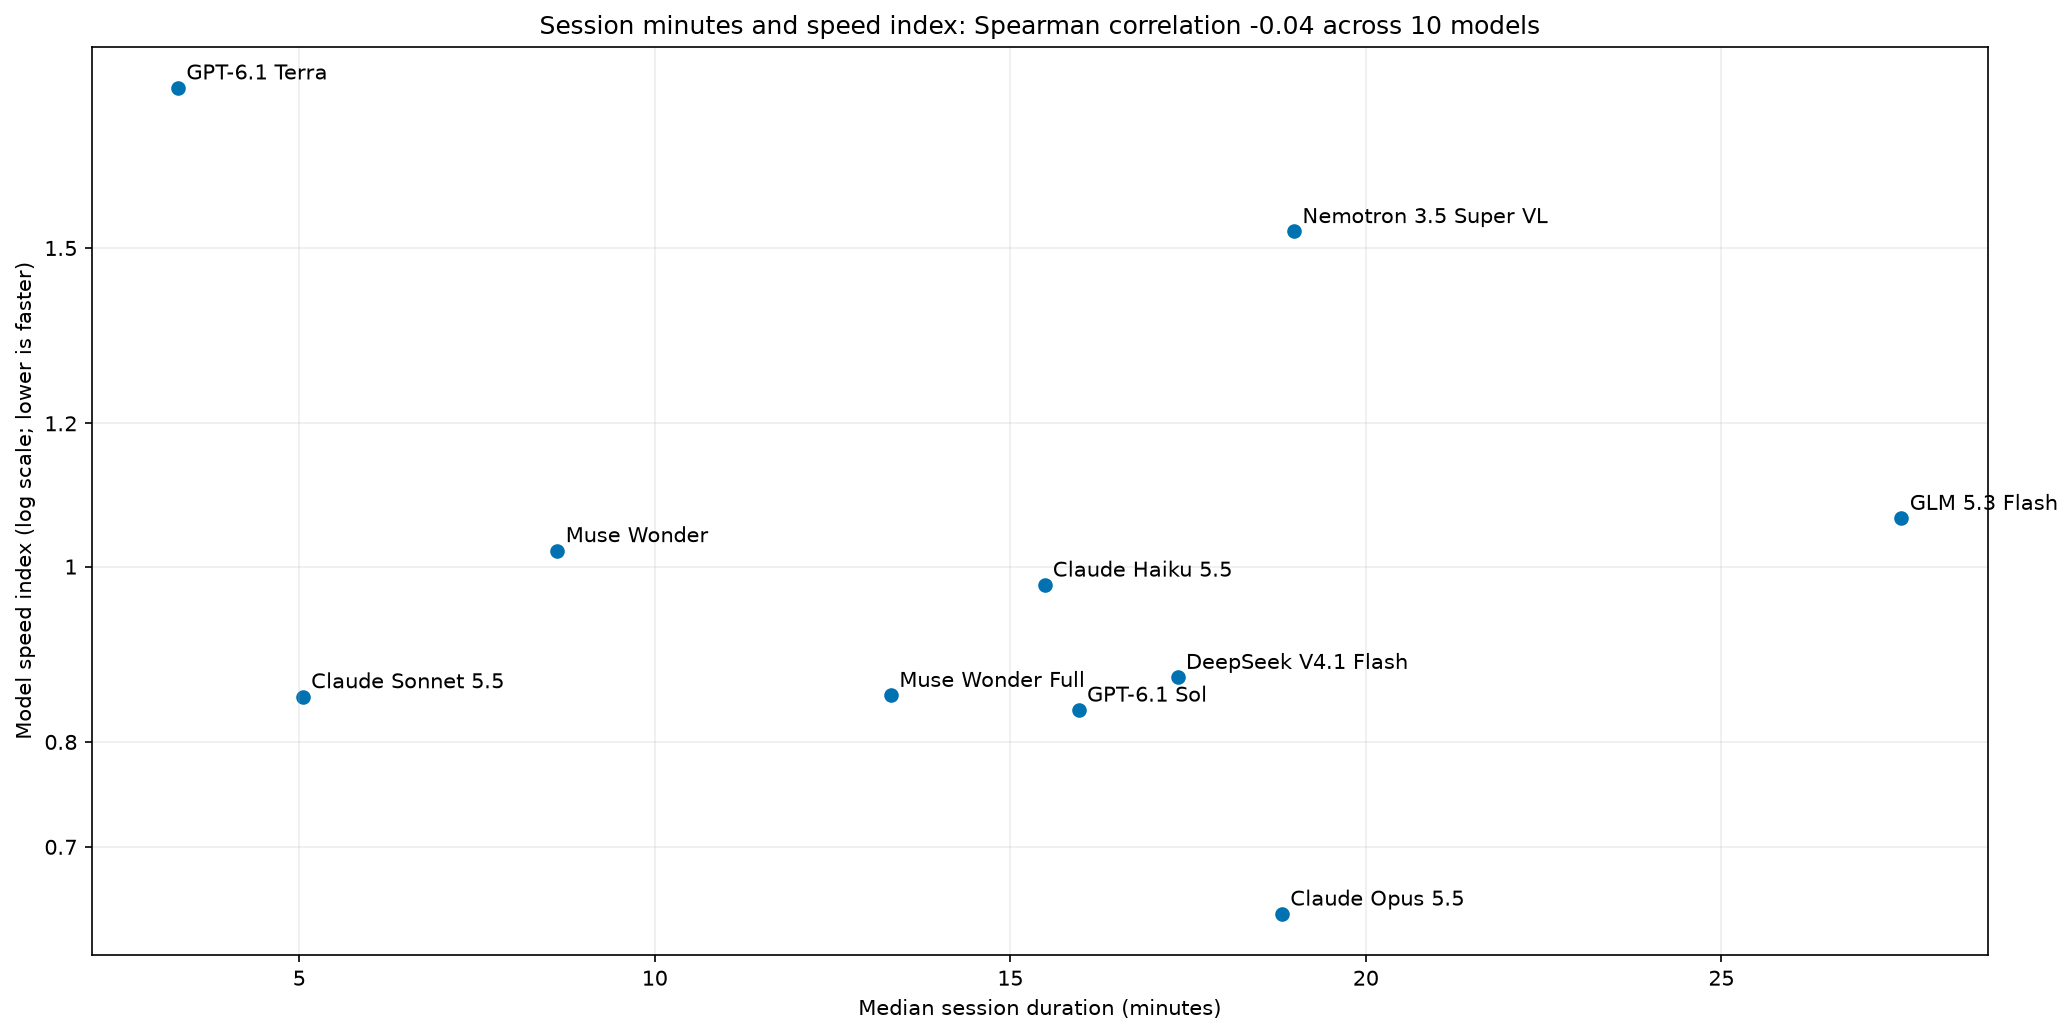

In [20]:
# Compute and present this analysis step for the reader.
dd = median[median.author.isin(ALL_AUTHORS) & median.variant.isin(MODEL_VERSIONS) & (median["median"] > 0)].copy()
# Baseline of each task-and-version cell: geometric mean of the ten agent-session models, for cells with at least five of them.
ten = dd[dd.author.isin(AUTHORS)].groupby(["task", "variant"])["median"].agg(n="size", baseline=geom)
base = ten[ten.n >= 5].baseline
d = dd.join(base, on=["task", "variant"], how="inner")
d["index"] = d["median"] / d.baseline
rows = []
for a in ALL_AUTHORS:
    x = d[d.author.eq(a)]
    g, lo, hi = task_bootstrap(x, "index")
    rows.append(dict(author=a, index=g, ci_low=lo, ci_high=hi, cells=len(x), tasks=x.task.nunique()))
model_speed = pd.DataFrame(rows)
model_speed.to_csv(DERIVED / "model_speed.csv", index=False)
with pd.option_context("display.float_format", lambda x: f"{x:.3g}"):
    display(model_speed)
print("Speed index cells per model:", model_speed.set_index("author").cells.to_dict(), "| baseline cells:", len(base))

# Alternative drift correction: divide each new program's measured time by the drift ratio of Opus's program for the same task and version.
new_day_authors = ["sol61", *ONE_REPLY]
mm = median_measured[median_measured.author.isin(new_day_authors) & median_measured.variant.isin(MODEL_VERSIONS)].copy()
mm = mm.join(DRIFT_BY_PROGRAM.rename("opus_ratio"), on=["task", "variant"]).join(base, on=["task", "variant"], how="inner")
mm["index"] = (mm.measured_median / mm.opus_ratio) / mm.baseline
variant_rows = []
for a in new_day_authors:
    g0 = model_speed.set_index("author").loc[a]
    variant_rows.append(dict(author=a, correction="one global factor", index=g0["index"], ci_low=g0.ci_low, ci_high=g0.ci_high, cells=int(g0.cells)))
    x = mm[mm.author.eq(a)]
    g, lo, hi = task_bootstrap(x, "index")
    variant_rows.append(dict(author=a, correction="per-program factor from Opus", index=g, ci_low=lo, ci_high=hi, cells=len(x)))
drift_variants = pd.DataFrame(variant_rows)
drift_variants.to_csv(DERIVED / "model_speed_drift_variants.csv", index=False)
print("Speed index of the authors timed on 2026-11-12 under the two corrections:")
with pd.option_context("display.float_format", lambda x: f"{x:.3g}"):
    display(drift_variants)
fig, ax = plt.subplots(figsize=(10, 7))
ax.axhspan(AUTHORS.index(OPEN_WEIGHT[0]) - 0.5, AUTHORS.index(OPEN_WEIGHT[-1]) + 0.5, color="#eeeeee", label="Open-weight models")
ax.axhspan(len(AUTHORS) - 0.5, len(ALL_AUTHORS) - 0.5, color="#dbe9f6", label="One reply, no tools")
for i, r in enumerate(model_speed.itertuples()):
    if np.isfinite(r.index):
        hollow = r.author in ONE_REPLY
        ax.errorbar(
            r.index, i, xerr=[[r.index - r.ci_low], [r.ci_high - r.index]], fmt="o", color="#0072B2", capsize=3,
            mfc="white" if hollow else "#0072B2", ms=8,
        )
ax.axvline(1, color="black", ls="--", label=f"Geometric mean of the {N_WORDS[len(AUTHORS)]} agent-session models (1.0)")
ax.set(
    xscale="log",
    yticks=range(len(ALL_AUTHORS)),
    yticklabels=[MODEL_LABELS[a] for a in ALL_AUTHORS],
    ylim=(len(ALL_AUTHORS) - 0.5, -0.5),
    xlabel="Model speed index (log scale; lower is faster)",
)
valid_models = model_speed.dropna(subset=["index"]).set_index("author")["index"]
ax.set_title(
    f"{MODEL_LABELS[valid_models.idxmin()]} wrote the fastest programs (index {format_number(valid_models.min())}); "
    f"{MODEL_LABELS[valid_models.idxmax()]} the slowest ({format_number(valid_models.max())})"
    if len(valid_models)
    else "No model speed indices available",
    fontsize=11,
)
plain_log_axis(ax)
ax.legend(loc="upper right")
fig.tight_layout()
savefig("model_speed.png")
grid = (
    d.groupby(["author", "variant"])["index"]
    .agg(geom)
    .unstack("variant")
    .reindex(index=ALL_AUTHORS, columns=MODEL_VERSIONS)
)
fig, ax = plt.subplots(figsize=(10, 7.5))
heatmap(ax, grid, log=True, label="Model speed index (log scale; lower is faster)")
separator_line(ax)
winner_counts = grid.dropna(axis=1, how="all").idxmin().value_counts()
winner_title = (
    f"{MODEL_LABELS[winner_counts.index[0]]} had the lowest index in "
    f"all {winner_counts.iloc[0]} versions" if winner_counts.iloc[0] == grid.notna().any().sum() else f"{MODEL_LABELS[winner_counts.index[0]]} had the lowest index in {winner_counts.iloc[0]} of {grid.notna().any().sum()} versions"
    if len(winner_counts)
    else "No model speed indices available"
)
ax.set(title=winner_title + " (of all 13 rows)", xlabel="Version", ylabel="Model")
fig.tight_layout()
savefig("model_speed_heatmap.png")
if len(d):
    d_ten = d[d.author.isin(AUTHORS)]
    extrema = (
        d_ten.assign(
            fastest=d_ten["median"].eq(d_ten.groupby(["task", "variant"])["median"].transform("min")),
            slowest=d_ten["median"].eq(d_ten.groupby(["task", "variant"])["median"].transform("max")),
        )
        .groupby("author")[["fastest", "slowest"]]
        .sum()
        .reindex(AUTHORS, fill_value=0)
    )
    print(f"Fastest and slowest of the ten agent-session models, in {d_ten.groupby(['task', 'variant']).ngroups} cells:")
    display(extrema)
    fastest_13 = d.assign(fastest=d["median"].eq(d.groupby(["task", "variant"])["median"].transform("min"))).groupby("author").fastest.sum().reindex(ALL_AUTHORS, fill_value=0)
    print(f"Cells where each author was fastest of all 13 (of {d.groupby(['task', 'variant']).ngroups}):")
    display(fastest_13.rename("fastest of 13"))
else:
    display(pd.DataFrame(0, index=AUTHORS, columns=["fastest", "slowest"]))
fig, ax = plt.subplots(figsize=(14, 7))
x = sessions[sessions.author.isin(AUTHORS)].groupby("author").minutes.median()
for r in model_speed.itertuples():
    if r.author in x and np.isfinite(r.index) and x[r.author] > 0:
        ax.scatter(x[r.author], r.index, color="#0072B2")
        ax.annotate(MODEL_LABELS[r.author], (x[r.author], r.index), xytext=(4, 4), textcoords="offset points")
paired_x = model_speed.set_index("author")["index"].to_frame().join(x.rename("minutes")).dropna()
paired_x = paired_x[paired_x.minutes > 0]
correlation = paired_x["minutes"].corr(paired_x["index"], method="spearman") if len(paired_x) >= 2 else np.nan
correlation_title = (
    f"Session minutes and speed index: Spearman correlation {correlation:.2f} across {len(paired_x)} models"
    if np.isfinite(correlation)
    else f"Session minutes and speed index: correlation unavailable ({len(paired_x)} models)"
)
ax.set(
    yscale="log",
    xlabel="Median session duration (minutes)",
    ylabel="Model speed index (log scale; lower is faster)",
    title=correlation_title,
)
plain_log_axis(ax, "y")
fig.tight_layout()
savefig("model_effort_vs_speed.png")


| Author | How it wrote | Speed index (95% interval) | Fastest of ten | Slowest of ten |
|---|---|---|---|---|
| Claude Fable 5.2 | one reply | 0.60 (0.51 to 0.71) | | |
| Claude Opus 5.5 | sessions | 0.64 (0.56 to 0.74) | 36 | 0 |
| GPT-6.1 Sol | sessions | 0.83 (0.75 to 0.94) | 5 | 0 |
| Claude Sonnet 5.5 | sessions | 0.85 (0.77 to 0.93) | 6 | 1 |
| Muse Wonder Full | sessions | 0.85 (0.74 to 0.94) | 6 | 2 |
| DeepSeek V4.1 Flash | sessions | 0.87 (0.79 to 0.96) | 5 | 0 |
| GPT-6.1 Sol | one reply | 0.94 (0.86 to 1.03) | | |
| GPT-6 Astra | one reply | 0.98 (0.91 to 1.05) | | |
| Claude Haiku 5.5 | sessions | 0.98 (0.89 to 1.07) | 0 | 7 |
| Muse Wonder | sessions | 1.02 (0.89 to 1.17) | 5 | 3 |
| GLM 5.3 Flash | sessions | 1.06 (0.96 to 1.19) | 1 | 2 |
| Nemotron 3.5 Super VL | sessions | 1.53 (1.34 to 1.77) | 0 | 21 |
| GPT-6.1 Terra | sessions | 1.84 (1.47 to 2.25) | 0 | 28 |

Among the session models, Claude Opus 5.5 wrote the fastest code: its programs took about two thirds of a typical
session model's time, were the fastest of the ten in 36 of the 64 task-and-version cells and never the slowest.
GPT-6.1 Terra (1.84) and Nemotron (1.53) were slowest and wrote 49 of the 64 slowest programs between them. The seven
models in the middle, from 0.83 to 1.06, have overlapping intervals, and their order could change in a second set of
sessions. Claude Fable 5.2's one-reply programs had the lowest index of all 13 authors (0.60) and were the fastest of
all 13 in 26 cells, against 18 for Opus; section 14 compares the two ways of writing.

The four authors timed on the second day get the same index whether their times are divided by the single factor or
by the factor for each task and language, because the geometric mean of the 64 per-program factors is the single
factor; only the intervals move, by at most 0.01.

By version, Opus had the lowest index of the session models in all eight, from 0.55 in C# to 0.71 in Java, so its
lead was not one language's. Terra's index was highest in C++ (2.95), Go (2.2) and C# (2.1), the languages where it
parsed with general libraries, and Nemotron's in NumPy Python (2.0).

Within each company the larger model wrote faster code: Opus (0.64) ahead of Sonnet (0.85) and Haiku (0.98), Sol
(0.83) ahead of Terra (1.84), and Wonder Full (0.85) ahead of Wonder (1.02). Across companies, openness did not sort
the models: the open-weight DeepSeek was level with Sonnet, Sol and Wonder Full.

Longer sessions did not buy faster code. The rank correlation between a model's median session length and its index
is -0.04 across the ten models: Opus spent 19 minutes per session and wrote the fastest code, Nemotron spent as long
with the most tool calls and wrote nearly the slowest, and GLM had the longest sessions and a middling index. Terra
is the one model where little effort and slow code went together: the shortest sessions, the fewest output tokens
and the shortest code (127 kB over 64 programs against 304 to 448 kB, section 19). In cost, Opus's sessions came to
five times Sonnet's for programs about a quarter faster, and DeepSeek matched Sonnet's speed at about the same price.

The next cell compares the heat programs of every session model with those of the two pilot models, Claude Opus 5.5
and GPT-6.1 Sol, which wrote heat in Rust and both Pythons only, in the first test of the pipeline on 2026-10-30. The
last column divides Opus's main-run times by its pilot times.

In [21]:
pilot=median[(median.task=='heat') & median.author.isin(['opus','sol']+AUTHORS) & median.variant.isin(['rust','plain','fast'])].pivot(index='variant',columns='author',values='median').reindex(index=['rust','plain','fast'],columns=['opus','sol']+AUTHORS)
pilot['opus55 / opus']=pilot['opus55']/pilot['opus']; display(pilot)


author,opus,sol,opus55,sonnet,haiku,sol61,terra,wonder-full,wonder,deepseek,glm,nemotron,opus55 / opus
variant,,,,,,,,,,,,,
rust,0.038,0.037,0.037,0.054,0.041,0.049,0.16,0.081,0.07,0.052,0.054,0.18,0.98
plain,0.59,0.95,0.47,0.87,1.0,6.3,6.8,0.99,0.88,0.85,9.8,6.1,0.79
fast,0.4,0.33,0.35,0.39,0.37,0.41,0.39,0.46,0.38,0.38,0.45,1.8,0.87


The two pilot models' heat Rust took 0.038 and 0.037 s, level with the main-run Opus (0.037 s) and Haiku (0.041 s).
The pilots are also the only repeated sessions in the study, and they show how much one session's choices can vary.
Opus's two heat sessions, six days apart, gave Rust programs within 3% of each other and plain Python of 0.59 and
0.47 s, both packed integers. Sol's did not: its pilot packed the grid (plain Python 0.95 s), while its full session
ten days later looped over the cells (6.3 s), 6.6 times slower. Sol's one-reply program (section 14) packed it again
(1.00 s). One model's plain-Python heat varied more between two of its own sessions than between most pairs of models.

## 14. Agent sessions against a single reply

Sections 8 to 13 show that the one-reply programs were all correct and, on average, close to the session programs in
speed. This section looks at that comparison directly. Two questions need different evidence. What does the agent
loop add for one model? GPT-6.1 Sol wrote every program both ways, so its 64 pairs answer that with the model held
fixed; both were timed on the same day, so the drift correction does not affect them. How far can one reply go? GPT-6
Astra and Claude Fable 5.2 wrote only single replies, so their programs are compared with session programs from
other models, which mixes the model with the method.

The first cell measures effort and cost per program. For Sol's sessions, the totals over its 16 sessions are divided
by the 64 programs they produced; for the one-reply authors each call is one program. Costs are at list prices per
million tokens: GPT-6.1 Sol USD 2.00 input, 0.10 cached input and 10.00 output; GPT-6 Astra 10, 1 and 50; Claude
Fable 5.2 8 input and 40 output. The cell also counts how many one-reply calls produced a parseable reply, a program
that built, passed the samples and passed the hidden inputs.

In [22]:
# Effort and cost per program: GPT-6.1 Sol as an agent (16 sessions) against the three one-reply authors (64 calls each).
oneshot = pd.read_csv(DATA / "oneshot" / "summary.csv")
sol_sessions = sessions[sessions.author.eq("sol61")]
effort_rows = [dict(
    method="GPT-6.1 Sol, agent sessions", calls=len(sol_sessions), programs=64,
    input_tokens_per_program=sol_sessions.all_input_tokens.sum() / 64, cached_tokens_per_program=sol_sessions.cached_input_tokens.sum() / 64,
    output_tokens_per_program=sol_sessions.output_tokens.sum() / 64, reasoning_tokens_per_program=sol_sessions.reasoning_tokens.sum() / 64,
    minutes_per_program=sol_sessions.minutes.sum() / 64, list_cost_per_program=sol_sessions.list_cost_usd.sum() / 64,
    total_minutes=sol_sessions.minutes.sum(), total_list_cost=sol_sessions.list_cost_usd.sum())]
for author in ONE_REPLY:
    g = oneshot[oneshot.model.eq(ONESHOT_MODEL[author])]
    effort_rows.append(dict(
        method=MODEL_LABELS[author], calls=len(g), programs=len(g),
        input_tokens_per_program=g.input_tokens.mean(), cached_tokens_per_program=g.cached_input_tokens.mean(),
        output_tokens_per_program=g.output_tokens.mean(), reasoning_tokens_per_program=g.reasoning_tokens.mean(),
        minutes_per_program=g.wall_seconds.mean() / 60, list_cost_per_program=g.cost_usd.mean(),
        total_minutes=g.wall_seconds.sum() / 60, total_list_cost=g.cost_usd.sum()))
effort = pd.DataFrame(effort_rows).set_index("method")
with pd.option_context("display.float_format", lambda x: f"{x:,.2f}", "display.width", 250, "display.max_columns", 20):
    display(effort)
print("Claude Code's own cost figure for the Fable calls (cli_cost_usd, total):",
      round(oneshot.loc[oneshot.model.eq("fable"), "cli_cost_usd"].sum(), 2), "against list price", round(oneshot.loc[oneshot.model.eq("fable"), "cost_usd"].sum(), 2))
outcome = oneshot.groupby("model").apply(lambda g: pd.Series(dict(
    calls=len(g), parse_ok=int(g.parse_status.eq("ok").sum()), built=int(g.built.sum()),
    passed_samples=int((g.samples_passed == g.samples_total).sum()), passed_hidden=int((g.hidden_passed == g.hidden_total).sum()))),
    include_groups=False).reindex(["sol", "astra", "fable"])
print("One-reply outcomes (of 64 calls per model):")
display(outcome)


,calls,programs,input_tokens_per_program,cached_tokens_per_program,output_tokens_per_program,reasoning_tokens_per_program,minutes_per_program,list_cost_per_program,total_minutes,total_list_cost
method,,,,,,,,,,
"GPT-6.1 Sol, agent sessions",16,64,"588,849.16","574,150.00","8,754.44","3,787.58",5.08,0.17,325.03,11.16
GPT-6.1 Sol (one reply),64,64,"15,090.94","6,534.00","5,332.69","3,802.81",2.36,0.07,150.87,4.55
GPT-6 Astra (one reply),64,64,"14,993.28","6,038.00","3,841.12","2,368.38",1.92,0.29,122.82,18.41
Claude Fable 5.2 (one reply),64,64,"3,347.58",0.00,"21,681.64","18,171.89",3.63,0.92,232.57,58.93


Claude Code's own cost figure for the Fable calls (cli_cost_usd, total): 36.83 against list price 58.93
One-reply outcomes (of 64 calls per model):


,calls,parse_ok,built,passed_samples,passed_hidden
model,,,,,
sol,64,64,64,64,64
astra,64,64,64,64,64
fable,64,64,64,64,64


A one-reply program cost Sol 40 times fewer input tokens than a session program (15,100 against 589,000) and about
40% fewer output tokens (5,300 against 8,800), and took 2.4 minutes instead of 5.1. In money that is USD 4.55 for the
64 programs against USD 11.2 for the sessions, 2.5 times less rather than 40 times, because a session's repeated
input is mostly cached and cached input is billed at a twentieth of the price. Codex adds about 12,000 input tokens
of its own to every call, which is most of Sol's and Astra's one-reply input; Claude Code added little to Fable's
(3,300 input tokens per program).

One reply is not always cheap. Astra's list prices are five times Sol's, so its 64 programs cost USD 18.41. Fable
wrote 21,700 output tokens per program, 18,200 of them reasoning, at USD 40 per million, so its 64 replies cost USD
58.93, more than Opus's 16 sessions (USD 40 at Claude Code's list-price estimate). All 192 calls returned a reply with
one code block, every program built, and every program passed both its samples and the hidden inputs: none needed a
second attempt.

The next cell pairs each of Sol's one-reply programs with its session program for the same task and version and
divides the one-reply time by the session time. A ratio above 1 means the one-reply program was slower. The figure
plots every pair: the session program's median time across, the one-reply program's up, both in seconds on log
scales, coloured and shaped by version. Points above the solid diagonal were slower in one reply; the dotted lines
mark twice as slow and twice as fast.

GPT-6.1 Sol, one-reply time / session time: geometric mean ratio 1.13 (95% interval 1.00 to 1.29, tasks resampled 10,000 times) over 64 programs
  first faster in 25; within 10% in 26; first more than 2x slower in 9; more than 2x faster in 1
By version: {'rust': 1.37, 'cpp': 1.0, 'go': 1.18, 'csharp': 1.26, 'java': 1.14, 'js': 1.08, 'fast': 1.26, 'plain': 0.84}
By task: {'springs': 1.11, 'wordpairs': 1.56, 'ledger': 0.96, 'logscan': 1.01, 'routes': 1.22, 'align': 1.38, 'heat': 0.85, 'walkers': 1.09}


,task,variant,one-reply seconds,session seconds,ratio
14,heat,plain,0.996,6.28,0.159
34,routes,fast,5.25,1.18,4.43
59,wordpairs,go,2.88,0.828,3.47
7,align,rust,0.212,0.0726,2.92
55,walkers,rust,0.284,0.105,2.71
1,align,csharp,0.433,0.162,2.68
60,wordpairs,java,2.82,1.06,2.66
57,wordpairs,csharp,1.93,0.804,2.4


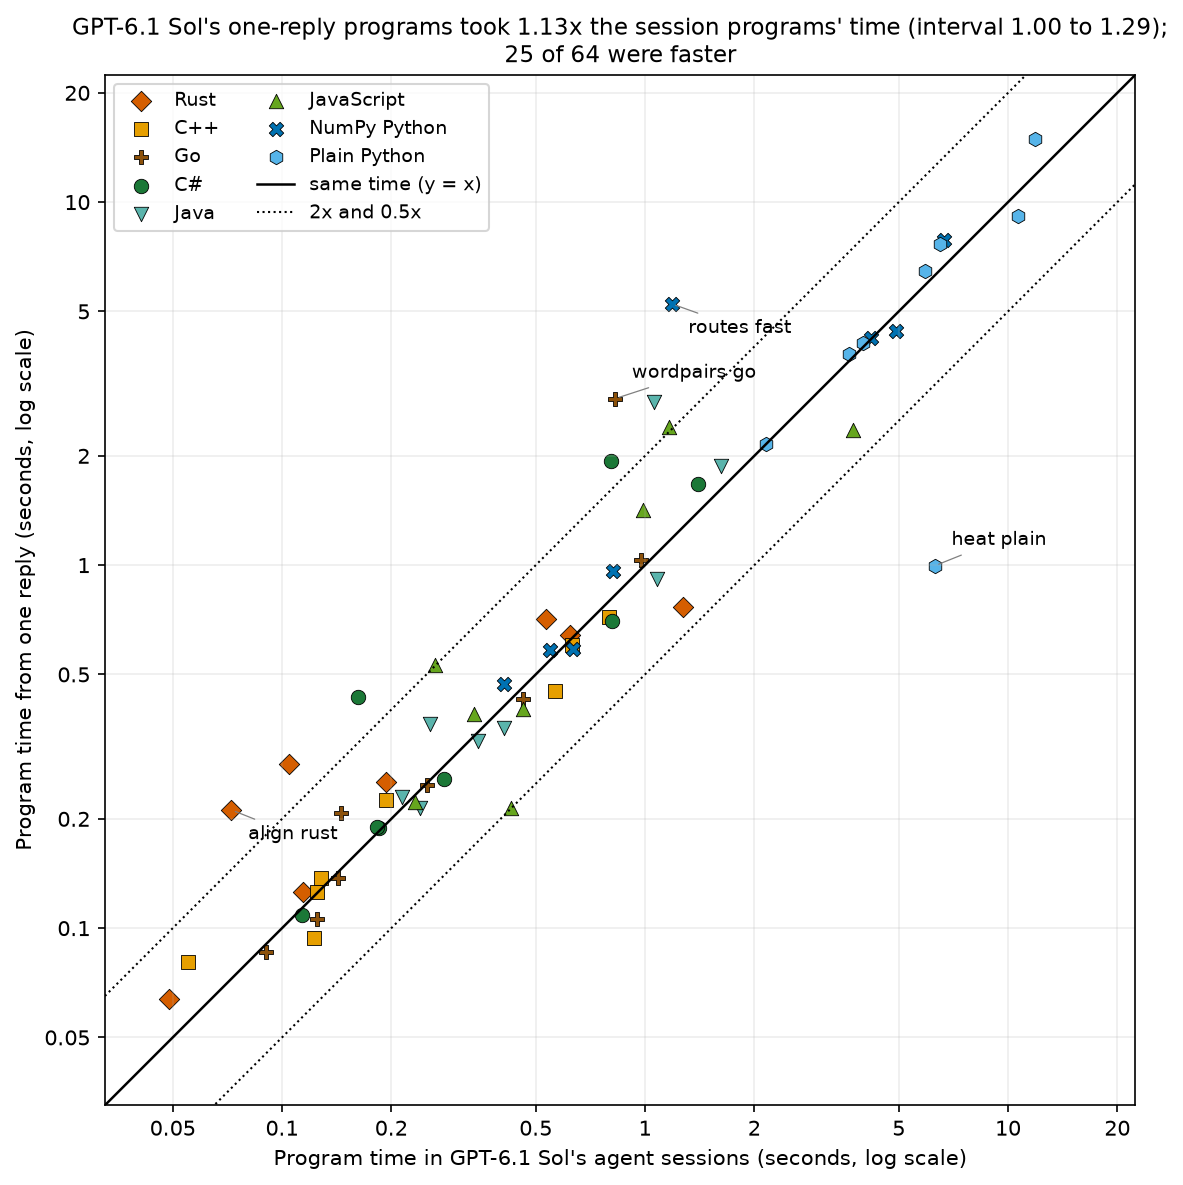

In [23]:
# Same model, two methods: GPT-6.1 Sol's agent sessions against its one-reply programs, matched by task and version.
def paired(first, second):
    a = median[median.author.eq(first)].set_index(["task", "variant"])["median"]
    b = median[median.author.eq(second)].set_index(["task", "variant"])["median"]
    j = pd.concat([a.rename("first"), b.rename("second")], axis=1, join="inner").reset_index()
    j = j[(j["first"] > 0) & (j["second"] > 0)].copy()
    j["ratio"] = j["first"] / j["second"]
    return j


def pair_summary(j, label):
    g, lo, hi = task_bootstrap(j, "ratio")
    print(f"{label}: geometric mean ratio {g:.2f} (95% interval {lo:.2f} to {hi:.2f}, tasks resampled 10,000 times) over {len(j)} programs")
    print(f"  first faster in {int((j.ratio < 1).sum())}; within 10% in {int(((j.ratio - 1).abs() <= 0.10).sum())}; "
          f"first more than 2x slower in {int((j.ratio > 2).sum())}; more than 2x faster in {int((j.ratio < 0.5).sum())}")
    return g, lo, hi


sol_pair = paired("sol61-oneshot", "sol61")
sg, slo, shi = pair_summary(sol_pair, "GPT-6.1 Sol, one-reply time / session time")
print("By version:", {v: round(float(geom(sol_pair.ratio[sol_pair.variant.eq(v)])), 2) for v in MODEL_VERSIONS})
print("By task:", {t: round(float(geom(sol_pair.ratio[sol_pair.task.eq(t)])), 2) for t in TASKS})
extreme = sol_pair.assign(gap=np.abs(np.log(sol_pair.ratio))).nlargest(8, "gap")
with pd.option_context("display.float_format", lambda x: f"{x:.3g}"):
    display(extreme[["task", "variant", "first", "second", "ratio"]].rename(columns={"first": "one-reply seconds", "second": "session seconds"}))
fig, ax = plt.subplots(figsize=(8.5, 8))
for v in MODEL_VERSIONS:
    d_ = sol_pair[sol_pair.variant.eq(v)]
    ax.scatter(d_.second, d_["first"], color=COLORS[v], marker=MARKERS[v], s=48, edgecolor="black", linewidth=0.4, label=LABELS[v])
lims = (min(sol_pair.second.min(), sol_pair["first"].min()) / 1.5, max(sol_pair.second.max(), sol_pair["first"].max()) * 1.5)
line = np.array(lims)
ax.plot(line, line, color="black", lw=1.2, label="same time (y = x)")
ax.plot(line, 2 * line, color="black", lw=1, ls=":", label="2x and 0.5x")
ax.plot(line, line / 2, color="black", lw=1, ls=":")
for k, r in enumerate(extreme.head(4).itertuples()):
    ax.annotate(f"{r.task} {r.variant}", (r.second, r.first), xytext=(8, 10 if k % 2 == 0 else -14), textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="-", color="gray", lw=0.6))
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="Program time in GPT-6.1 Sol's agent sessions (seconds, log scale)",
       ylabel="Program time from one reply (seconds, log scale)")
plain_log_axis(ax, "x")
plain_log_axis(ax, "y")
ax.set_aspect("equal")
ax.set_title(f"GPT-6.1 Sol's one-reply programs took {sg:.2f}x the session programs' time (interval {slo:.2f} to {shi:.2f});\n"
             f"{int((sol_pair.ratio < 1).sum())} of {len(sol_pair)} were faster", fontsize=11)
ax.legend(loc="upper left", fontsize=9, ncol=2)
fig.tight_layout()
savefig("one_reply_vs_agent.png")


Sol's one-reply programs took 1.13 times as long as its session programs (geometric mean of the 64 ratios; 95%
interval 1.00 to 1.29 from resampling tasks), so the session programs were faster on average, by an amount whose
interval just reaches no difference. The pairs are not evenly spread around that average. 25 of the 64 one-reply
programs were faster, and 26 were within 10% of the session program either way, so for most programs the method
made little difference. But 9 one-reply programs were more than twice as slow and only 1 more than twice as fast, and
those few account for most of the average.

The slow ones cluster. By task, wordpairs (1.56) and align (1.38) lost most, while heat (0.85) and ledger (0.96)
gained; by version, Rust (1.37) lost most and plain Python (0.84) gained. The extreme pairs are NumPy routes (5.2 s
in one reply against 1.2 s in the session, 4.4 times), Go wordpairs (3.5 times), Rust align (2.9), Rust walkers (2.7),
C# align (2.7) and Java and C# wordpairs (2.7 and 2.4). Three of the eight are wordpairs in a garbage-collected
language. The one large gain is plain-Python heat, 6.3 times faster in one reply (1.0 s against 6.3 s), where the
reply packed the grid into one integer and the session looped over cells. Section 20 reads the routes and wordpairs
programs.

A practical reading: a one-reply program from Sol was usually as fast as its session program, but about one in seven
was more than twice as slow, and nothing in the reply showed which. A session could catch such a program because it
timed its own work on large inputs; a one-reply program would need the same check afterwards.

The next cell compares the other one-reply authors with session models, program by program, with the same task
resampling: Fable against Opus (the two fastest authors), Astra against Sonnet and against Sol's sessions, and Sol's
one-reply programs against Sonnet. These pairs cross models as well as methods, and Fable's, Astra's and the one-reply
Sol programs were timed on the second day, so their times carry the drift correction.

In [24]:
# One-reply models against agent-session models, program by program.
CROSS = [("fable-oneshot", "opus55"), ("astra-oneshot", "sonnet"), ("astra-oneshot", "sol61"), ("sol61-oneshot", "sonnet")]
cross_rows = []
for first, second in CROSS:
    j = paired(first, second)
    g, lo, hi = pair_summary(j, f"{SHORT[first]} / {SHORT[second]}")
    print("  by task:", {t: round(float(geom(j.ratio[j.task.eq(t)])), 2) for t in TASKS})
    cross_rows.append(dict(first=MODEL_LABELS[first], second=MODEL_LABELS[second], programs=len(j), geometric_mean=g, ci_low=lo, ci_high=hi,
                           first_faster=int((j.ratio < 1).sum())))
with pd.option_context("display.float_format", lambda x: f"{x:.3g}", "display.width", 200):
    display(pd.DataFrame(cross_rows))


Fable 1R / Opus: geometric mean ratio 0.93 (95% interval 0.83 to 1.04, tasks resampled 10,000 times) over 64 programs
  first faster in 39; within 10% in 23; first more than 2x slower in 1; more than 2x faster in 1
  by task: {'springs': 1.04, 'wordpairs': 0.84, 'ledger': 0.71, 'logscan': 0.77, 'routes': 0.97, 'align': 1.13, 'heat': 1.16, 'walkers': 0.93}
Astra 1R / Sonnet: geometric mean ratio 1.15 (95% interval 1.05 to 1.24, tasks resampled 10,000 times) over 64 programs
  first faster in 24; within 10% in 18; first more than 2x slower in 7; more than 2x faster in 0
  by task: {'springs': 1.2, 'wordpairs': 1.25, 'ledger': 1.34, 'logscan': 1.21, 'routes': 0.88, 'align': 1.16, 'heat': 1.06, 'walkers': 1.18}
Astra 1R / Sol: geometric mean ratio 1.17 (95% interval 1.02 to 1.34, tasks resampled 10,000 times) over 64 programs
  first faster in 26; within 10% in 21; first more than 2x slower in 10; more than 2x faster in 1
  by task: {'springs': 1.12, 'wordpairs': 1.51, 'ledger': 1.0, 'logs

Sol 1R / Sonnet: geometric mean ratio 1.11 (95% interval 1.01 to 1.21, tasks resampled 10,000 times) over 64 programs
  first faster in 23; within 10% in 17; first more than 2x slower in 5; more than 2x faster in 3
  by task: {'springs': 1.19, 'wordpairs': 1.29, 'ledger': 1.28, 'logscan': 1.19, 'routes': 0.84, 'align': 1.06, 'heat': 1.1, 'walkers': 1.0}


,first,second,programs,geometric_mean,ci_low,ci_high,first_faster
0,Claude Fable 5.2 (one reply),Claude Opus 5.5,64,0.931,0.826,1.04,39
1,GPT-6 Astra (one reply),Claude Sonnet 5.5,64,1.15,1.05,1.24,24
2,GPT-6 Astra (one reply),GPT-6.1 Sol,64,1.17,1.02,1.34,26
3,GPT-6.1 Sol (one reply),Claude Sonnet 5.5,64,1.11,1.01,1.21,23


Fable's single replies took 0.93 times as long as Opus's session programs (95% interval 0.83 to 1.04) and were
faster in 39 of 64 cells; only one Fable program was more than twice as slow as Opus's, and one more than twice as
fast. By task Fable was faster on ledger (0.71), logscan (0.77) and wordpairs (0.84), the text and table tasks, and
slower on heat (1.16) and align (1.13), where Opus's programs were already near their start-up floors. The interval
includes 1.0, so the evidence supports calling them level, not ranking them. Because Fable was never run in sessions
and Opus never in one reply, this comparison cannot say whether Fable's lead on the text tasks comes from the model,
from its long reasoning before answering, or from the exact contracts in its prompt.

Astra's single replies took 1.15 times as long as Sonnet's session programs (1.05 to 1.24) and 1.17 times as long as
Sol's sessions (1.02 to 1.34); 7 and 10 of its programs were more than twice as slow. Sol's single replies took 1.11
times as long as Sonnet's sessions (1.01 to 1.21). So OpenAI's two models in one reply landed close to the middle of
the session models, with a tail of slow programs, while Anthropic's most capable model in one reply matched the best
session model.

## 15. Start-up cost

Every runtime pays a fixed cost before it does any work. The next cell runs a program that prints one word and
exits, 20 times in each runtime, and draws the median start-up time and peak memory as bars.

,startup_s,working_set_MB,repeats
version,,,
Rust,0.027,4.5,20
C++,0.028,4.0,20
Go,0.03,6.0,20
C#,0.083,22,20
Java,0.11,42,20
JavaScript,0.079,27,20
NumPy Python,0.26,26,20
Plain Python,0.1,14,20


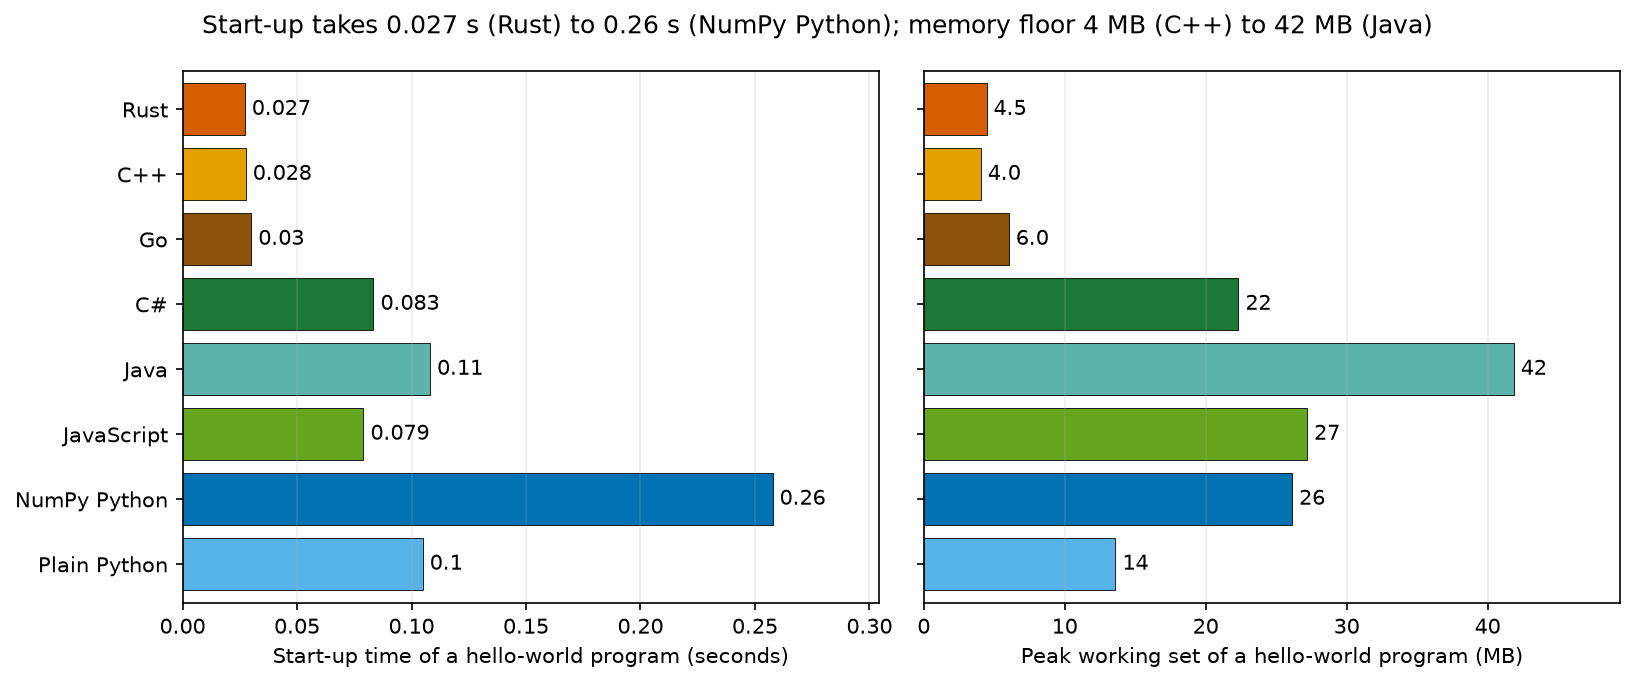

In [25]:
# Compute and present this analysis step for the reader.
# Hello-world programs in every runtime: the cost of starting the runtime before any task work happens.
BASE_VERSION = dict(
    python="plain", numpy="fast", rust="rust", cpp="cpp", go="go", csharp="csharp", java="java", js="js"
)
bl = baseline.copy()
bl["version"] = bl.variant.map(BASE_VERSION)
floor = (
    bl.groupby("version")
    .agg(
        startup_s=("wall_seconds", "median"),
        working_set_MB=("peak_working_set", lambda x: x.median() / 1e6),
        repeats=("wall_seconds", "size"),
    )
    .reindex([v for v in VERSIONS if v != "simple"])
)
display(floor.rename(index=LABELS).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, col, xl in zip(
    axes,
    ["startup_s", "working_set_MB"],
    ["Start-up time of a hello-world program (seconds)", "Peak working set of a hello-world program (MB)"],
):
    ys = range(len(floor))
    ax.barh(list(ys), floor[col], color=[COLORS[v] for v in floor.index], edgecolor="black", linewidth=0.4)
    for y, (v, x) in zip(ys, floor[col].items()):
        if pd.notna(x):
            ax.text(x, y, f" {format_number(x)}", va="center", fontsize=10)
    ax.set(
        yticks=list(ys),
        yticklabels=[LABELS[v] for v in floor.index],
        xlabel=xl,
        ylim=(len(floor) - 0.4, -0.6),
        xlim=(0, floor[col].max() * 1.18 if floor[col].notna().any() else 1),
    )
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
slow_s, fast_s = (
    (floor.startup_s.idxmax(), floor.startup_s.idxmin()) if floor.startup_s.notna().any() else ("rust", "rust")
)
big_m, small_m = (
    (floor.working_set_MB.idxmax(), floor.working_set_MB.idxmin())
    if floor.working_set_MB.notna().any()
    else ("rust", "rust")
)
fig.suptitle(
    f"Start-up takes {floor.startup_s.min():.3f} s ({LABELS[fast_s]}) "
    f"to {floor.startup_s.max():.2f} s ({LABELS[slow_s]}); memory "
    f"floor {floor.working_set_MB.min():.0f} MB ({LABELS[small_m]}) "
    f"to {floor.working_set_MB.max():.0f} MB ({LABELS[big_m]})",
    fontsize=12,
)
fig.tight_layout()
savefig("startup_floor.png")


An empty program took 0.027 s and 4.5 MB in Rust, 0.028 s and 4.0 MB in C++, 0.030 s and 6.0 MB in Go, 0.079 s and
27 MB in Node.js, 0.083 s and 22 MB in .NET, 0.10 s and 14 MB in Python, 0.11 s and 42 MB in Java, and 0.26 s and
26 MB in Python that imports NumPy. Windows starts processes more slowly than Linux, so all of these are higher than
they would be on a Linux server, but their order would be the same. These floors explain much of the small-input
results in section 17 and part of every short task's time.

## 16. Memory

The figure has the same layout as the run-time figure, with peak memory in megabytes on a logarithmic x-axis. The
table after it gives each version's geometric-mean memory relative to the same model's smallest version on each
task.

author,opus55,sonnet,haiku,sol61,terra,wonder-full,wonder,deepseek,glm,nemotron
variant,,,,,,,,,,
rust,1.1,1.5,1.1,1.1,1.3,1.5,1.9,1.4,2.0,2.1
cpp,1.1,1.0,1.1,1.0,1.1,2.2,1.8,1.7,1.9,1.7
go,1.7,1.5,1.5,1.4,1.8,3.2,2.4,2.3,2.4,2.9
csharp,3.4,3.2,3.4,3.3,4.0,6.0,4.5,4.7,4.5,4.5
java,6.3,5.7,6.3,6.1,9.1,11,8.4,8.4,8.4,8.9
js,4.6,4.0,4.8,4.8,6.1,8.2,5.8,6.1,5.7,6.9
fast,8.1,5.6,9.6,3.9,4.2,8.0,7.7,6.8,7.5,8.7
plain,5.0,4.1,4.4,3.7,4.0,3.7,6.6,5.0,3.8,4.0
simple,4.7,4.2,4.6,4.8,4.6,4.8,3.7,4.6,3.7,3.5


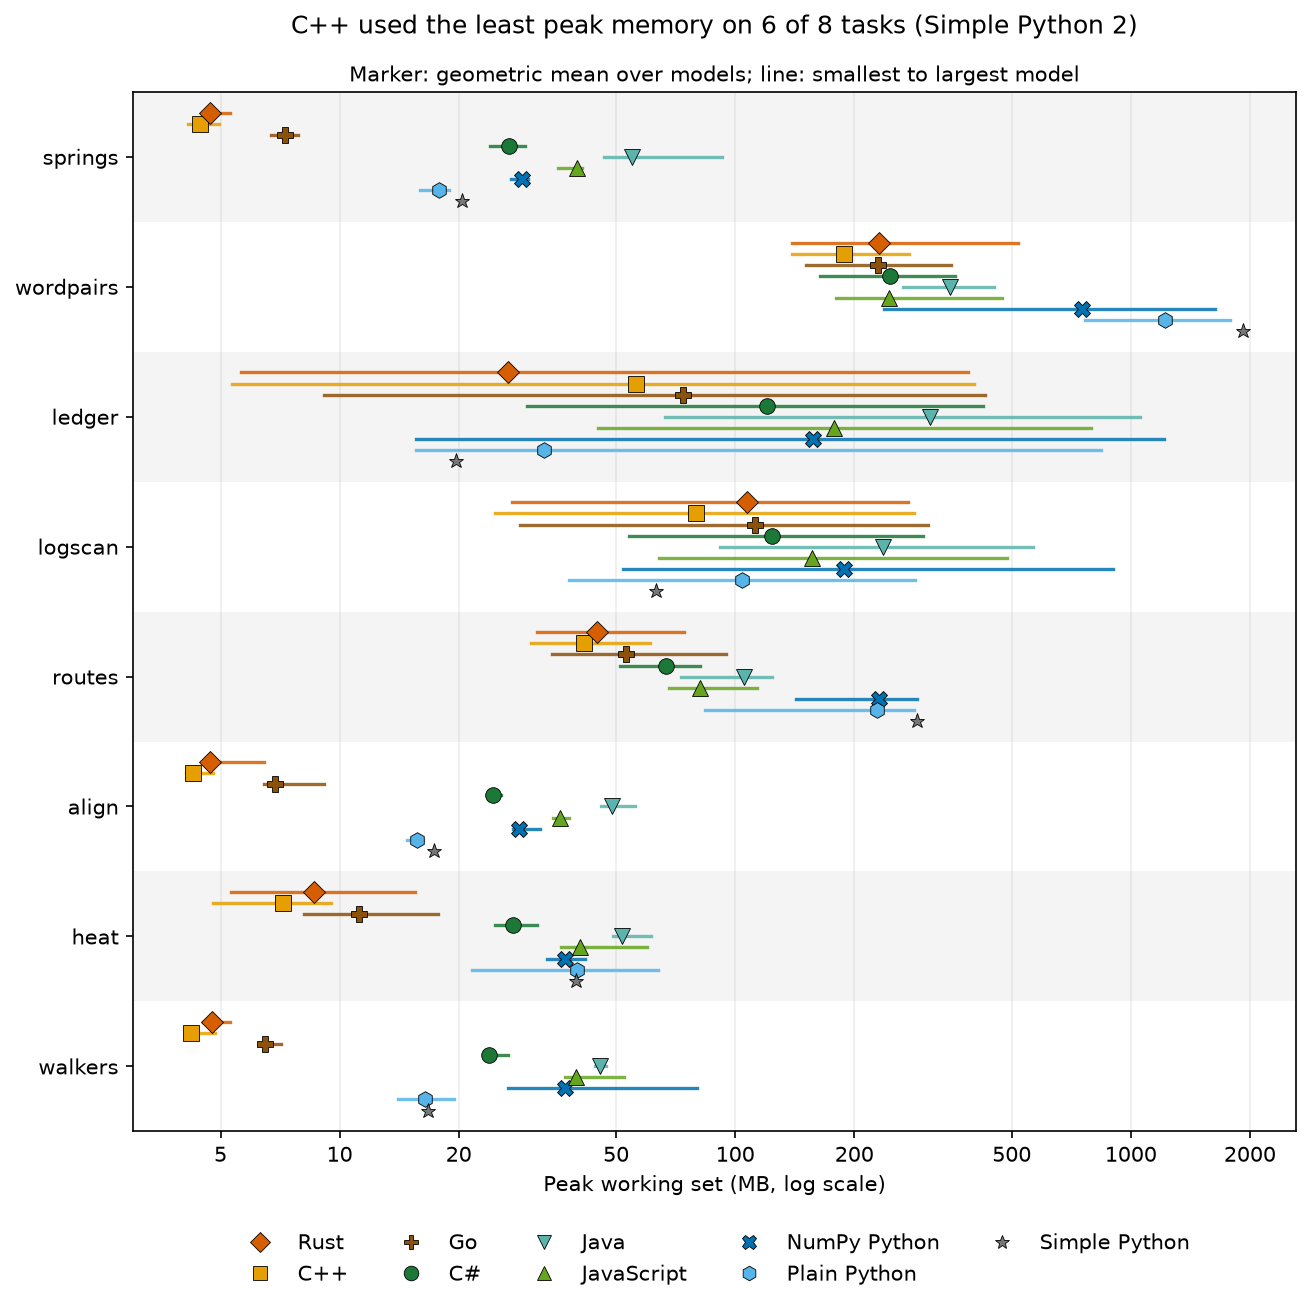

In [26]:
mem=full[full.author.isin(AUTHORS+['reference'])].copy(); mem['memory_MB']=mem.peak_working_set/1e6
memory=mem.groupby(['task','author','variant']).memory_MB.median().reset_index(); memory.to_csv(DERIVED/'memory.csv',index=False)
rows=[]
for a in AUTHORS:
    for t in TASKS:
        vals={v:memory[(memory.task==t)&(memory.author==('reference' if v=='simple' else a))&(memory.variant==v)].memory_MB for v in VERSIONS}
        vals={v:x.iloc[0] for v,x in vals.items() if len(x) and x.iloc[0]>0}
        if vals:
            low=min(vals.values()); rows.extend(dict(author=a,variant=v,ratio=x/low) for v,x in vals.items())
mr=pd.DataFrame(rows,columns=['author','variant','ratio'])
display(mr.groupby(['variant','author']).ratio.agg(geom).unstack('author').reindex(index=VERSIONS,columns=AUTHORS))
mem_comb=combine_authors(memory,'memory_MB'); title,_=winners_title(mem_comb,'used the least peak memory')
fig,ax=plt.subplots(figsize=(10,9)); strip_by_task(ax,mem_comb,'Peak working set (MB, log scale)'); ax.set_title(title, pad=28); ax.text(.5,1.01,'Marker: geometric mean over models; line: smallest to largest model',transform=ax.transAxes,ha='center'); ax.legend(handles=version_handles(ls='none'),loc='upper center',bbox_to_anchor=(.5,-.08),ncol=5,frameon=False); savefig('memory_by_task.png')


Relative to each model's smallest version on each task, C++ needed 1.0 to 2.2 times the smallest (geometric mean
over tasks, range over the ten session models), Rust 1.1 to 2.1, Go 1.4 to 3.2, C# 3.2 to 6.0, JavaScript 4.0 to 8.2,
Java 5.7 to 11, plain Python 3.7 to 6.6 and NumPy Python 3.9 to 9.6.

On small-data tasks the difference is mostly the runtime itself: a few megabytes for the compiled languages against
tens for the virtual machines and Python. On large-data tasks it is how data is stored. The plain-Python wordpairs
programs, which keep about 4 million word pairs as Python objects, peaked at 0.8 to 1.8 GB and the simple reference
at 1.9 GB, against 0.14 to 0.27 GB for the models' C++. Java's virtual machine lets its heap grow before collecting
garbage, which is why Java used more memory than Python on several tasks.

## 17. Small inputs and start-up time

Wordpairs, routes and heat were also run at 1/256, 1/64, 1/16 and 1/4 of the benchmark size, three timed runs each.
Each panel is one task, with input size and run time on logarithmic axes and one line per version (geometric mean
of the ten session models). The first table gives each version's slope between the two largest sizes (1 means time grows
in proportion to input; near 0 means the time is mostly fixed cost); the second gives each version's time relative
to Rust at each size.

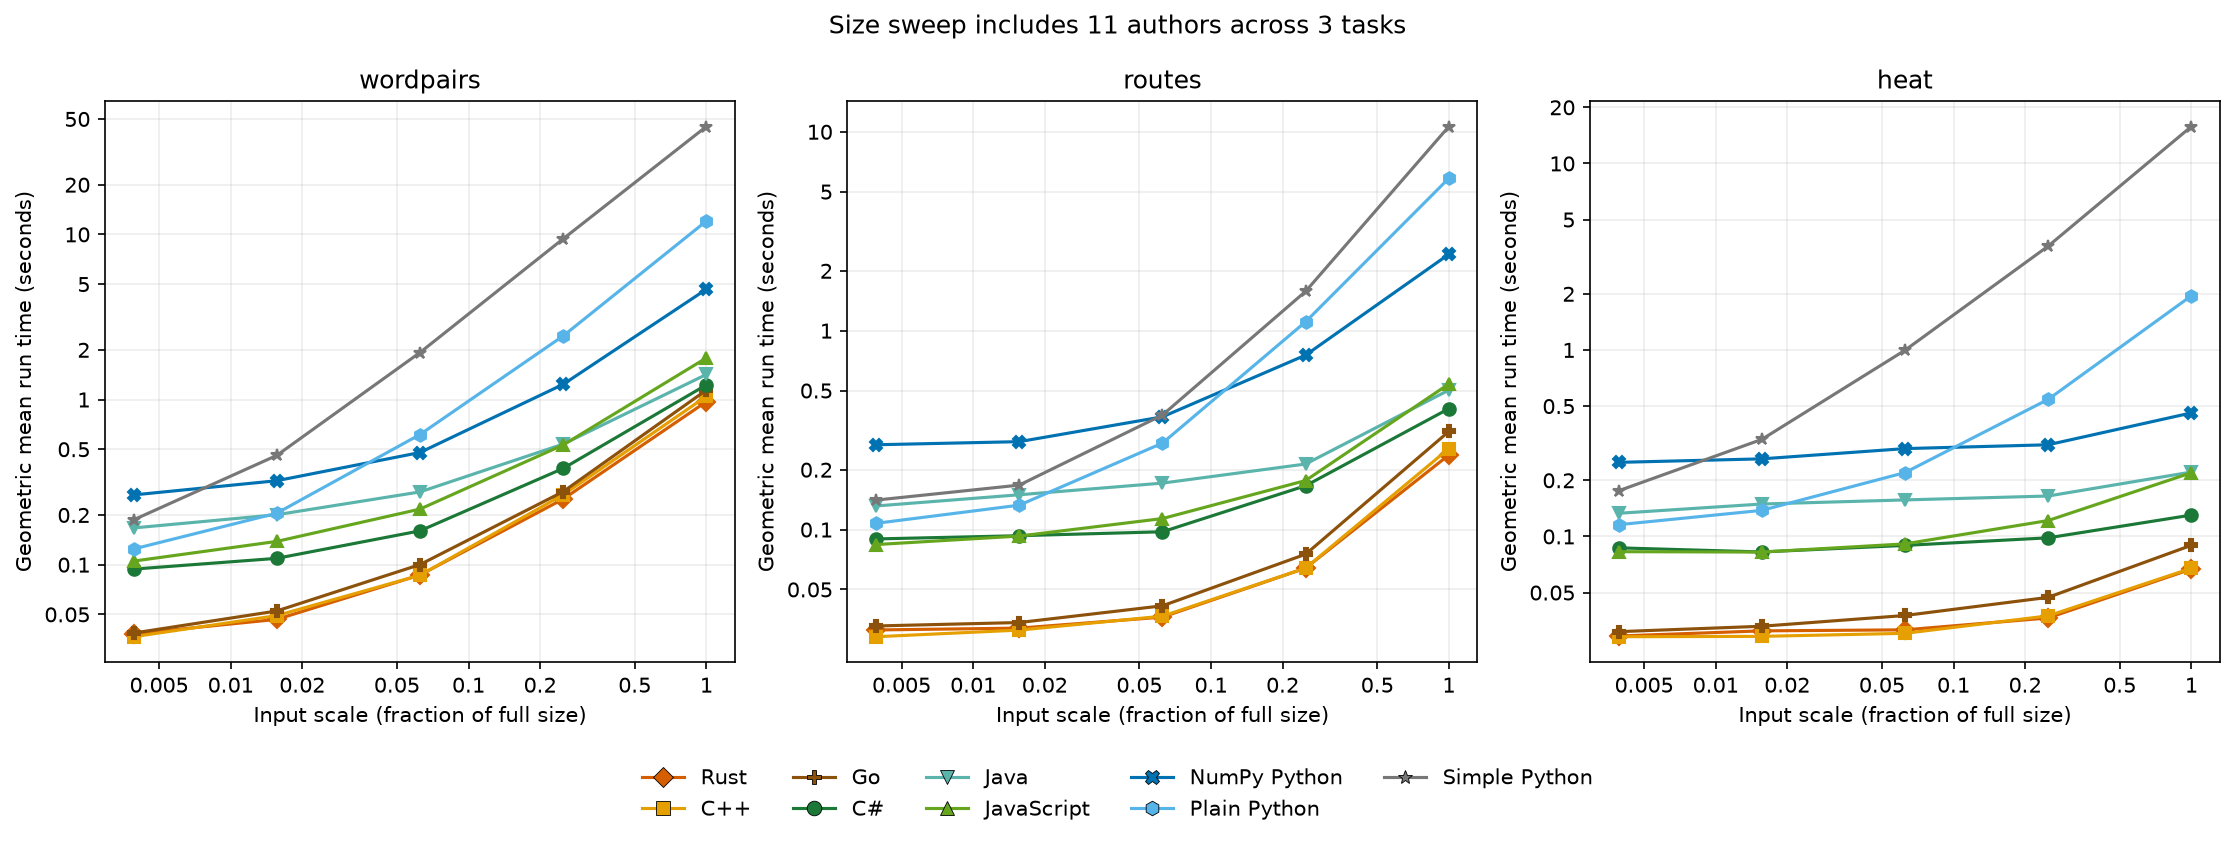

variant,rust,cpp,go,csharp,java,js,fast,plain,simple
task,,,,,,,,,
heat,0.31,0.38,0.47,0.19,0.18,0.45,0.23,0.91,1.1
routes,0.87,0.93,0.98,0.65,0.57,0.77,0.79,1.2,1.4
wordpairs,1.0,0.99,1.0,0.83,0.65,0.86,0.89,1.2,1.1


variant           rust  cpp  go  csharp  java  js  fast  plain  simple
task      scale                                                       
heat      0.0039     1 0.99 1.1     3.0   4.6 2.8   8.5    4.0     6.0
          0.016      1 0.93 1.1     2.6   4.8 2.6   8.4    4.4      11
          0.062      1 0.96 1.2     2.8   5.0 2.9   9.4    7.0      32
          0.25       1  1.0 1.3     2.7   4.5 3.3   8.5     15      99
          1          1  1.0 1.3     1.9   3.3 3.3   6.9     29     236
routes    0.0039     1 0.92 1.0     2.9   4.2 2.7   8.5    3.4     4.5
          0.016      1 0.98 1.1     2.9   4.7 2.9   8.7    4.2     5.2
          0.062      1  1.0 1.1     2.7   4.7 3.1    10    7.5      10
          0.25       1  1.0 1.2     2.6   3.3 2.8    12     17      25
          1          1  1.1 1.3     1.7   2.1 2.3    10     25      45
wordpairs 0.0039     1 0.96 1.0     2.5   4.4 2.8   6.9    3.3     4.9
          0.016      1  1.1 1.1     2.3   4.3 3.0   6.9    4.4     9.8
          0.062      1    1 1.2     1.9   3.2 2.5   5.5    7.1      22
          0.25       1  1.1 1.1     1.5   2.2 2.1   5.0    9.7      38
          1          1  1.1 1.2     1.3   1.5 1.8   4.8     12      46

In [27]:
# Compute and present this analysis step for the reader.
sw = pd.concat(
    [sweep, runs[runs.task.isin(["wordpairs", "routes", "heat"]) & runs.input.eq("full")]], ignore_index=True
)
sw = sw[sw.author.isin(AUTHORS + ["reference"]) & sw.status.eq("correct")].merge(ok, on=["author", "task", "variant"])
sw["scale"] = [entries.get((r.task, r.input), {}).get("scale", np.nan) for r in sw.itertuples()]
sm = sw.groupby(["task", "author", "variant", "scale"]).wall_seconds.median().reset_index()
smc = sm.groupby(["task", "variant", "scale"]).wall_seconds.agg(geom).reset_index(name="gm")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, t in zip(axes, ["wordpairs", "routes", "heat"]):
    for v in VERSIONS:
        d = smc[(smc.task == t) & (smc.variant == v)].sort_values("scale")
        ax.plot(d.scale, d.gm, marker=MARKERS[v], color=COLORS[v])
    if smc[smc.task.eq(t)].empty:
        ax.set_xlim(0.001, 1)
        ax.set_ylim(0.001, 1)
    ax.set(
        xscale="log",
        yscale="log",
        title=t,
        xlabel="Input scale (fraction of full size)",
        ylabel="Geometric mean run time (seconds)",
    )
    plain_log_axis(ax, "x")
    plain_log_axis(ax, "y")
fig.suptitle(f"Size sweep includes {sm.author.nunique()} authors across {sm.task.nunique()} tasks")
fig.legend(handles=version_handles(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=5, frameon=False)
fig.tight_layout()
savefig("size_sweep.png")
slopes = []
for (t, a, v), d in sm.groupby(["task", "author", "variant"]):
    d = d.sort_values("scale").tail(2)
    if len(d) == 2 and d.wall_seconds.min() > 0:
        slopes.append(
            dict(
                task=t,
                author=a,
                variant=v,
                slope=np.log(d.wall_seconds.iloc[1] / d.wall_seconds.iloc[0])
                / np.log(d.scale.iloc[1] / d.scale.iloc[0]),
            )
        )
sl = pd.DataFrame(slopes, columns=["task", "author", "variant", "slope"])
sl.to_csv(DERIVED / "sweep_slopes.csv", index=False)
display(sl.groupby(["task", "variant"]).slope.median().unstack("variant").reindex(columns=VERSIONS))
pv = smc.pivot_table(index=["task", "scale"], columns="variant", values="gm").reindex(columns=VERSIONS)
display(pv.div(pv["rust"], axis=0))


At 1/256 of the benchmark size every version finishes within a few tenths of a second and the order follows the
start-up costs: relative to Rust, C++ and Go took about the same time, C# 2.5 to 3.0 times, JavaScript 2.7 to 2.8,
plain Python 3.3 to 4.0, Java 4.2 to 4.6 and NumPy Python 6.9 to 8.5, across the three tasks. As inputs grow, the
virtual machines' start-up and warm-up are spread over more work and they close in (C# to 1.3 to 1.9 times Rust at
full size, Java to 1.5 to 3.3), while plain Python falls behind (to 12 to 29 times) and simple Python further (to 45
to 236 times). For a script that handles small files, start-up time can matter more than the language's speed.

## 18. More cores

The walkers task asks for the walks to be split over a given number of workers. Each program ran with 1, 2, 4, 8
and 16 workers, three timed runs each. The left panel shows median run time (log scale), the right panel each
version's speed-up over its own one-worker time (geometric mean of the ten session models), with the dotted diagonal as a
perfect speed-up and the vertical line at the laptop's six performance cores. The first table gives the geometric
means with CPU time divided by wall time (how many cores were busy on average); the second gives each model's
16-worker speed-up.

,variant,workers,time,speedup,cpu_wall
0,cpp,1,0.13,1,0.92
1,cpp,2,0.091,1.4,1.3
2,cpp,4,0.066,1.9,2.0
3,cpp,8,0.054,2.3,3.2
4,cpp,16,0.048,2.7,4.0
5,csharp,1,0.25,1,0.95
6,csharp,2,0.17,1.4,1.4
7,csharp,4,0.15,1.7,1.7
8,csharp,8,0.13,1.9,2.3
9,csharp,16,0.11,2.2,2.7


author,opus55,sonnet,haiku,sol61,terra,wonder-full,wonder,deepseek,glm,nemotron
variant,,,,,,,,,,
rust,3.4,3.1,3.2,2.2,4.4,1.0,6.8,5.1,5.6,5.5
cpp,1.8,1.7,3.5,2.7,4.3,1.9,3.6,3.8,1.7,3.1
go,1.4,2.6,2.1,2.1,5.4,1.8,2.4,2.4,2.9,4.7
csharp,2.0,2.5,1.3,1.5,3.2,1.7,2.6,3.2,1.8,2.9
java,0.88,0.48,0.88,0.89,1.4,0.84,0.87,0.81,0.91,1.1
js,1.8,2.1,1.8,1.5,2.4,2.2,2.5,4.4,2.7,2.6
fast,0.88,0.86,1.7,0.5,0.86,1.6,1.5,1.2,2.1,1.1
plain,3.4,6.9,7.0,3.7,6.0,4.1,6.0,4.2,5.3,6.2
simple,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


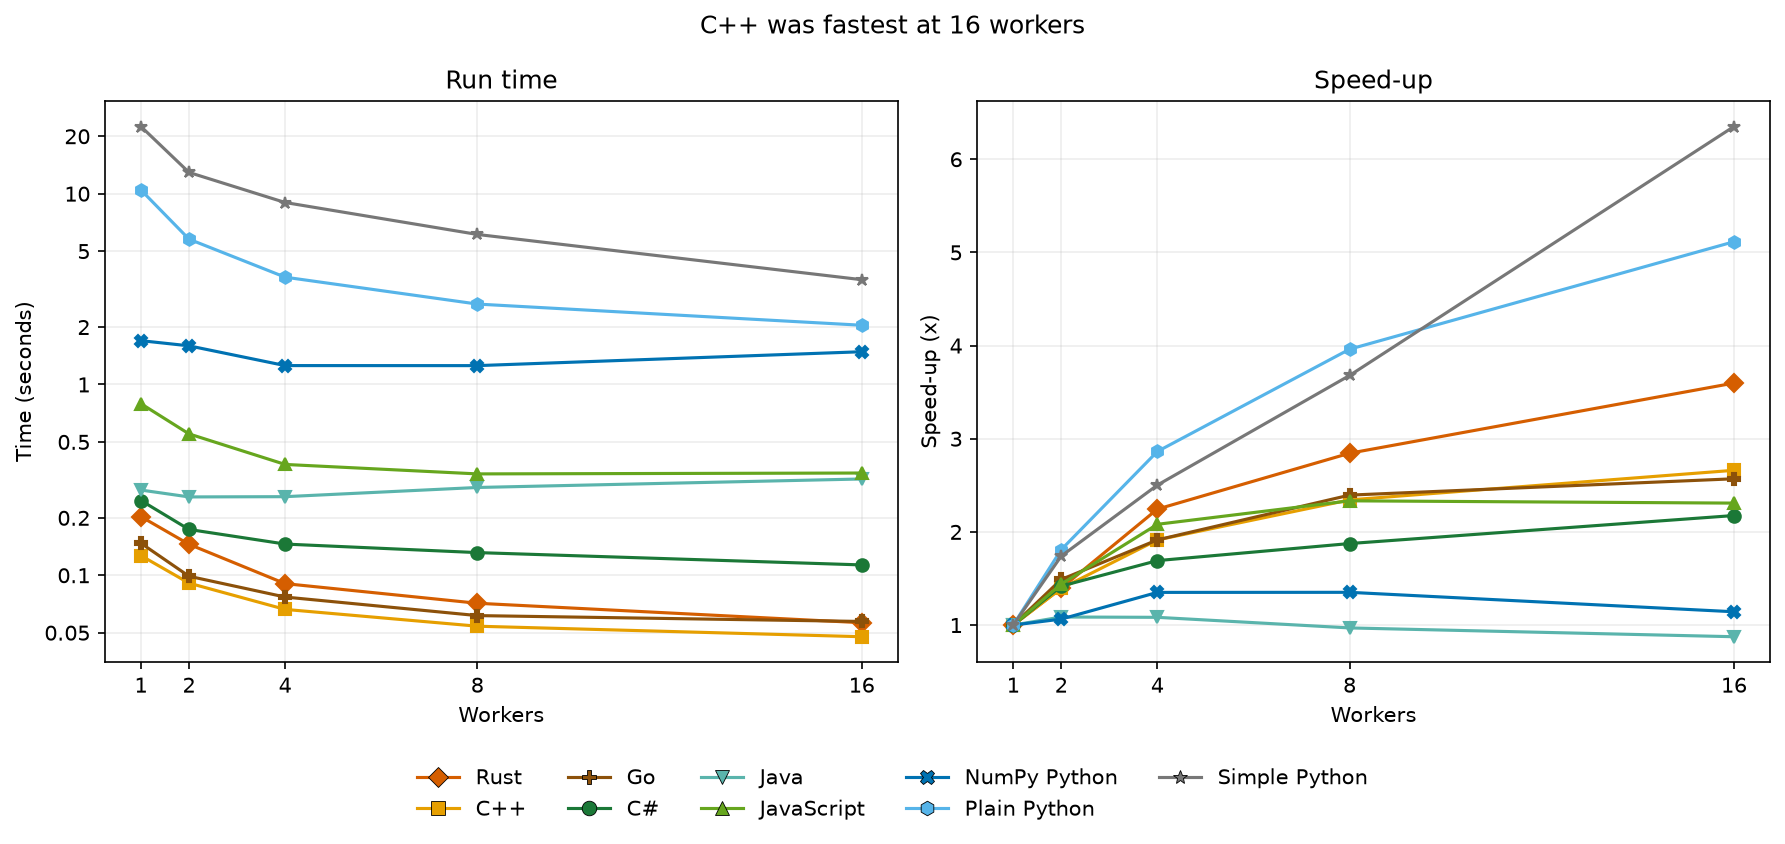

In [28]:
# Compute and present this analysis step for the reader.
sc = scaling[scaling.status.eq("correct") & scaling.author.isin(AUTHORS + ["reference"])].merge(ok, on=["author", "task", "variant"])
scm = (
    sc.groupby(["author", "variant", "workers"])
    .agg(time=("wall_seconds", "median"), cpu_wall=("cpu_wall_ratio", "median"))
    .reset_index()
)
one = scm[scm.workers.eq(1)].set_index(["author", "variant"]).time
scm["speedup"] = [one.get((r.author, r.variant), np.nan) / r.time for r in scm.itertuples()]
scm.to_csv(DERIVED / "scaling_by_author.csv", index=False)
scv = (
    scm.groupby(["variant", "workers"])
    .agg(time=("time", geom), speedup=("speedup", geom), cpu_wall=("cpu_wall", geom))
    .reset_index()
)
display(scv)
display(
    scm[scm.workers.eq(16)]
    .pivot(index="variant", columns="author", values="speedup")
    .reindex(index=VERSIONS, columns=AUTHORS)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for v in VERSIONS:
    d = scv[scv.variant.eq(v)].sort_values("workers")
    for ax, col in zip(axes, ["time", "speedup"]):
        ax.plot(d.workers, d[col], marker=MARKERS[v], color=COLORS[v])
if scv.empty:
    axes[0].set_ylim(0.1, 10)
axes[0].set(yscale="log", ylabel="Time (seconds)", title="Run time")
plain_log_axis(axes[0], "y")
axes[1].set(ylabel="Speed-up (x)", title="Speed-up")
for ax in axes:
    ax.set(xlabel="Workers", xticks=[1, 2, 4, 8, 16])
t16 = scv[scv.workers.eq(16)].dropna(subset=["time"])
fig.suptitle(
    f"{LABELS[t16.loc[t16.time.idxmin(), 'variant']]} was fastest at 16 workers"
    if len(t16)
    else "No 16-worker scaling measurements available"
)
fig.legend(handles=version_handles(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=5, frameon=False)
fig.tight_layout()
savefig("walkers_scaling.png")


Standard Python cannot run Python code on several cores within one process, so the models started one process per
worker, and plain Python ran 5.1 times faster with 16 workers than with one (geometric mean over models; 3.4 to 7.0
per model). The compiled and virtual-machine languages used threads and gained 2.2 to 3.6 times, less in relative
terms because their one-worker times were already close to their start-up floors. Java did not gain at all (0.28 s
with one worker, 0.32 s with sixteen), and NumPy barely (1.1 times). Even with 16 processes, plain Python (2.0 s)
stayed slower than every model's single-threaded C++, Rust and Go.

## 19. Code size and build time

The left panel shows the total source size over the eight tasks per version and model, in kilobytes; line counts
would mislead, because some models wrote several statements on one line (Terra's Go ledger is 33 lines). The right
panel shows each compiled program's clean build time (median of three builds), with the median per language marked.
JavaScript and Python have no build step. The tables give the sizes per model and version, and each model's median
build times from clean and after a one-line change.

variant,Rust,C++,Go,C#,Java,JavaScript,NumPy Python,Plain Python,Total
author,,,,,,,,,
Claude Opus 5.5,64,69,45,75,74,53,47,21,448
Claude Sonnet 5.5,43,43,31,50,50,41,30,17,304
Claude Haiku 5.5,48,56,39,61,60,46,47,16,372
GPT-6.1 Sol,42,43,32,58,54,47,36,26,337
GPT-6.1 Terra,21,16,14,16,18,16,15,12,128
Muse Wonder Full,64,58,42,63,62,47,39,28,404
Muse Wonder,64,55,36,56,58,40,32,22,362
DeepSeek V4.1 Flash,50,55,41,66,65,56,31,20,384
GLM 5.3 Flash,50,53,34,54,53,44,37,19,342


,author,variant,clean,incremental
0,deepseek,cpp,3.5,3.5
1,deepseek,csharp,4.5,2.9
2,deepseek,go,5.2,0.22
3,deepseek,java,1.2,1.2
4,deepseek,js,NaN,NaN
5,deepseek,rust,3.6,3.1
6,glm,cpp,3.4,3.4
7,glm,csharp,4.3,3.0
8,glm,go,4.6,0.21
9,glm,java,1.1,1.1


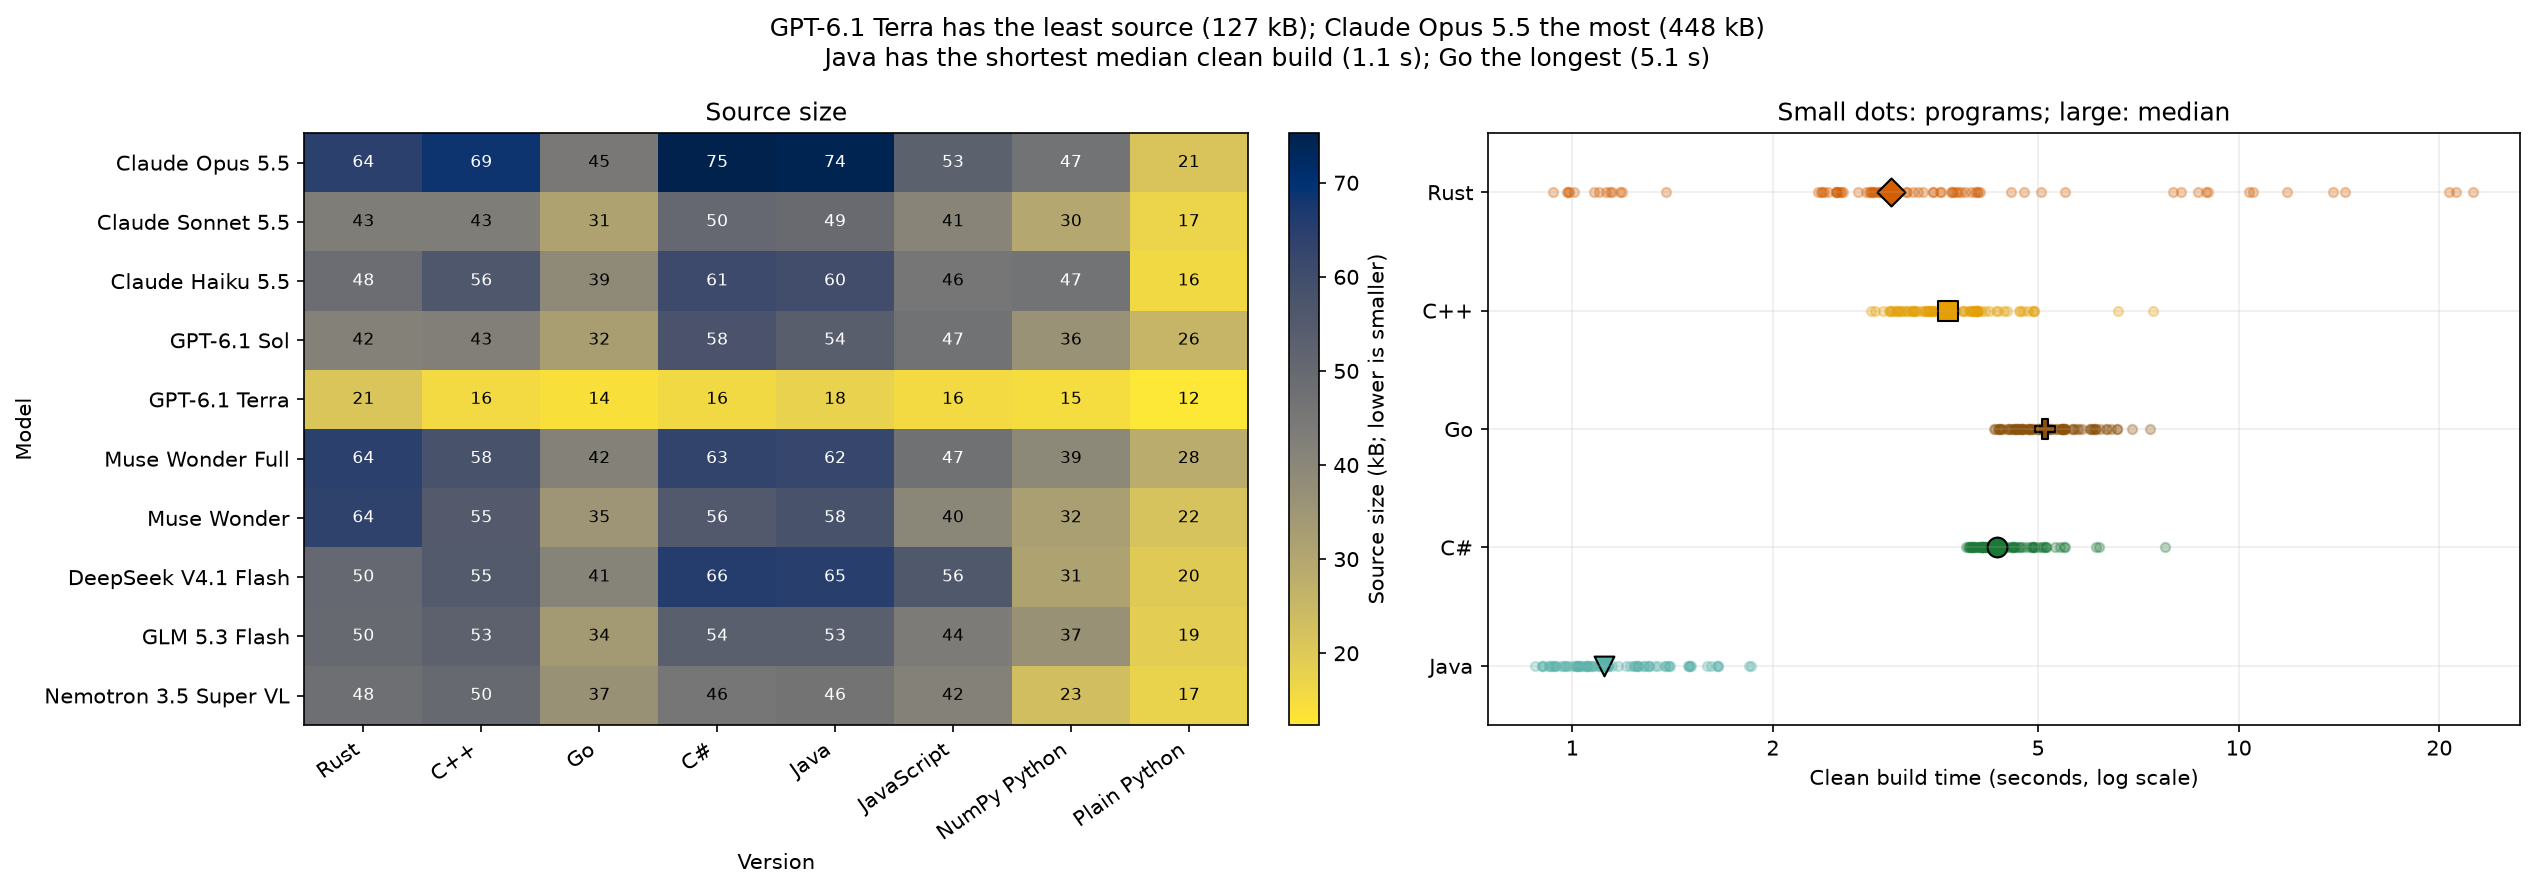

Total source size over the 64 programs of each author (decimal kB):


,source kB
Claude Opus 5.5,448
Claude Sonnet 5.5,304
Claude Haiku 5.5,373
GPT-6.1 Sol,337
GPT-6.1 Terra,127
Muse Wonder Full,404
Muse Wonder,362
DeepSeek V4.1 Flash,384
GLM 5.3 Flash,342
Nemotron 3.5 Super VL,309


Mean per author: ten agent-session models 339 kB, three one-reply authors 419 kB


In [29]:
# Compute and present this analysis step for the reader.
loc_main = (
    loc[loc.author.isin(AUTHORS)]
    .groupby(["author", "task", "variant"])
    .agg(code_lines=("code_lines", "sum"), bytes=("bytes", "sum"))
    .reset_index()
)
tot = loc_main.groupby(["author", "variant"])[["bytes", "code_lines"]].sum(min_count=1)
size_table = (tot.bytes / 1000).unstack("variant").reindex(index=AUTHORS, columns=MODEL_VERSIONS)
size_table["Total"] = size_table.sum(axis=1)
display(size_table.rename(index=MODEL_LABELS, columns=LABELS).round(1))


def clean_median(x):
    try:
        a = json.loads(x) if isinstance(x, str) else x
        return np.median(a) if isinstance(a, list) and a else np.nan
    except (ValueError, TypeError):
        return np.nan


build_main = builds[builds.author.isin(AUTHORS)].copy()
build_main["clean_median"] = build_main.clean_seconds.map(clean_median)
BUILT = ["rust", "cpp", "go", "csharp", "java"]
bt = (
    build_main.groupby(["author", "variant"])
    .agg(clean=("clean_median", "median"), incremental=("incremental_seconds", "median"))
    .reset_index()
)
display(bt)
grid = (tot.bytes / 1000).unstack("variant").reindex(index=AUTHORS, columns=MODEL_VERSIONS)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
heatmap(axes[0], grid, fmt=".1f", label="Source size (kB; lower is smaller)")
axes[0].set(title="Source size", xlabel="Version", ylabel="Model")
for i, v in enumerate(BUILT):
    x = build_main.loc[build_main.variant.eq(v), "clean_median"].dropna()
    x = x[x > 0]
    axes[1].scatter(x, [i] * len(x), color=COLORS[v], alpha=0.3, s=20)
    if len(x):
        axes[1].scatter([x.median()], [i], color=COLORS[v], edgecolor="black", s=90, marker=MARKERS[v])
axes[1].set(
    xscale="log",
    yticks=range(len(BUILT)),
    yticklabels=[LABELS[v] for v in BUILT],
    ylim=(len(BUILT) - 0.5, -0.5),
    xlabel="Clean build time (seconds, log scale)",
    title="Small dots: programs; large: median",
)
if build_main.clean_median.dropna().empty:
    axes[1].set_xlim(0.1, 10)
plain_log_axis(axes[1])
source_totals = loc_main.groupby("author").bytes.sum().dropna() / 1000
build_medians = build_main.groupby("variant").clean_median.median().dropna()
source_title = (
    f"{MODEL_LABELS[source_totals.idxmin()]} has the least source ({format_number(source_totals.min())} "
    f"kB); {MODEL_LABELS[source_totals.idxmax()]} the most ({format_number(source_totals.max())} kB)"
    if len(source_totals)
    else "No source totals available"
)
build_title = (
    f"{LABELS[build_medians.idxmin()]} has the shortest median clean build ({format_number(build_medians.min())} "
    f"s); {LABELS[build_medians.idxmax()]} the longest ({format_number(build_medians.max())} s)"
    if len(build_medians)
    else "No clean builds available"
)
fig.suptitle(source_title + "\n" + build_title)
fig.tight_layout()
savefig("code_and_build.png")
source_kb = (loc[loc.author.isin(ALL_AUTHORS)].groupby("author").bytes.sum().reindex(ALL_AUTHORS) / 1000).rename("source kB")
print("Total source size over the 64 programs of each author (decimal kB):")
display(with_separator(source_kb.rename(index=MODEL_LABELS).to_frame(), len(AUTHORS)))
print(f"Mean per author: ten agent-session models {source_kb[AUTHORS].mean():.0f} kB, three one-reply authors {source_kb[ONE_REPLY].mean():.0f} kB")


Terra wrote the least code, 127 kB over its 64 programs, and Opus the most of the session models, 448 kB; the other
eight wrote 304 to 404 kB. Much of the extra length is hand-written parsing and hash tables, which is also where much
of the speed came from, though length alone did not make code fast: Haiku (373 kB) and DeepSeek (384 kB) wrote more
than Sonnet (304 kB) for slower or equally fast programs. The one-reply programs were longer than the session
average (419 kB against 339 kB per author): Sol's 378 kB against 337 kB from its own sessions, Astra's 373 kB, and
Fable's 507 kB, the most of any author.

Building from clean took a median of about 1.1 s for Java, 3.0 s for Rust (up to 22 s when the JSON or pattern
libraries were compiled too), 3.7 s for C++, 4.3 s for C# and 5.1 s for Go, whose clean build recompiles its standard
library; a Go rebuild after a one-line change took 0.2 s.

## 20. Error analysis: slow choices, not wrong answers

No program gave a wrong answer, so this section looks at the next most useful thing: programs that were correct but
much slower than they needed to be, and why. The cases are the largest gaps between session models in the same
language for the same task (5 to 22 times; the first table of section 21 ranks every task and version), one case
where NumPy made a program slower, and the largest gaps between Sol's session and one-reply programs. Each
explanation comes from reading the programs; where a cause was not tested separately, the text says so.

**Plain-Python heat: six models packed the grid, four looped over cells.** Opus, Sonnet, Haiku, both Muse models and
DeepSeek packed the floor plan into one large integer and moved every cell with a few shifts per step, as in the
worked example; their plain Python took 0.47 to 1.05 s. Sol, Terra, GLM and Nemotron kept the grid as lists and
computed each of the 160,000 cells in Python for each of 250 steps: 6.3, 6.8, 9.8 and 6.1 s. GLM's step loop:

In [30]:
show_code('glm', 'heat', 'plain', 72, 93)

  72      for _ in range(s):
  73          new_rows = rows[:]  # share unchanged rows, copy only updated ones
  74          for r in range(1, h + 1):
  75              seg_r = segs[r]
  76              spec_r = spec[r]
  77              if not seg_r and not spec_r:
  78                  continue
  79              row = rows[r]
  80              up = rows[r - 1]
  81              dn = rows[r + 1]
  82              nrow = row[:]
  83              new_rows[r] = nrow
  84              for a, b in seg_r:
  85                  nrow[a:b] = [
  86                      (4 * v + u + d + l + rr) >> 3
  87                      for v, u, d, l, rr in zip(
  88                          row[a:b], up[a:b], dn[a:b], row[a - 1 : b - 1], row[a + 1 : b + 1]
  89                      )
  90                  ]
  91              for c, mm in spec_r:
  92                  nrow[c] = (mm * row[c] + row[c - 1] + row[c + 1] + up[c] + dn[c]) >> 3
  93          rows = new_rows


This is the program most people would write, and it is correct. The packed versions use a trick that pays only in
Python, where one operation on a huge integer runs in compiled code. Sol's one-reply program packed the grid in
24-bit lanes and took 1.00 s, the largest gain of one reply over a session in the study, and Sol's pilot session had
packed it too (0.95 s, section 13).

**Ledger: a general JSON library against a scanner written for the format.** Terra's C++ ledger took 11.4 s, its Go
7.2 s and its JavaScript 10.1 s, against 0.74 to 1.10 s, 0.72 to 1.97 s and 1.19 to 2.23 s for the other session
models in those languages (Nemotron's and Sol's JavaScript aside). Terra's C++ builds a full nlohmann/json object
tree for each of the million lines:

In [31]:
show_code('terra', 'ledger', 'cpp', 13, 24)

  13      ios::sync_with_stdio(false); cin.tie(nullptr);
  14      ifstream f(argv[1], ios::binary); string line;
  15      getline(f, line); auto first = json::parse(line);
  16      unordered_map<string,int64_t> rates;
  17      for (auto it=first["rates"].begin(); it!=first["rates"].end(); ++it) rates.emplace(it.key(), it.value().get<int64_t>());
  18      unordered_map<string,int64_t> accounts; unordered_map<string,Stat> channels;
  19      int64_t count=0, net=0;
  20      while (getline(f,line)) {
  21          auto j=json::parse(line);
  22          auto &type=j["type"].get_ref<const string&>();
  23          if(type=="void") continue;
  24          bool skip=false; for(auto &tag:j["tags"]) if(tag=="test") {skip=true; break;}


The Go version decodes each line into a map of raw fields and then decodes each field again with Go's
reflection-based `encoding/json`:

In [32]:
show_code('terra', 'ledger', 'go', 16, 24)

  16   r:=bufio.NewReaderSize(f,1<<20); line,err:=r.ReadBytes('\n'); if err!=nil {panic(err)}
  17   var first map[string]json.RawMessage; if err=json.Unmarshal(line,&first); err!=nil {panic(err)}; rates:=make(map[string]int64); if err=json.Unmarshal(first["rates"],&rates); err!=nil {panic(err)}
  18   accounts:=make(map[string]int64); channels:=make(map[string]*stat); var count,net int64
  19   for { line,err=r.ReadBytes('\n'); if err==io.EOF && len(line)==0 {break}; if err!=nil && err!=io.EOF {panic(err)}
  20    var fields map[string]json.RawMessage; if e:=json.Unmarshal(line,&fields); e!=nil {panic(e)}
  21    var t transaction
  22    for _, field:=range []struct{key string; dest any}{{"account",&t.Account},{"type",&t.Type},{"amount",&t.Amount},{"currency",&t.Currency},{"tags",&t.Tags}} {if e:=json.Unmarshal(fields[field.key],field.dest); e!=nil {panic(e)}}
  23    var meta map[string]json.RawMessage; if e:=json.Unmarshal(fields["meta"],&meta); e!=nil {panic(e)}; if e:=json.Unmars

Terra's JavaScript calls `JSON.parse` per line and does every amount in `BigInt` arithmetic, and so does Nemotron's
(8.4 s). Sol's JavaScript (3.7 s) scans each line itself but also does its amounts in `BigInt`. The other seven
session models wrote small byte-level scanners in each language that read only the fields the task needs. This one
choice accounts for most of the model share on ledger in section 12.

**NumPy that made parsing slower.** Haiku's NumPy ledger took 24.4 s and its NumPy logscan 14.1 s, three times its
own plain Python (7.8 and 4.6 s). Its NumPy ledger is a 310-line attempt to find JSON fields with whole-array
operations over the raw bytes, with a fallback to the `json` module for awkward lines; its plain version is 52 lines
around `json.loads`. NumPy cannot express the per-line decisions of parsing, and the attempt cost more than it saved.
Across all 13 authors the fastest NumPy ledger (6.7 s) was slower than the fastest plain one (6.5 s).

**Walkers in Rust: the same generator, eight times apart.** Muse Wonder Full's Rust took 0.044 s and Muse Wonder's
0.376 s. Both run the task's SplitMix64 random number generator, two multiplications per step that must happen in
order. Wonder stepped one walker at a time and chose the direction with a four-way `match`:

In [33]:
show_code('wonder', 'walkers', 'rust', 63, 82)

  63          while i < l {
  64              i += 1;
  65              state = state.wrapping_add(0x9E3779B97F4A7C15u64);
  66              let mut z = state;
  67              z = (z ^ (z >> 30)).wrapping_mul(0xBF58476D1CE4E5B9u64);
  68              z = (z ^ (z >> 27)).wrapping_mul(0x94D049BB133111EB_u64);
  69              // Top two bits of (z ^ (z >> 31)) equal top two bits of z.
  70              match z >> 62 {
  71                  0 => {
  72                      if x == bi {
  73                          bumps += 1;
  74                      } else {
  75                          x += 1;
  76                          if x == 0 && y == 0 { returns += 1; }
  77                      }
  78                  }
  79                  1 => {
  80                      if x == nb {
  81                          bumps += 1;
  82                      } else {


Each step branches on two random bits, which the processor cannot predict. Wonder Full wrote the step without
branches and ran it for four walkers in one loop (its `run4` function repeats this step four times per iteration),
so the processor could work on four independent chains of multiplications at once:

In [34]:
show_code('wonder-full', 'walkers', 'rust', 49, 75)

  49  // One step for one walker. Coordinates are offset by +B, so they lie in
  50  // [0, 2B]; the origin is (B, B). Branchless: the direction is random, so
  51  // real branches on it would mispredict constantly. Only the top two bits
  52  // of the SplitMix64 output are needed, and the final `z ^ (z >> 31)`
  53  // cannot change those bits, so it is omitted.
  54  macro_rules! step {
  55      ($state:ident, $x:ident, $y:ident, $bumps:ident, $rets:ident, $b:ident, $a:ident) => {{
  56          $state = $state.wrapping_add(GOLD);
  57          let mut z = $state;
  58          z = (z ^ (z >> 30)).wrapping_mul(C1);
  59          z = (z ^ (z >> 27)).wrapping_mul(C2);
  60          let d = (z >> 62) as i64; // 0..3
  61          let sign = 1 - ((d & 1) << 1); // +1 for d in {0,2}, -1 for {1,3}
  62          let is_y = d >> 1; // 0 = x move, 1 = y move
  63          let nx = $x + sign * (1 - is_y);
  64          let ny = $y + sign * is_y;
  65          // As unsigned, a negative valu

Four other models' Rust took 0.33 to 0.35 s, like Wonder's. Which of Wonder Full's two changes did more was not
measured.

**Walkers in NumPy: a wrong belief in a comment.** Nemotron's NumPy walkers took 16.7 s, against 0.78 s for Opus's.
Its docstring and loop:

In [35]:
show_code('nemotron', 'walkers', 'fast', 1, 13)
print()
show_code('nemotron', 'walkers', 'fast', 37, 53)

   1  """Random walkers simulation, Python 3.13 + NumPy 2.2.
   2  
   3  All J walkers are evolved in lockstep: their generator states, positions and
   4  counters are NumPy arrays, so one Python iteration advances every walker by one
   5  step. SplitMix64 arithmetic on uint64 arrays wraps modulo 2^64 automatically.
   6  Walkers are independent, so the result does not depend on WORKERS (which is
   7  accepted for interface compatibility).
   8  
   9  Notes on speed: NumPy's per-call overhead dominates for small walker counts
  10  because the per-step random-number stream is inherently sequential per walker,
  11  so this version runs in a single process and keeps the per-step call count
  12  small.
  13  """

  37      for _ in range(l):
  38          states += C
  39          z = states ^ (states >> 30)
  40          z = z * M1
  41          z = z ^ (z >> 27)
  42          z = z * M2
  43          d = (z ^ (z >> 31)) >> 62
  44  
  45          nx = x + np.take(DX, d)
  46     

The loop runs 500,000 times over arrays of only 64 numbers, so it pays NumPy's per-call cost for about 30 array operations per step.
The docstring says the random stream "is inherently sequential per walker". It is not: SplitMix64's state after k
steps is the seed plus k times a constant, so all of a walker's random numbers can be computed at once, which is what
Opus's version did before resolving the walk in blocks.

**Walkers in plain Python: 2.9 s against 18 to 24 s.** Opus's plain Python made 4,096 random numbers at a time by
packing their states into one large integer, and while a walker was far from every wall and from the origin, it
skipped the step-by-step walk and only counted how many of the next steps went each way. Five models wrote the direct
loop and took 17.6 to 24.1 s, about the simple reference's 22.8 s.

**Terra's other slow choices.** On wordpairs, Terra's C++ (4.3 s) kept counts in the standard `std::unordered_map`,
which Microsoft's library builds from linked nodes, while the other nine wrote their own flat tables (0.44 to 1.9 s;
why those differ among themselves was not tested). On logscan, Terra's Go checked every line against one long
regular expression and took 3.7 s; the other nine checked the format by hand and took 0.37 to 0.57 s. This is
the opening's log-summary example, measured: the same answer, ten times apart. On align,
Terra's C++ took 0.58 s against 0.046 to 0.12 s, with the same recurrence as its own 0.12 s Rust; the cause was not
found.

**Routes in NumPy: a session that profiled, a reply that guessed.** Sol's one-reply NumPy routes took 5.25 s against
1.18 s for its session program, the largest gap between Sol's two methods. The one-reply program used NumPy only to
read the file and build the road network. It then searched the network with a bucket queue in a plain Python loop
over nodes and roads, so it ran at the speed of Sol's one-reply plain Python (4.10 s). Its inner loop:

In [36]:
show_code('sol61-oneshot', 'routes', 'fast', 28, 46)

  28          current = buckets[index]
  29  
  30          for u in current:
  31              if distances[u] != distance:
  32                  continue
  33  
  34              farthest = distance
  35              for edge in graph[u]:
  36                  v = edge >> 10
  37                  candidate = distance + (edge & 1023)
  38                  if candidate < distances[v]:
  39                      distances[v] = candidate
  40                      slot = candidate & 1023
  41                      bucket = buckets[slot]
  42                      if not bucket:
  43                          active |= bits[slot]
  44                      bucket.append(v)
  45  
  46          current.clear()


Every road out of every reached node passes through these Python lines, once per starting point. The session
program kept the same bucket idea but expanded whole frontiers of nodes at once with array operations, and fell back
to a Python loop only when a frontier was narrow. Its wide-frontier step gathers all the roads leaving the frontier,
computes their new distances and keeps the smallest per node, all inside NumPy:

In [37]:
show_code('sol61', 'routes', 'fast', 134, 148)

 134          # Expand variable-length CSR rows entirely in native NumPy loops.
 135          positions = np.arange(ends[-1], dtype=np.int64)
 136          positions += np.repeat(starts - (ends - counts), counts)
 137          packed = edges[positions]
 138          targets = packed >> 10
 139          candidates = np.repeat(labels, counts) + (packed & 1023)
 140          improve = candidates < distances[targets]
 141          targets = targets[improve]
 142          candidates = candidates[improve]
 143          if not targets.size:
 144              continue
 145          # Repeated endpoints must reduce by minimum, never overwrite in
 146          # advanced-index assignment order (parallel roads are legal).
 147          np.minimum.at(distances, targets, candidates)
 148          valid = candidates == distances[targets]


The session log shows how it got there: Sol generated a benchmark-sized road network, ran Python's profiler on its
graph reader, timed the reading and the search separately and kept rewriting until the search was the smaller part.
The one-reply call had the same instruction to be fast, but no way to see that its search loop dominated.

**Wordpairs in Go: counting with a hash table or by sorting.** Sol's one-reply Go took 2.88 s, its session Go 0.83 s.
Both give each word a number with a Go map. The one-reply program then counts each pair of word numbers in an
open-addressing hash table it wrote itself:

In [38]:
show_code('sol61-oneshot', 'wordpairs', 'go', 50, 72)

  50  func (t *pairTable) add(key uint64) {
  51  	mask := len(t.entries) - 1
  52  	i := int(pairHash(key)) & mask
  53  
  54  	for {
  55  		e := &t.entries[i]
  56  		if e.key == key {
  57  			e.count++
  58  			return
  59  		}
  60  		if e.key == 0 {
  61  			if t.used >= t.limit {
  62  				t.grow()
  63  				t.add(key)
  64  				return
  65  			}
  66  			e.key = key
  67  			e.count = 1
  68  			t.used++
  69  			return
  70  		}
  71  		i = (i + 1) & mask
  72  	}


With about 4 million distinct pairs, the table grows far larger than the processor's caches, so most of the 10
million lookups wait for main memory. The session program does not look pairs up at all while reading: it appends
every pair to a list, sorts the list with a radix sort and counts runs of equal pairs, which reads memory in order:

In [39]:
show_code('sol61', 'wordpairs', 'go', 82, 92)

  82  func scanPairs[T ~uint32 | ~uint64](keys []T, bits uint, mask uint64, rank []int) ([]entry, uint64) {
  83  	keys = radixSort(keys)
  84  	top := make([]entry, 0, 20)
  85  	var distinct uint64
  86  	for i := 0; i < len(keys); {
  87  		start, key := i, keys[i]
  88  		i++
  89  		for i < len(keys) && keys[i] == key {
  90  			i++
  91  		}
  92  		distinct++


The session wrote a benchmark script and timed its versions, which is how it would have found the sorting approach;
the log does not show which alternatives it tried. Astra's one-reply Go (2.79 s) and both OpenAI models' one-reply
C#, Java and JavaScript were similarly slow on wordpairs, 2.1 to 2.7 times Sol's session programs. Whether the hash
table is the whole cause was not measured.

Together these cases are the model share of section 12: on the text and table tasks one parsing or table choice
moved a model's programs in every language at once, while on the arithmetic tasks the models' choices differed less
than the languages did. The Sol cases show both directions for the one-reply comparison: a session that timed its
work found faster plans for routes and wordpairs, and a session still missed the packed grid that one reply, and an
earlier session of the same model, found.

## 21. Measurement quality

The laptop was running other work during the timing. The first table ranks the task-and-version cells by how far
apart the fastest and slowest of the ten session models' programs were; the error analysis took its cases from the top of
it. The next cell prints the coefficient of variation of each program's five repeats (standard deviation divided by
mean) by version, the programs with the largest variation, how many cores the rest of the machine kept busy during
each run (`other_busy_cores`: busy CPU time on the whole machine minus the program's own, divided by its wall time),
how often a single-worker run used more than 1.2 cores on average, and the rows set aside by the setup cell.

In [40]:
spread=median[median.author.isin(AUTHORS)&median.variant.isin(MODEL_VERSIONS)].groupby(['task','variant']).filter(lambda g:len(g)>=2)
choices=[]
for (t,v),g in spread.groupby(['task','variant']):
    lo=g.loc[g['median'].idxmin()]; hi=g.loc[g['median'].idxmax()]
    if lo['median']>0: choices.append(dict(task=t,version=v,fastest=lo.author,slowest=hi.author,ratio=hi['median']/lo['median']))
display(pd.DataFrame(choices,columns=['task','version','fastest','slowest','ratio']).sort_values('ratio',ascending=False).head(20))
def compare_cell(task,version):
    sizes=loc_main[(loc_main.task==task)&(loc_main.variant==version)].set_index('author')['bytes']
    times=median[(median.task==task)&(median.variant==version)].set_index('author')['median']
    display(pd.DataFrame({'source_bytes':sizes,'median_seconds':times}).reindex(AUTHORS))


,task,version,fastest,slowest,ratio
50,walkers,fast,opus55,nemotron,22
14,heat,plain,opus55,glm,21
16,ledger,cpp,opus55,terra,15
0,align,cpp,opus55,terra,13
34,routes,fast,sol61,terra,10.0
27,logscan,go,opus55,terra,10.0
19,ledger,go,sonnet,terra,9.9
56,wordpairs,cpp,opus55,terra,9.8
55,walkers,rust,wonder-full,wonder,8.5
21,ledger,js,sonnet,terra,8.5


In [41]:
quality_tables = {'correctness': correctness, 'runs': runs, 'sweep': sweep, 'scaling': scaling, 'baseline': baseline}
cv = full.groupby(['task','author','variant']).wall_seconds.agg(['mean','std','count']); cv['CV'] = cv['std']/cv['mean']
display(cv.reset_index().groupby('variant').CV.agg(median='median', max='max').reindex(VERSIONS).rename(index=LABELS).round(3))
display(cv.sort_values('CV', ascending=False).head(10).round(4))
display(pd.DataFrame({name: {'median': d.other_busy_cores.median(), 'max': d.other_busy_cores.max()} for name,d in quality_tables.items()}).T.round(3))
for name, d in quality_tables.items():
    print(name, 'rows with other_busy_cores > 2:', int((d.other_busy_cores > 2).sum()), 'of', len(d))
# CPU time / wall time above 1.2 for single-worker runs is expected for runtimes with background threads (garbage collection, JIT compiler).
single = pd.concat([d.assign(table=name) for name, d in quality_tables.items() if name != 'baseline' for d in [d[d.get('workers', pd.Series(1, index=d.index)) == 1]]])
single['version'] = single.variant
per_runtime = single.groupby('version').agg(rows=('cpu_wall_ratio', 'size'), above_1_2=('cpu_wall_ratio', lambda x: int((x > 1.2).sum())), median_cpu_wall=('cpu_wall_ratio', 'median'), max_cpu_wall=('cpu_wall_ratio', 'max'))
per_runtime['share_above_1_2'] = per_runtime.above_1_2 / per_runtime.rows
display(per_runtime.reindex(VERSIONS).dropna(how='all').rename(index=LABELS).round(3))
aot = single[single.version.isin(['rust', 'cpp', 'go']) & (single.cpu_wall_ratio > 1.2)]
print('ahead-of-time compiled (Rust, C++, Go), single worker, CPU/wall > 1.2:', len(aot))
print(aot.groupby(['version', 'task', 'author']).cpu_wall_ratio.agg(['size', 'max']).round(2).to_string() if len(aot) else 'none')
display(pd.DataFrame(exclusions).groupby(['table','reason']).size().rename('excluded rows') if exclusions else 'No rows were excluded by the freshness filter.')
periods=[]
for name,d in {'runs':runs,'sweep':sweep,'scaling':scaling,'baseline':baseline}.items():
    d=d.copy(); d['task']=d.task.fillna('baseline')
    for task,g in d.groupby('task'):
        periods.append(dict(table=name,task=task,first_started_utc=g.started_utc.min(),last_started_utc=g.started_utc.max(),rows=len(g),median_other_busy_cores=g.other_busy_cores.median()))
display(pd.DataFrame(periods,columns=['table','task','first_started_utc','last_started_utc','rows','median_other_busy_cores']))

exclusion_table = pd.DataFrame(exclusions)
if not exclusion_table.empty:
    exclusion_table.to_csv(DERIVED / "exclusions.csv", index=False)
    print("Exclusions by reason:", exclusion_table.reason.value_counts().to_dict())


,median,max
variant,,
Rust,0.098,0.46
C++,0.12,0.34
Go,0.11,0.5
C#,0.091,0.29
Java,0.1,0.39
JavaScript,0.1,0.66
NumPy Python,0.1,0.29
Plain Python,0.07,0.21
Simple Python,0.086,0.19


,,,mean,std,count,CV
task,author,variant,,,,
ledger,fable-oneshot,js,1.3,0.87,5,0.66
wordpairs,sonnet,js,1.9,0.98,5,0.53
springs,astra-oneshot,go,0.27,0.13,5,0.5
ledger,wonder-full,js,2.2,1.1,5,0.49
springs,sol61-oneshot,go,0.3,0.14,5,0.46
align,wonder,rust,0.11,0.048,5,0.46
heat,terra,rust,0.19,0.084,5,0.44
walkers,astra-oneshot,java,0.33,0.13,5,0.39
springs,sonnet,js,0.35,0.12,5,0.35


,median,max
correctness,11,30
runs,8.8,24
sweep,8.5,26
scaling,9.1,22
baseline,12,24


correctness rows with other_busy_cores > 2: 4755 of 4755
runs rows with other_busy_cores > 2: 4230 of 4230
sweep rows with other_busy_cores > 2: 3852 of 3852
scaling rows with other_busy_cores > 2: 1575 of 1575
baseline rows with other_busy_cores > 2: 160 of 160


,rows,above_1_2,median_cpu_wall,max_cpu_wall,share_above_1_2
version,,,,,
Rust,1565,48,0.86,6.4,0.031
C++,1521,53,0.86,2.0,0.035
Go,1521,60,0.89,2.8,0.039
C#,1521,45,0.93,1.6,0.03
Java,1521,808,1.2,2.8,0.53
JavaScript,1521,250,1.0,2.0,0.16
NumPy Python,1565,0,0.93,1.2,0
Plain Python,1565,4,0.96,1.3,0.003
Simple Python,117,0,0.96,1.1,0


ahead-of-time compiled (Rust, C++, Go), single worker, CPU/wall > 1.2: 161
                                 size  max
version task      author                  
cpp     align     fable-oneshot     1  1.4
                  haiku             1  1.4
                  opus55            1  1.2
                  sol61-oneshot     1  1.3
                  terra             1  1.2
                  wonder            1  1.2
        heat      astra-oneshot     1  1.2
                  deepseek          2  1.9
                  fable-oneshot     1  1.6
                  glm               1  1.2
                  haiku             2  2.0
                  nemotron          2  1.5
                  sol61             1  1.9
                  sol61-oneshot     1  1.5
                  terra             1  1.6
                  wonder            2  1.4
                  wonder-full       1  1.6
        ledger    astra-oneshot     1  1.3
                  haiku             2  1.3
        logscan   sol6

table        reason                   
builds       program missing               22
correctness  source hash mismatch         697
             superseded by a later run    824
loc          older version of the file    143
             program missing                1
Name: excluded rows, dtype: int64

,table,task,first_started_utc,last_started_utc,rows,median_other_busy_cores
0,runs,align,2026-11-08T09:03:47.418119+00:00,2026-11-12T16:25:55.289430+00:00,525,8.7
1,runs,heat,2026-11-08T09:15:47.453704+00:00,2026-11-12T16:27:34.813370+00:00,555,8.8
2,runs,ledger,2026-11-08T08:07:30.203896+00:00,2026-11-12T16:14:27.459609+00:00,525,8.8
3,runs,logscan,2026-11-08T08:35:12.265206+00:00,2026-11-12T16:19:20.811221+00:00,525,9.3
4,runs,routes,2026-11-08T08:50:38.018758+00:00,2026-11-12T16:23:20.079830+00:00,525,8.4
5,runs,springs,2026-11-08T07:19:52.095705+00:00,2026-11-12T15:57:18.641569+00:00,525,9.1
6,runs,walkers,2026-11-08T09:24:57.505634+00:00,2026-11-12T16:31:47.548913+00:00,525,8.6
7,runs,wordpairs,2026-11-08T07:37:32.055010+00:00,2026-11-12T16:05:41.339640+00:00,525,8.9
8,sweep,heat,2026-11-08T09:56:35.426458+00:00,2026-11-12T16:47:21.515165+00:00,1332,8.8
9,sweep,routes,2026-11-08T09:51:45.752247+00:00,2026-11-12T16:45:40.153501+00:00,1260,8.6


Exclusions by reason: {'superseded by a later run': 824, 'source hash mismatch': 697, 'older version of the file': 143, 'program missing': 23}


The median coefficient of variation over the five repeats was 7 to 12% per version (8.6% for simple Python); the
largest was 66%, Fable's one-reply ledger JavaScript (mean 1.3 s). Other programs kept a median of 9.7 of the 22
logical processors busy during the first day's timed runs and 6.4 during the second day's, more than in the earlier
two-model timing (4.4), and more than 2 in every run, so the outside load was a constant background rather than an
occasional spike. The largest consumer seen on the machine after the first day was OneDrive's file
synchronisation, at about 4.5 cores. Within a day the load affected all versions alike, because the programs took
turns in a shuffled order, but it widens the noise for any single program, and it differed between the days (next
figure).

A single-worker run used more than 1.2 cores on average in 53% of Java runs and 16% of JavaScript runs, from their
garbage collectors and compilers working on other threads, and rarely in the compiled languages (161 of about 4,600
runs). Ratios above about 1.5 between two programs are well beyond this noise; smaller differences between two single
programs are not reliable. The model index and the language-and-model split average over dozens of programs, which
reduces the effect of this noise.

The setup cell set aside 697 correctness rows for programs whose source has since changed, 824 correctness rows
replaced by a later run of the same program and input, 143 code-size rows for older versions of a file, and 23 rows
for programs that do not exist (build records for Rust versions the reference and the two pilot models never had, and
one source file that a later session removed). No timed run was set aside.

The last figure is the drift check of section 1: one point per Opus 5.5 program, its time on 2026-11-12 divided by its
time on 2026-11-08, one row per version, with a dashed line at no change and a solid line at the geometric mean.

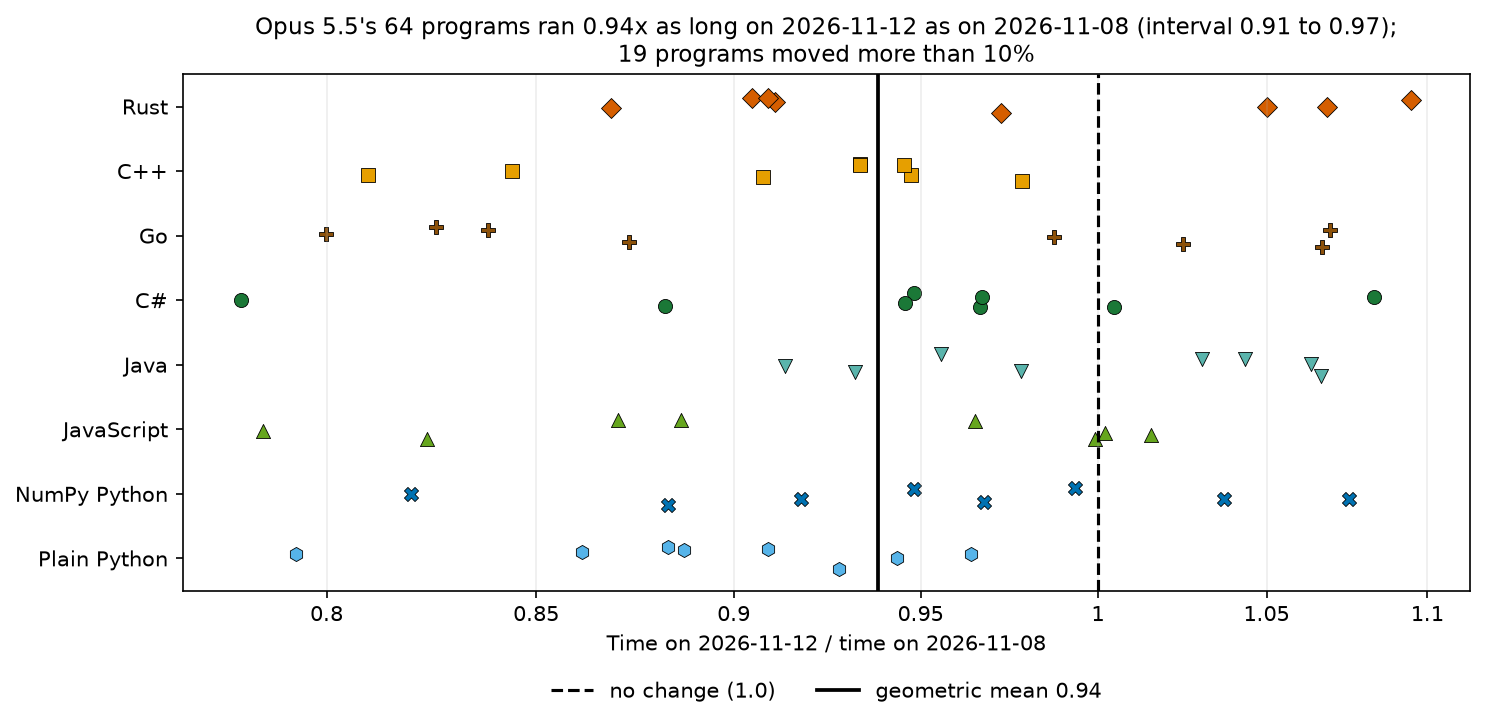

In [42]:
# Strip plot of the 64 Opus 5.5 ratios (time on 2026-11-12 / time on 2026-11-08), one row per version.
fig, ax = plt.subplots(figsize=(10, 5))
jitter = np.random.default_rng(39)
for i, v in enumerate(MODEL_VERSIONS):
    x = drift.loc[drift.variant.eq(v), "ratio"]
    ax.scatter(x, i + jitter.uniform(-0.18, 0.18, len(x)), color=COLORS[v], marker=MARKERS[v], s=46, edgecolor="black", linewidth=0.4)
ax.axvline(1.0, color="black", ls="--", label="no change (1.0)")
ax.axvline(DRIFT, color="black", lw=1.8, label=f"geometric mean {DRIFT:.2f}")
ax.set(xscale="log", yticks=range(len(MODEL_VERSIONS)), yticklabels=[LABELS[v] for v in MODEL_VERSIONS], ylim=(len(MODEL_VERSIONS) - 0.5, -0.5),
       xlabel="Time on 2026-11-12 / time on 2026-11-08")
ax.grid(axis="y", visible=False)
from matplotlib.ticker import FuncFormatter, NullLocator
ax.set_xticks([0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:g}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_title(f"Opus 5.5's 64 programs ran {DRIFT:.2f}x as long on 2026-11-12 as on 2026-11-08 (interval {DRIFT_CI[0]:.2f} to {DRIFT_CI[1]:.2f});\n"
             f"{int(((drift.ratio - 1).abs() > 0.10).sum())} programs moved more than 10%", fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.tight_layout()
savefig("drift_check.png")


Most points lie left of the dashed line: 48 of the 64 programs ran faster on the second day, and the solid line sits
at 0.94. The spread around it (0.78 to 1.10) is about the size of the run-to-run noise above, so a single program's
ratio says little, while the mean over 64 programs is well determined (0.91 to 0.97). Plain Python and C++ moved
most on average (0.90 and 0.91) and Java least (1.00). The correction uses the one mean factor for every second-day
program; a per-task factor would range from 0.86 (logscan) to 0.98 (align), and section 13 shows that it gives the
same speed indices. A comparison of one new program with one first-day program therefore carries up to about 10%
more uncertainty than a comparison within a day.

## 22. Limitations

- One program per model, language and task. A second session or reply might choose a different parser, table or loop
  and change a ratio several times over: Sol's two heat sessions wrote plain Python 6.6 times apart (section 13). The
  family order held for every model; the seven middle models did not separate beyond their intervals.
- One reply against sessions: only Sol wrote both ways, so the 1.13 ratio is one model's. Fable and Astra wrote only
  one way, and their one-reply prompts were longer and more exact than the session prompts, so their results mix the
  model, the method and the prompt. Fable's lead over Opus could be the model or the long reasoning it did before
  answering.
- The models were asked for speed, so their plain Python is faster than ordinary Python.
- Different agent programs. The Claude models ran in Claude Code, Sol and Terra in Codex and the Muse models in Muse
  Code, each the maker's own tool. The open-weight models ran inside Claude Code through a proxy, a tool built for
  other models, which may suit them less well.
- Harness failures. 55 sessions ended for reasons outside the model (a C++ build script broken by an overlong PATH,
  a free tier's daily limit, credits running out, the laptop sleeping) and were run again from scratch; the failed
  runs are kept. One GLM session reached the 75-minute limit and was measured as written.
- One machine and fixed settings: Windows, an Intel Core Ultra 9 laptop on mains power, MSVC, .NET 8, Java 23 with
  default settings. Other programs, chiefly file synchronisation, kept a median of 9.7 of the 22 logical processors
  busy on the first timing day and 6.4 on the second, and a program's five repeats varied by a median of 7 to 12% per
  language. The shuffled order spreads this load over all versions but widens the noise for single programs.
- Two timing days. Second-day times are divided by one factor measured on Opus's programs (0.94). The factor varied
  by task from 0.86 to 0.98, so a single new program compared with a first-day program carries up to about 10% more
  uncertainty; averages over 64 programs do not depend on the choice.
- Correctness at a ceiling: this test cannot say how often each model's code is wrong on harder or vaguer tasks.
- Who wrote the study. The specs are by Claude Opus 5.5, one of the two fastest authors here, and the generators by
  GPT-6.1 Sol; a spec's wording could suit one company's models. The measurement plan, the speed index and the
  language-and-model split were set before the first timing. How the split is pooled over tasks was changed after
  the first results were seen, from a fit that put task-specific differences into the remainder to the sum over
  tasks, and the drift correction was chosen after the second day's times were seen; both alternatives are in the
  saved results. The run history is in [data/PROTOCOL.md](data/PROTOCOL.md).

## 23. What the evidence supports

For a job that runs often enough for seconds to matter, ask the model for Rust, C++ or Go. Every one of the ten
session models, and each one-reply author, wrote its fastest version in one of these three, three to twelve times
faster than its best Python, with a build of a few seconds. C# and Java were two to seven times faster than Python
but used as much memory or more; JavaScript was two to three times faster.

For arithmetic, the language is most of the decision. For parsing text and looking things up in tables, the model
matters as much: the same language ran up to 15 times slower in one model's hands than in another's, so checking
which parser and table a model chose is worth more than switching languages. The largest model of each company
wrote its fastest code, Claude Opus 5.5 led the session models, and open-weight DeepSeek matched the mid-priced
closed models.

A single reply with an exact prompt gave correct programs from all three models, and Fable's were as fast as the
best session programs. For the one model measured both ways, the agent loop bought about 13% speed on average for
about 2.5 times the cost, mostly by avoiding a few much slower choices. Where a few seconds matter, use a session, or
time a one-reply program on a large input before relying on it. The open questions are how stable these differences
are across repeated sessions and replies, and whether a session gives Fable the gain it gave Sol.

## 24. How the study got here

A pilot ran the heat task in Rust and Python with the models first planned, Claude Opus 5.5 and GPT-6.1 Sol. To save
subscription quota, Claude Sonnet 5.5 and GPT-6.1 Terra then wrote Rust and Python for all tasks on 2026-10-30 and
the other five languages on 2026-11-03. Seven more models wrote everything from 2026-11-05 to 2026-11-07 with the
same prompts. A first timing of two tasks ran on battery power, 1.6 to 2.5 times slower, so every program was timed
again in one sitting on mains power on 2026-11-08, with a guard that discards any run during which the machine slept
or lost power (none did).

GPT-6.1 Sol's full sessions followed on 2026-11-09. A first one-reply prompt, tried on heat and ledger by Haiku,
Sonnet, Sol and Terra, gave 8 failing programs out of 64 (four of Haiku's, three of Sonnet's, one of Terra's; Sol's
16 all passed); the exact per-task contracts were written in response. Sol, Astra and Fable then wrote all 192
one-reply programs with the second prompt on 2026-11-12. Gemini models were planned as well, but their batch
requests were refused for lack of credit and they were left out. The new programs were timed on 2026-11-12, with
Opus's programs timed again to measure the difference between the days.

The two earlier timings are kept in `data/results_2026-11-03/` and `data/results_battery_2026-11-06/`; the first
one-reply prompt's programs are in `data/oneshot_test/`; details are in `data/PROTOCOL.md`.

## 25. How to reproduce

This notebook reads only the saved results in `data/`. To regenerate everything, run these from the notebook's
folder on Windows with Python 3.13, NumPy 2.2 and the toolchains of section 5, in order:
`python -X utf8 -m bench.generate` (inputs, about 1 GB, written to `%USERPROFILE%\nb-work\39-rust-vs-python` or the
folder in `NB39_WORK`), `python -X utf8 -m bench.reference all` and `python -X utf8 -m bench.check_reference`
(expected outputs and their cross-check), `python -X utf8 -m bench.sessions run-all --kind main` and
`--kind langs` (the 160 sessions), `python -X utf8 -m bench.oneshot run --protocol v2` and
`python -X utf8 -m bench.oneshot export` (the 192 one-reply calls and their programs), `python -X utf8 -m
bench.measure all` and `python -X utf8 -m bench.measure anchor --authors opus55` (builds, correctness, timing and
the drift check, about seven hours, on mains power), and then this notebook with
`python -m nbconvert --to notebook --execute --inplace 39_rust_vs_python.ipynb`. The session and one-reply commands
skip any request whose saved result matches its request hash; new ones need the `claude`, `codex` and `muse` tools
and an `OPENROUTER_API_KEY`. Toolchain paths can be set with `NB39_VCVARS`, `NB39_JAVA`, `NB39_DOTNET`, `NB39_GO` and
`NB39_NODE`; the vendored C++ and Java libraries are pinned by SHA-256 in `bench/template/vendor_langs.json`.

## 26. Spend

The cell totals the session costs and tokens per model, first for the kept sessions and then for the sessions ended
by harness failures, then the one-reply calls and the first one-reply prompt's test calls. Claude Code reports a
list-price cost estimate in US dollars, OpenRouter the amount it charged, and Codex and Muse Code report tokens used
on a subscription; for the Codex models the cell also prices those tokens at OpenAI's list prices.

In [43]:
for name,d in [('kept',sessions),('harness failures',failed_sessions)]:
    report=d.groupby(['author','cost_basis']).agg(sessions=('task','size'),cost_usd=('cost_usd',lambda x:x.sum(min_count=1)),list_cost_usd=('list_cost_usd',lambda x:x.sum(min_count=1)),all_input_tokens=('all_input_tokens',lambda x:x.sum(min_count=1)),cached_input_tokens=('cached_input_tokens',lambda x:x.sum(min_count=1)),output_tokens=('output_tokens',lambda x:x.sum(min_count=1)),reasoning_tokens=('reasoning_tokens',lambda x:x.sum(min_count=1)))
    print(name); display(report.reindex(AUTHORS+['opus','sol'],level='author')); print('Totals:',d[['cost_usd','list_cost_usd','all_input_tokens','cached_input_tokens','output_tokens','reasoning_tokens']].sum(min_count=1).to_dict())
# One-reply calls (data/oneshot): list-price cost is already in summary.csv.
oneshot_all = pd.read_csv(DATA / 'oneshot' / 'summary.csv')
one_spend = oneshot_all.groupby('model').agg(calls=('task','size'), input_tokens=('input_tokens','sum'), cached_input_tokens=('cached_input_tokens','sum'), output_tokens=('output_tokens','sum'), reasoning_tokens=('reasoning_tokens','sum'), list_cost_usd=('cost_usd','sum'), cli_cost_usd=('cli_cost_usd','sum')).reindex(['sol','astra','fable'])
print('One-reply calls by model (list_cost_usd at list prices; cli_cost_usd is what Claude Code reported, Fable only):')
display(one_spend)
print('Totals:', one_spend.sum().to_dict())
# Earlier one-reply test (data/oneshot_test): whatever the cached call files record; missing costs are computed at list price.
LIST_PRICES = {'claude-fable-5-2': dict(input=8.0, cache_write=16.0, cache_read=0.20, output=40.0), 'claude-opus-5-5': dict(input=4.0, cache_write=8.0, cache_read=0.20, output=20.0),
               'claude-sonnet-5-5': dict(input=2.0, cache_write=4.0, cache_read=0.20, output=10.0), 'claude-haiku-5-5': dict(input=0.10, cache_write=0.20, cache_read=0.01, output=0.50),
               'gpt-6.1-sol': dict(input=2.0, cache_read=0.10, output=10.0), 'gpt-6.1-terra': dict(input=1.0, cache_read=0.05, output=5.0), 'gpt-6-astra': dict(input=10.0, cache_read=1.0, output=50.0)}
test_rows = []
for p in sorted((DATA / 'oneshot_test' / 'calls').glob('*/*.json')):
    c = json.loads(p.read_text(encoding='utf-8')); u = c.get('usage') or {}; req = c.get('request') or {}
    claude = p.parent.name in ('haiku', 'sonnet') or req.get('cli') == 'claude'
    cached = u.get('cache_read_input_tokens', 0) if claude else u.get('cached_input_tokens', 0)
    written = u.get('cache_creation_input_tokens', 0) if claude else 0
    inp = (u.get('input_tokens', 0) + cached + written) if claude else u.get('input_tokens', 0)
    reasoning = (u.get('output_tokens_details') or {}).get('thinking_tokens') if claude else u.get('reasoning_output_tokens')
    model = req.get('model') or {'haiku': 'claude-haiku-5-5', 'sonnet': 'claude-sonnet-5-5', 'sol': 'gpt-6.1-sol', 'terra': 'gpt-6.1-terra'}[p.parent.name]
    price = LIST_PRICES[model]
    computed = ((u.get('input_tokens', 0)) * price['input'] + cached * price['cache_read'] + written * price.get('cache_write', 0) + u.get('output_tokens', 0) * price['output']) / 1e6 if claude else \
               ((u.get('input_tokens', 0) - cached) * price['input'] + cached * price['cache_read'] + u.get('output_tokens', 0) * price['output']) / 1e6
    recorded = c.get('list_cost_usd') if c.get('list_cost_usd') is not None else c.get('cost_usd')
    test_rows.append(dict(model=p.parent.name, input_tokens=inp, cached_input_tokens=cached, output_tokens=u.get('output_tokens', 0), reasoning_tokens=reasoning,
                          recorded_cost_usd=recorded, computed_list_cost_usd=computed))
test_calls = pd.DataFrame(test_rows)
test_spend = test_calls.groupby('model').agg(calls=('input_tokens','size'), input_tokens=('input_tokens','sum'), cached_input_tokens=('cached_input_tokens','sum'), output_tokens=('output_tokens','sum'), reasoning_tokens=('reasoning_tokens',lambda x: x.sum(min_count=1)), recorded_cost_usd=('recorded_cost_usd',lambda x: x.sum(min_count=1)), computed_list_cost_usd=('computed_list_cost_usd','sum'))
print('Earlier one-reply test (heat and ledger, 16 calls per model):')
display(test_spend)
print('Calls with no recorded cost:', test_calls.recorded_cost_usd.isna().groupby(test_calls.model).sum().to_dict(), '(their cost is the computed list-price figure); calls with no reasoning-token field:', int(test_calls.reasoning_tokens.isna().sum()))
print('Total computed list-price cost of the earlier test: USD', round(test_calls.computed_list_cost_usd.sum(), 2))


kept


,,sessions,cost_usd,list_cost_usd,all_input_tokens,cached_input_tokens,output_tokens,reasoning_tokens
author,cost_basis,,,,,,,
opus55,Claude Code list-price estimate,16,40,NaN,44624821,43283545,1011499,440680
sonnet,Claude Code list-price estimate,16,7.9,NaN,11954969,11373163,448357,131790
haiku,Claude Code list-price estimate,16,2.7,NaN,46357971,44774603,1300810,835236
sol61,Codex subscription (tokens only),16,NaN,11,37686346,36745600,560284,242405
terra,Codex subscription (tokens only),16,NaN,1.2,4821182,4395520,101632,12793
wonder-full,Muse subscription (tokens only),16,NaN,NaN,40016604,38471344,621778,295759
wonder,Muse subscription (tokens only),16,NaN,NaN,32465670,31240692,499788,218525
deepseek,OpenRouter charge,16,8.0,NaN,52728580,4385280,1212917,754650
glm,OpenRouter charge,16,2.2,NaN,42333698,41192896,877314,649176


Totals: {'cost_usd': 61.584953510000005, 'list_cost_usd': 12.770842, 'all_input_tokens': 405109674.0, 'cached_input_tokens': 342722240.0, 'output_tokens': 7841803.0, 'reasoning_tokens': 4352432.0}
harness failures


,,sessions,cost_usd,list_cost_usd,all_input_tokens,cached_input_tokens,output_tokens,reasoning_tokens
author,cost_basis,,,,,,,
opus55,Claude Code list-price estimate,5,11,NaN,12147306,11748848,284226,92574
haiku,Claude Code list-price estimate,5,1.1,NaN,18871676,18288920,480037,273557
wonder-full,Muse subscription (tokens only),6,NaN,NaN,15972351,15378068,226255,75924
wonder,Muse subscription (tokens only),6,NaN,NaN,8834535,8489520,134957,41470
deepseek,OpenRouter charge,9,4.0,NaN,26885505,2243328,506002,284983
glm,OpenRouter charge,11,0.98,NaN,23468308,22872576,397275,202188
nemotron,OpenRouter charge,13,0,NaN,121222756,116243824,1338293,887213


Totals: {'cost_usd': 17.281618334, 'list_cost_usd': nan, 'all_input_tokens': 227402437.0, 'cached_input_tokens': 195265084.0, 'output_tokens': 3367045.0, 'reasoning_tokens': 1857909.0}
One-reply calls by model (list_cost_usd at list prices; cli_cost_usd is what Claude Code reported, Fable only):


,calls,input_tokens,cached_input_tokens,output_tokens,reasoning_tokens,list_cost_usd,cli_cost_usd
model,,,,,,,
sol,64,965820,418176,341292,243380,4.6,0
astra,64,959570,386432,245832,151576,18,0
fable,64,214245,0,1387625,1163001,59,37


Totals: {'calls': 192.0, 'input_tokens': 2139635.0, 'cached_input_tokens': 804608.0, 'output_tokens': 1974749.0, 'reasoning_tokens': 1557957.0, 'list_cost_usd': 81.89131760000001, 'cli_cost_usd': 36.832425}
Earlier one-reply test (heat and ledger, 16 calls per model):


,calls,input_tokens,cached_input_tokens,output_tokens,reasoning_tokens,recorded_cost_usd,computed_list_cost_usd
model,,,,,,,
haiku,16,123802,0,323338,276362,0.19,0.19
sol,16,299228,61440,102841,68909,NaN,1.5
sonnet,16,123482,0,100132,55438,1.5,1.5
terra,16,297978,101888,28142,9057,NaN,0.34


Calls with no recorded cost: {'haiku': 0, 'sol': 16, 'sonnet': 0, 'terra': 16} (their cost is the computed list-price figure); calls with no reasoning-token field: 0
Total computed list-price cost of the earlier test: USD 3.53


The 162 kept sessions (160 plus the two pilot sessions) cost USD 61.6 where a cost is reported: USD 40 for Opus,
8.0 for DeepSeek, 7.9 for Sonnet, 2.7 for Haiku, 2.2 for GLM, 1.1 for the Opus pilot and nothing for Nemotron's free
tier. The Codex sessions would have cost USD 12.8 at list prices (Sol 11, Terra 1.2, the Sol pilot 0.46). The 55
sessions ended by harness failures cost USD 17.3 more. Together the sessions read 633 million input tokens, 538
million of them from cache, and wrote 11.2 million output tokens.

The 192 one-reply calls read 2.1 million input tokens and wrote 2.0 million output tokens, 1.6 million of them
reasoning, for USD 81.89 at list prices: Sol 4.55, Astra 18.41 and Fable 58.93 (Claude Code reported USD 36.83 for
Fable, using older prices). The first one-reply prompt's 64 test calls cost USD 3.53. The measurement itself makes no
model calls.

The next cell counts the rows behind every number in this notebook, by table and by the day they were recorded.

In [44]:
# Run counts per table and day for the rows the notebook uses, split into the ten agent authors, the one-reply authors, references and pilots.
def group_of(author):
    return ('ten agent-session authors' if author in AUTHORS else 'one-reply authors' if author in ONE_REPLY else 'references' if author == 'reference'
            else 'heat pilots' if author in ('opus', 'sol') else 'other')
count_tables = {'builds (programs)': builds, 'correctness runs': correctness, 'timed runs': runs, 'sweep runs': sweep, 'scaling runs': scaling, 'anchor runs': anchor}
series = []
for name, t in count_tables.items():
    t = t.copy()
    t['group'] = t.author.map(group_of)
    t['day'] = day_of(t) if 'started_utc' in t and t.started_utc.notna().any() else 'not recorded'
    series.append(t.groupby(['group', 'day']).size().rename(name))
b = baseline.copy(); b['group'] = 'hello-world programs'; b['day'] = day_of(b)
series.append(b.groupby(['group', 'day']).size().rename('start-up runs'))
run_counts = pd.concat(series, axis=1).fillna(0).astype(int)
group_order = ['ten agent-session authors', 'one-reply authors', 'references', 'heat pilots', 'hello-world programs', 'other']
run_counts = run_counts.loc[sorted(run_counts.index, key=lambda k: (group_order.index(k[0]), k[1]))]
run_counts = run_counts[(run_counts != 0).any(axis=1)]
display(run_counts)
print('Totals per table:', run_counts.sum().to_dict())
for name, t in {**count_tables, 'start-up runs': baseline}.items():
    if 'started_utc' in t:
        x = t[day_of(t).eq(NEW_DAY)].started_utc
        if len(x):
            print(f'{name} on {NEW_DAY}: first start {x.min()}, last start {x.max()} (UTC), {len(x)} rows')


builds (programs)  correctness runs  \
group                     day                                                 
ten agent-session authors 2026-11-05                    0               170   
                          2026-11-06                    0              1832   
                          2026-11-07                    0               132   
                          2026-11-08                    0              1106   
                          2026-11-09                    0               360   
                          2026-11-12                    0                 0   
                          not recorded                480                 0   
one-reply authors         2026-11-12                    0              1080   
                          not recorded                144                 0   
references                2026-11-06                    0                45   
                          2026-11-08                    0                 0   
heat pilots               2026-11-06                    0                20   
                          2026-11-08                    0                10   
                          not recorded                  2                 0   
hello-world programs      2026-11-08                    0                 0   

                                        timed runs  sweep runs  scaling runs  \
group                     day                                                  
ten agent-session authors 2026-11-05             0           0             0   
                          2026-11-06             0           0             0   
                          2026-11-07             0           0             0   
                          2026-11-08          2880        2592          1080   
                          2026-11-09             0           0             0   
                          2026-11-12           320         288           120   
                          not recorded           0           0             0   
one-reply authors         2026-11-12           960         864           360   
                          not recorded           0           0             0   
references                2026-11-06             0           0             0   
                          2026-11-08            40          36            15   
heat pilots               2026-11-06             0           0             0   
                          2026-11-08            30          72             0   
                          not recorded           0           0             0   
hello-world programs      2026-11-08             0           0             0   

                                        anchor runs  start-up runs  
group                     day                                       
ten agent-session authors 2026-11-05              0              0  
                          2026-11-06              0              0  
                          2026-11-07              0              0  
                          2026-11-08              0              0  
                          2026-11-09              0              0  
                          2026-11-12            320              0  
                          not recorded            0              0  
one-reply authors         2026-11-12              0              0  
                          not recorded            0              0  
references                2026-11-06              0              0  
                          2026-11-08              0              0  
heat pilots               2026-11-06              0              0  
                          2026-11-08              0              0  
                          not recorded            0              0  
hello-world programs      2026-11-08              0            160

Totals per table: {'builds (programs)': 626, 'correctness runs': 4755, 'timed runs': 4230, 'sweep runs': 3852, 'scaling runs': 1575, 'anchor runs': 320, 'start-up runs': 160}
correctness runs on 2026-11-12: first start 2026-11-12T15:41:26.376903+00:00, last start 2026-11-12T15:51:15.852057+00:00 (UTC), 1080 rows
timed runs on 2026-11-12: first start 2026-11-12T15:52:19.531733+00:00, last start 2026-11-12T16:31:47.548913+00:00 (UTC), 1280 rows
sweep runs on 2026-11-12: first start 2026-11-12T16:41:16.210167+00:00, last start 2026-11-12T16:47:21.515165+00:00 (UTC), 1152 rows
scaling runs on 2026-11-12: first start 2026-11-12T16:49:23.519506+00:00, last start 2026-11-12T16:55:03.459316+00:00 (UTC), 480 rows
anchor runs on 2026-11-12: first start 2026-11-12T16:32:04.104288+00:00, last start 2026-11-12T16:40:25.402686+00:00 (UTC), 320 rows


Every table is complete: 626 builds (one per compiled program), 4,755 correctness runs, 4,230 timed runs, 3,852
size-sweep runs, 1,575 scaling runs, 320 drift-check runs and 160 start-up runs, all correct. The first day's timing
holds the nine first session models, the references and the pilots; the second day's holds Sol's session programs
(320 timed runs) and the one-reply programs (960), with the drift check after them. The new correctness runs date
from 2026-11-09 for Sol's sessions and 2026-11-12 for the one-reply programs. Build records carry no date.

## 27. Future work and further reading

### Future work

- Several sessions and replies per model and task, to show how much of the 39% model share is the model and how much
  one session's choice; Sol's two heat sessions, 6.6 times apart in plain Python, and the ledger and walkers gaps of
  8 to 15 times are the cases to repeat first.
- Fable 5.2 in agent sessions and Opus 5.5 in one reply, to separate the model from the method behind Fable's 0.93
  ratio against Opus.
- One reply plus one round of feedback: return the program's own timing on a large input to the model once, and
  measure how much of Sol's 13% gap and its nine slow programs that recovers at a fraction of a session's cost.
- Steer the parser: repeat ledger, logscan and wordpairs with a prompt that names the approach (scan bytes, no
  general JSON tree, a flat hash table) and measure how much of the model share one sentence removes.
- Re-time all saved programs in one sitting on an idle Linux machine with Clang or GCC, .NET 10, a tuned Java heap,
  Bun, PyPy and free-threaded Python, which also removes the two-day correction; no new sessions are needed.

### Further reading

Links checked on 2026-11-12.

- [EffiBench: Benchmarking the Efficiency of Automatically Generated Code](https://arxiv.org/abs/2402.02037)
  (Huang et al., 2024). Run time and memory of code from 42 models on LeetCode problems, in one language.
- [Is Self-Repair a Silver Bullet for Code Generation?](https://arxiv.org/abs/2306.09896) (Olausson et al., 2024).
  Letting a model repair its code from test feedback gains less than expected once its cost is counted, the
  trade-off behind the session and one-reply comparison here.
- [Learning Performance-Improving Code Edits](https://arxiv.org/abs/2302.07867) (Shypula et al., 2023). Trains
  models to make C++ programs faster, the step after measuring their first versions.
- [Energy efficiency across programming languages: how do energy, time, and memory relate?](https://doi.org/10.1145/3136014.3136031)
  (Pereira et al., 2017). Run time, memory and energy of 27 languages on expert-written programs.
- [The Computer Language Benchmarks Game](https://benchmarksgame-team.pages.debian.net/benchmarksgame/). Expert-tuned
  programs in many languages, for seeing how far model-written code is from tuned code.
- [Array programming with NumPy](https://doi.org/10.1038/s41586-020-2649-2) (Harris et al., 2020). How NumPy's
  arrays work, and why NumPy helped on the numeric tasks and not on parsing.